# 16×16 Dual-Mode Self-Healing SRAM PUF — Monte Carlo post-processing

**Authors:** Vansh Goel (24110379), Himani Goel (24110134) · EE 617: VLSI Design · Instructor: Prof. Joycee Mekie · IIT Gandhinagar
**Reference design:** Z. Chen *et al.*, IEEE TVLSI 32(2), 2024

Monte Carlo post-processing of the 16×16 (256-cell) array and the 32×64 (2048-cell) array designed in Cadence Virtuoso
(UMC 28 nm HPC). All executed outputs are preserved. Run it with the exported Monte Carlo CSVs (`mc_*.csv`) in the
working directory (on the server: `/home/himani/simulation/project_testing/sram15T_test/`).

| Cells | Content |
|---|---|
| 1–15 | Logic-0/1 counts on BL and BLb in both windows (Mode 2: 37–43 ns, Mode 1: 97–103 ns) |
| 17 | Same for the 32×64 (2048-cell) array |
| 18–29 | Voltage-tilt preselection + self-healing maps, 16×16, VDD = 0.8/0.9/1.0 V, ±50/80/120 mV |
| 30 | 32×64 map, ±120 mV, golden key |
| 31 | Golden keys; BER / unstable / flip / masking summary; figures |
| 32 | Directional (1→0, 0→1) flips |
| 33–34 | Temperature sweep (−100…75 °C): maps, yield, BER, BLER |

The same code is split into standalone scripts in `scripts/`; summary tables are in `results/`.


# Function for counting number of 1s and 0s in the response

In [34]:
import re
import numpy as np
import pandas as pd


def analyze_sram_puf_csv(csv_path, vdd=0.9):
    """Analyzes 256-cell SRAM BL/BLb Monte Carlo CSV file for Mode 1 and Mode 2 evaluation windows.

    Parameters:
    -----------
    csv_path : str
        Path to the CSV file.
    vdd : float
        Supply voltage (default 0.9V). Threshold for logic high/low is set to VDD/2.
    """
    print(f"Loading data from: {csv_path} ...")
    df = pd.read_csv(csv_path, low_memory=False)

    threshold = vdd / 2.0

    # Find all unique mcparamset IDs in the CSV header
    cols = df.columns
    paramset_ids = sorted(
        list(set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(cols))))
    )
    num_cells = len(paramset_ids)
    print(f"Detected {num_cells} Monte Carlo cells/instances.\n")

    # Time window definitions (in seconds)
    # Mode 2: 37ns to 43ns
    m2_t_min, m2_t_max = 37e-9, 43e-9
    # Mode 1: 97ns to 103ns
    m1_t_min, m1_t_max = 97e-9, 103e-9

    results = []

    for mc_id in paramset_ids:
        col_bl_x = f"/BL (mcparamset={mc_id}) X"
        col_bl_y = f"/BL (mcparamset={mc_id}) Y"
        col_blb_x = f"/BLb (mcparamset={mc_id}) X"
        col_blb_y = f"/BLb (mcparamset={mc_id}) Y"

        # Read time and voltage arrays, converting to numeric
        t_bl = pd.to_numeric(df[col_bl_x], errors="coerce").values
        v_bl = pd.to_numeric(df[col_bl_y], errors="coerce").values

        t_blb = pd.to_numeric(df[col_blb_x], errors="coerce").values
        v_blb = pd.to_numeric(df[col_blb_y], errors="coerce").values

        # Mode 2 extraction (37ns - 43ns)
        mask_m2_bl = (t_bl >= m2_t_min) & (t_bl <= m2_t_max)
        mask_m2_blb = (t_blb >= m2_t_min) & (t_blb <= m2_t_max)

        v_bl_m2 = np.mean(v_bl[mask_m2_bl]) if np.any(mask_m2_bl) else np.nan
        v_blb_m2 = (
            np.mean(v_blb[mask_m2_blb]) if np.any(mask_m2_blb) else np.nan
        )

        # Mode 1 extraction (97ns - 103ns)
        mask_m1_bl = (t_bl >= m1_t_min) & (t_bl <= m1_t_max)
        mask_m1_blb = (t_blb >= m1_t_min) & (t_blb <= m1_t_max)

        v_bl_m1 = np.mean(v_bl[mask_m1_bl]) if np.any(mask_m1_bl) else np.nan
        v_blb_m1 = (
            np.mean(v_blb[mask_m1_blb]) if np.any(mask_m1_blb) else np.nan
        )

        # Determine Logic Levels (1 if > threshold else 0)
        bit_bl_m2 = 1 if v_bl_m2 >= threshold else 0
        bit_blb_m2 = 1 if v_blb_m2 >= threshold else 0

        bit_bl_m1 = 1 if v_bl_m1 >= threshold else 0
        bit_blb_m1 = 1 if v_blb_m1 >= threshold else 0

        results.append(
            {
                "mc_id": mc_id,
                "BL_M2_V": v_bl_m2,
                "BLb_M2_V": v_blb_m2,
                "BL_M2_bit": bit_bl_m2,
                "BLb_M2_bit": bit_blb_m2,
                "BL_M1_V": v_bl_m1,
                "BLb_M1_V": v_blb_m1,
                "BL_M1_bit": bit_bl_m1,
                "BLb_M1_bit": bit_blb_m1,
            }
        )

    res_df = pd.DataFrame(results)

    # Output Summary Tables
    print("=" * 65)
    print(" SUMMARY OF LOGIC COUNTS (0s vs 1s) ACROSS ALL 256 CELLS")
    print("=" * 65)

    print("\n--- MODE 2 (37ns - 43ns) ---")
    m2_bl_1 = (res_df["BL_M2_bit"] == 1).sum()
    m2_bl_0 = (res_df["BL_M2_bit"] == 0).sum()
    m2_blb_1 = (res_df["BLb_M2_bit"] == 1).sum()
    m2_blb_0 = (res_df["BLb_M2_bit"] == 0).sum()

    print(f"BL  -> Logic 1: {m2_bl_1:3d} | Logic 0: {m2_bl_0:3d}")
    print(f"BLb -> Logic 1: {m2_blb_1:3d} | Logic 0: {m2_blb_0:3d}")

    print("\n--- MODE 1 (97ns - 103ns) ---")
    m1_bl_1 = (res_df["BL_M1_bit"] == 1).sum()
    m1_bl_0 = (res_df["BL_M1_bit"] == 0).sum()
    m1_blb_1 = (res_df["BLb_M1_bit"] == 1).sum()
    m1_blb_0 = (res_df["BLb_M1_bit"] == 0).sum()

    print(f"BL  -> Logic 1: {m1_bl_1:3d} | Logic 0: {m1_bl_0:3d}")
    print(f"BLb -> Logic 1: {m1_blb_1:3d} | Logic 0: {m1_blb_0:3d}")

    print("\n" + "=" * 65)

    # Save detailed per-cell results to CSV
    output_filename = "processed_256cells_summary.csv"
    res_df.to_csv(output_filename, index=False)
    print(f"Detailed per-cell recorded data saved to: '{output_filename}'")

    return res_df

VDD=0.9V


VDD =0.9V, VDDL= VDD - 80mV, VDDR = VDD + 80mV

In [12]:

# To run script on your file:
if __name__ == "__main__":
    df_results = analyze_sram_puf_csv("mc_256_0.9_vdd-80.csv", vdd=0.9)

Loading data from: mc_256_0.9_vdd-80.csv ...
Detected 256 Monte Carlo cells/instances.

 SUMMARY OF LOGIC COUNTS (0s vs 1s) ACROSS ALL 256 CELLS

--- MODE 2 (37ns - 43ns) ---
BL  -> Logic 1: 157 | Logic 0:  99
BLb -> Logic 1:  99 | Logic 0: 157

--- MODE 1 (97ns - 103ns) ---
BL  -> Logic 1: 150 | Logic 0: 106
BLb -> Logic 1: 106 | Logic 0: 150

Detailed per-cell recorded data saved to: 'processed_256cells_summary.csv'


VDD =0.9V, VDDL= VDD + 80mV, VDDR = VDD - 80mV

In [13]:
if __name__ == "__main__":
    df_results = analyze_sram_puf_csv("mc_256_0.9_vdd+80.csv", vdd=0.9)

Loading data from: mc_256_0.9_vdd+80.csv ...
Detected 256 Monte Carlo cells/instances.

 SUMMARY OF LOGIC COUNTS (0s vs 1s) ACROSS ALL 256 CELLS

--- MODE 2 (37ns - 43ns) ---
BL  -> Logic 1: 140 | Logic 0: 116
BLb -> Logic 1: 116 | Logic 0: 140

--- MODE 1 (97ns - 103ns) ---
BL  -> Logic 1: 129 | Logic 0: 127
BLb -> Logic 1: 127 | Logic 0: 129

Detailed per-cell recorded data saved to: 'processed_256cells_summary.csv'


VDD =0.9V, VDDL= VDD + 50mV, VDDR = VDD - 50mV

In [14]:
if __name__ == "__main__":
    df_results = analyze_sram_puf_csv("mc_256_0.9_vdd+50.csv", vdd=0.9)

Loading data from: mc_256_0.9_vdd+50.csv ...
Detected 256 Monte Carlo cells/instances.

 SUMMARY OF LOGIC COUNTS (0s vs 1s) ACROSS ALL 256 CELLS

--- MODE 2 (37ns - 43ns) ---
BL  -> Logic 1: 142 | Logic 0: 114
BLb -> Logic 1: 114 | Logic 0: 142

--- MODE 1 (97ns - 103ns) ---
BL  -> Logic 1: 133 | Logic 0: 123
BLb -> Logic 1: 123 | Logic 0: 133

Detailed per-cell recorded data saved to: 'processed_256cells_summary.csv'


In [15]:
if __name__ == "__main__":
    df_results = analyze_sram_puf_csv("mc_256_0.9_vdd-50.csv", vdd=0.9)

Loading data from: mc_256_0.9_vdd-50.csv ...
Detected 256 Monte Carlo cells/instances.

 SUMMARY OF LOGIC COUNTS (0s vs 1s) ACROSS ALL 256 CELLS

--- MODE 2 (37ns - 43ns) ---
BL  -> Logic 1: 153 | Logic 0: 103
BLb -> Logic 1: 103 | Logic 0: 153

--- MODE 1 (97ns - 103ns) ---
BL  -> Logic 1: 147 | Logic 0: 109
BLb -> Logic 1: 109 | Logic 0: 147

Detailed per-cell recorded data saved to: 'processed_256cells_summary.csv'


VDD =1V, VDDL= VDD , VDDR = VDD

In [16]:
# To run script on your file:
if __name__ == "__main__":
    df_results = analyze_sram_puf_csv("mc_256_1.0_vdd.csv", vdd=0.9)

Loading data from: mc_256_1.0_vdd.csv ...
Detected 256 Monte Carlo cells/instances.

 SUMMARY OF LOGIC COUNTS (0s vs 1s) ACROSS ALL 256 CELLS

--- MODE 2 (37ns - 43ns) ---
BL  -> Logic 1: 142 | Logic 0: 114
BLb -> Logic 1: 114 | Logic 0: 142

--- MODE 1 (97ns - 103ns) ---
BL  -> Logic 1: 135 | Logic 0: 121
BLb -> Logic 1: 121 | Logic 0: 135

Detailed per-cell recorded data saved to: 'processed_256cells_summary.csv'


VDD =1V, VDDL= VDD - 80mV, VDDR = VDD + 80mV

In [17]:
# To run script on your file:
if __name__ == "__main__":
    df_results = analyze_sram_puf_csv("mc_256_1.0_vdd-80.csv", vdd=0.9)

Loading data from: mc_256_1.0_vdd-80.csv ...
Detected 256 Monte Carlo cells/instances.

 SUMMARY OF LOGIC COUNTS (0s vs 1s) ACROSS ALL 256 CELLS

--- MODE 2 (37ns - 43ns) ---
BL  -> Logic 1: 155 | Logic 0: 101
BLb -> Logic 1: 101 | Logic 0: 155

--- MODE 1 (97ns - 103ns) ---
BL  -> Logic 1: 147 | Logic 0: 109
BLb -> Logic 1: 109 | Logic 0: 147

Detailed per-cell recorded data saved to: 'processed_256cells_summary.csv'


VDD =1V, VDDL= VDD + 80mV, VDDR = VDD - 80mV

In [18]:
# To run script on your file:
if __name__ == "__main__":
    df_results = analyze_sram_puf_csv("mc_256_1.0_vdd+80.csv", vdd=0.9)

Loading data from: mc_256_1.0_vdd+80.csv ...
Detected 256 Monte Carlo cells/instances.

 SUMMARY OF LOGIC COUNTS (0s vs 1s) ACROSS ALL 256 CELLS

--- MODE 2 (37ns - 43ns) ---
BL  -> Logic 1: 134 | Logic 0: 122
BLb -> Logic 1: 122 | Logic 0: 134

--- MODE 1 (97ns - 103ns) ---
BL  -> Logic 1: 124 | Logic 0: 132
BLb -> Logic 1: 132 | Logic 0: 124

Detailed per-cell recorded data saved to: 'processed_256cells_summary.csv'


32*64 ARRAY AT VDD=0.9V AND Vtilt= +-120mV


In [19]:
import re
import numpy as np
import pandas as pd


def analyze_sram_puf_csv(csv_path, vdd=0.9, rows=32, cols=64):
    """Analyzes a 32x64 (2048-cell) SRAM BL/BLb Monte Carlo CSV file for Mode 1 and Mode 2 windows.

    Parameters:
    -----------
    csv_path : str
        Path to the CSV file.
    vdd : float
        Supply voltage (default 0.9V). Threshold for logic high/low is set to VDD/2.
    rows : int
        Number of rows in the SRAM array (default 32).
    cols : int
        Number of columns in the SRAM array (default 64).
    """
    expected_cells = rows * cols
    print(f"Loading data from: {csv_path} ...")
    df = pd.read_csv(csv_path, low_memory=False)

    threshold = vdd / 2.0

    # Find all unique mcparamset IDs in the CSV header
    header_cols = df.columns
    paramset_ids = sorted(
        list(set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(header_cols))))
    )
    num_cells = len(paramset_ids)
    print(f"Detected {num_cells} Monte Carlo cells/instances (Target {rows}x{cols} = {expected_cells}).\n")

    if num_cells != expected_cells:
        print(f"Warning: Expected {expected_cells} cells for a {rows}x{cols} array, but found {num_cells}.\n")

    # Time window definitions (in seconds)
    # Mode 2: 37ns to 43ns
    m2_t_min, m2_t_max = 37e-9, 43e-9
    # Mode 1: 97ns to 103ns
    m1_t_min, m1_t_max = 97e-9, 103e-9

    results = []

    for idx, mc_id in enumerate(paramset_ids):
        # Map 1D cell index to 2D array coordinates (32 rows x 64 cols)
        row_idx = idx // cols
        col_idx = idx % cols

        col_bl_x = f"/BL (mcparamset={mc_id}) X"
        col_bl_y = f"/BL (mcparamset={mc_id}) Y"
        col_blb_x = f"/BLb (mcparamset={mc_id}) X"
        col_blb_y = f"/BLb (mcparamset={mc_id}) Y"

        # Read time and voltage arrays, converting to numeric
        t_bl = pd.to_numeric(df[col_bl_x], errors="coerce").values
        v_bl = pd.to_numeric(df[col_bl_y], errors="coerce").values

        t_blb = pd.to_numeric(df[col_blb_x], errors="coerce").values
        v_blb = pd.to_numeric(df[col_blb_y], errors="coerce").values

        # Mode 2 extraction (37ns - 43ns)
        mask_m2_bl = (t_bl >= m2_t_min) & (t_bl <= m2_t_max)
        mask_m2_blb = (t_blb >= m2_t_min) & (t_blb <= m2_t_max)

        v_bl_m2 = np.mean(v_bl[mask_m2_bl]) if np.any(mask_m2_bl) else np.nan
        v_blb_m2 = np.mean(v_blb[mask_m2_blb]) if np.any(mask_m2_blb) else np.nan

        # Mode 1 extraction (97ns - 103ns)
        mask_m1_bl = (t_bl >= m1_t_min) & (t_bl <= m1_t_max)
        mask_m1_blb = (t_blb >= m1_t_min) & (t_blb <= m1_t_max)

        v_bl_m1 = np.mean(v_bl[mask_m1_bl]) if np.any(mask_m1_bl) else np.nan
        v_blb_m1 = np.mean(v_blb[mask_m1_blb]) if np.any(mask_m1_blb) else np.nan

        # Determine Logic Levels (1 if >= threshold else 0)
        bit_bl_m2 = 1 if v_bl_m2 >= threshold else 0
        bit_blb_m2 = 1 if v_blb_m2 >= threshold else 0

        bit_bl_m1 = 1 if v_bl_m1 >= threshold else 0
        bit_blb_m1 = 1 if v_blb_m1 >= threshold else 0

        results.append(
            {
                "mc_id": mc_id,
                "row": row_idx,
                "col": col_idx,
                "BL_M2_V": v_bl_m2,
                "BLb_M2_V": v_blb_m2,
                "BL_M2_bit": bit_bl_m2,
                "BLb_M2_bit": bit_blb_m2,
                "BL_M1_V": v_bl_m1,
                "BLb_M1_V": v_blb_m1,
                "BL_M1_bit": bit_bl_m1,
                "BLb_M1_bit": bit_blb_m1,
            }
        )

    res_df = pd.DataFrame(results)

    # Output Summary Tables
    print("=" * 65)
    print(f" SUMMARY OF LOGIC COUNTS (0s vs 1s) ACROSS ALL {num_cells} CELLS ({rows}x{cols})")
    print("=" * 65)

    print("\n--- MODE 2 (37ns - 43ns) ---")
    m2_bl_1 = (res_df["BL_M2_bit"] == 1).sum()
    m2_bl_0 = (res_df["BL_M2_bit"] == 0).sum()
    m2_blb_1 = (res_df["BLb_M2_bit"] == 1).sum()
    m2_blb_0 = (res_df["BLb_M2_bit"] == 0).sum()

    print(f"BL  -> Logic 1: {m2_bl_1:4d} | Logic 0: {m2_bl_0:4d}")
    print(f"BLb -> Logic 1: {m2_blb_1:4d} | Logic 0: {m2_blb_0:4d}")

    print("\n--- MODE 1 (97ns - 103ns) ---")
    m1_bl_1 = (res_df["BL_M1_bit"] == 1).sum()
    m1_bl_0 = (res_df["BL_M1_bit"] == 0).sum()
    m1_blb_1 = (res_df["BLb_M1_bit"] == 1).sum()
    m1_blb_0 = (res_df["BLb_M1_bit"] == 0).sum()

    print(f"BL  -> Logic 1: {m1_bl_1:4d} | Logic 0: {m1_bl_0:4d}")
    print(f"BLb -> Logic 1: {m1_blb_1:4d} | Logic 0: {m1_blb_0:4d}")

    print("\n" + "=" * 65)

    # Save detailed per-cell results to CSV
    output_filename = f"processed_{num_cells}cells_{rows}x{cols}_summary.csv"
    res_df.to_csv(output_filename, index=False)
    print(f"Detailed per-cell recorded data saved to: '{output_filename}'")

    return res_df


# To run script on your file:
if __name__ == "__main__":
    df_results = analyze_sram_puf_csv("mc_2048_0.9_vdd-120.csv", vdd=0.9, rows=32, cols=64)


if __name__ == "__main__":
    df_results = analyze_sram_puf_csv("mc_2048_0.9_vdd+120.csv", vdd=0.9, rows=32, cols=64)

Loading data from: mc_2048_0.9_vdd-120.csv ...
Detected 2048 Monte Carlo cells/instances (Target 32x64 = 2048).

 SUMMARY OF LOGIC COUNTS (0s vs 1s) ACROSS ALL 2048 CELLS (32x64)

--- MODE 2 (37ns - 43ns) ---
BL  -> Logic 1: 1226 | Logic 0:  822
BLb -> Logic 1:  822 | Logic 0: 1226

--- MODE 1 (97ns - 103ns) ---
BL  -> Logic 1: 1205 | Logic 0:  843
BLb -> Logic 1:  843 | Logic 0: 1205

Detailed per-cell recorded data saved to: 'processed_2048cells_32x64_summary.csv'
Loading data from: mc_2048_0.9_vdd+120.csv ...
Detected 2048 Monte Carlo cells/instances (Target 32x64 = 2048).

 SUMMARY OF LOGIC COUNTS (0s vs 1s) ACROSS ALL 2048 CELLS (32x64)

--- MODE 2 (37ns - 43ns) ---
BL  -> Logic 1:  999 | Logic 0: 1049
BLb -> Logic 1: 1049 | Logic 0:  999

--- MODE 1 (97ns - 103ns) ---
BL  -> Logic 1:  994 | Logic 0: 1054
BLb -> Logic 1: 1054 | Logic 0:  994

Detailed per-cell recorded data saved to: 'processed_2048cells_32x64_summary.csv'


Extracting waveforms from all 3 Cadence CSV files...

  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY
Total Array Cells                 : 256 (16 x 16)
Mode 1 Stable Bits (Grey)         : 235 (91.80%)
Mode 1 Unstable Bits (Yellow)     :  21 (8.20% Raw Instability)
--------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  21 (100.00% of unstable bits healed)
Discarded Dark Bits (Orange)      :   0 (0.00% masked out)
--------------------------------------------------------------------
Final Active Valid PUF Bits       : 256 / 256 (100.00% Valid Bit Yield)
Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)

Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'
Saved 3-panel visualization to 'puf_fig10_mapping.png'


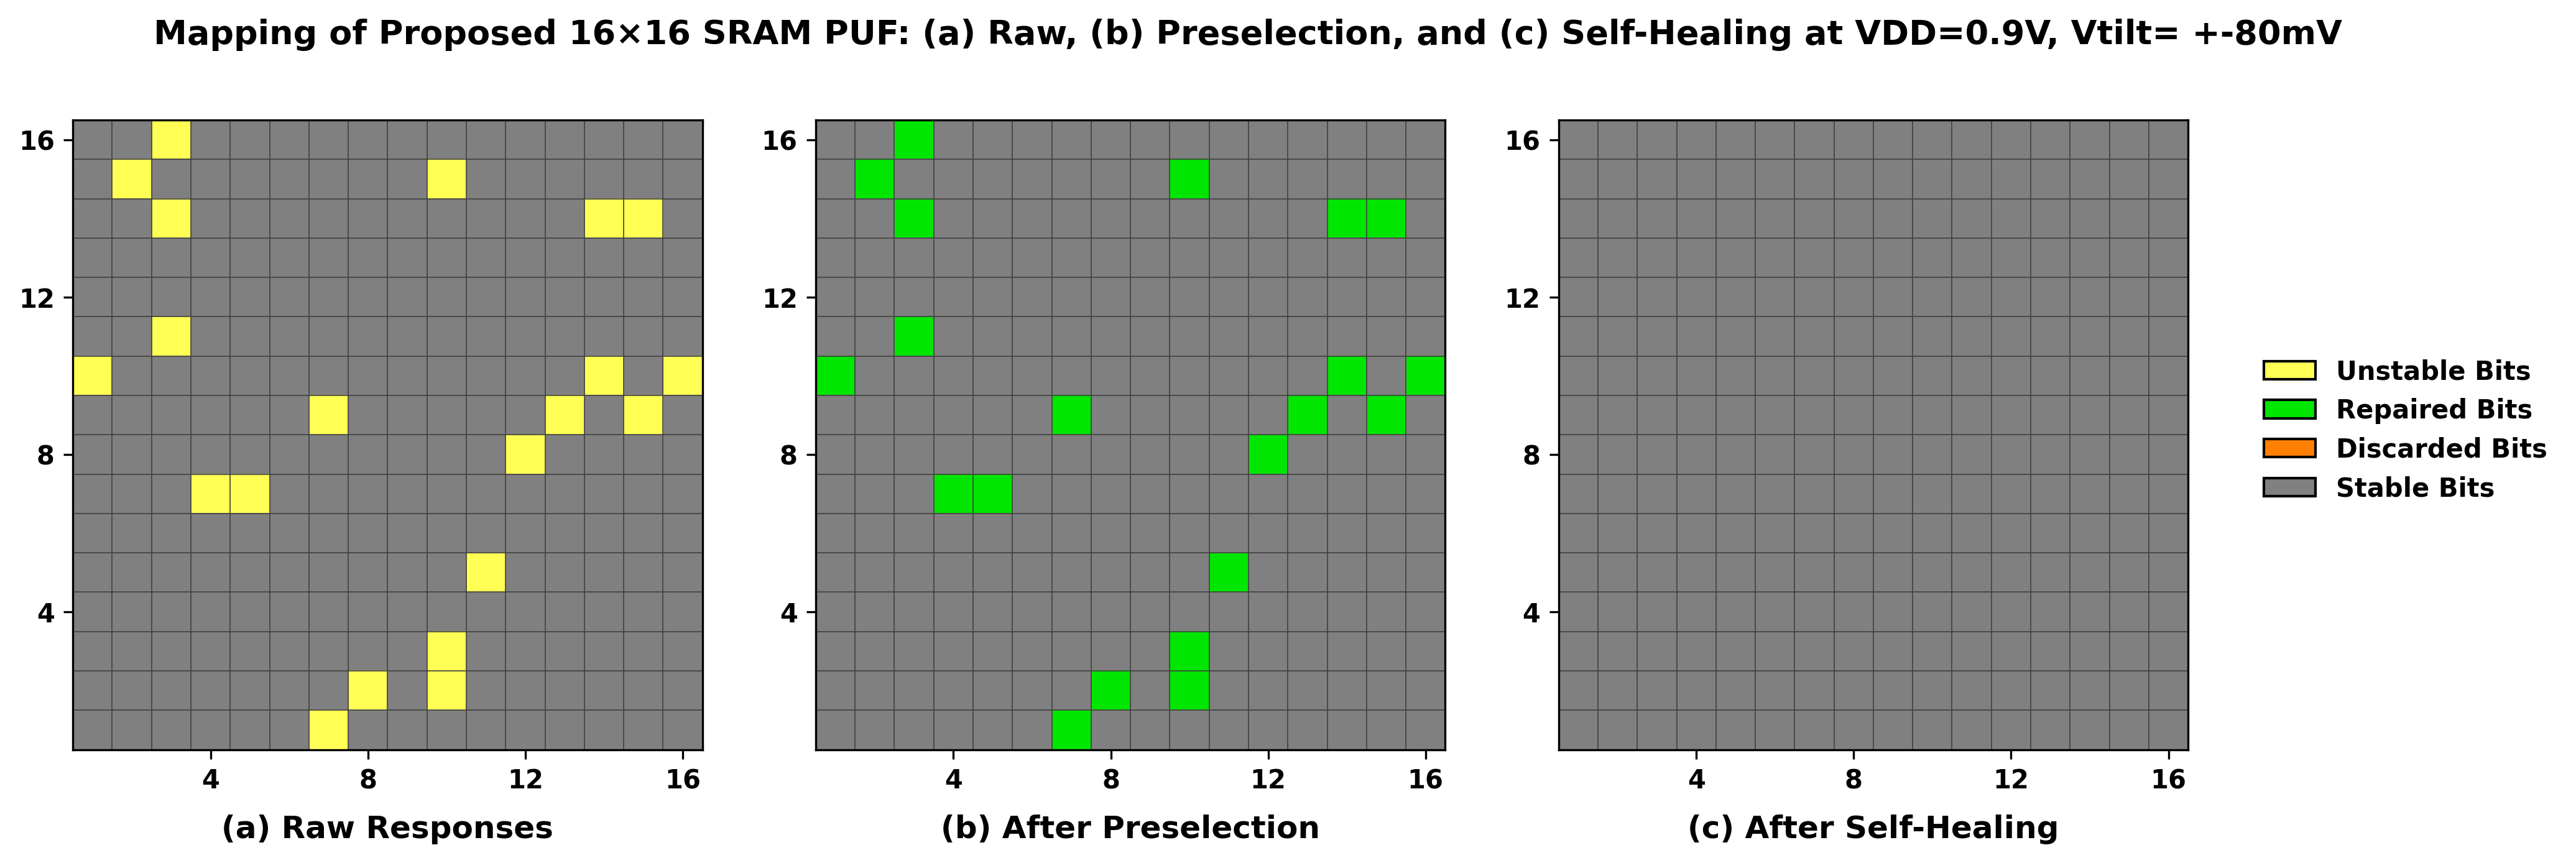

In [20]:
import os
import re
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: INSERT YOUR 3 CSV FILE PATHS HERE
# ==============================================================================
CSV_NOMINAL = "mc_256_0.9_vdd.csv"  # VDDL = VDDR = VDD (0.9V)
CSV_PLUS_80 = "mc_256_0.9_vdd+80.csv"  # VDDL = VDD + 80mV, VDDR = VDD - 80mV
CSV_MINUS_80 = "mc_256_0.9_vdd-80.csv"  # VDDL = VDD - 80mV, VDDR = VDD + 80mV

VDD_NOMINAL = 0.9  # Nominal supply voltage (V)
ARRAY_ROWS = 16  # 16 rows x 16 cols = 256 cells
ARRAY_COLS = 16

# Time windows (in seconds)
MODE2_WINDOW = (37e-9, 43e-9)  # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)  # Mode 1 active window: 97ns - 103ns


# ==============================================================================
# 2. HELPER FUNCTION: EXTRACT MODE 1 & MODE 2 BITS FROM A CADENCE CSV
# ==============================================================================
def extract_bits_from_csv(csv_path, vdd=0.9):
    """Reads BL and BLb waveforms for all 256 Monte Carlo cells and returns

    binary arrays (length 256) for Mode 1 and Mode 2.
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find CSV file: {csv_path}")

    df = pd.read_csv(csv_path, low_memory=False)
    threshold = vdd / 2.0

    # Detect and sort all mcparamset indices (1 to 256)
    paramset_ids = sorted(
        list(
            set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(df.columns)))
        )
    )

    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)
    m1_bl_v = np.zeros(len(paramset_ids), dtype=float)
    m2_bl_v = np.zeros(len(paramset_ids), dtype=float)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) X"], errors="coerce"
        ).values
        v_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce"
        ).values

        # Mode 1 window (97ns - 103ns)
        mask_m1 = (t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])
        v1 = np.nanmean(v_bl[mask_m1])
        m1_bl_v[idx] = v1
        m1_bits[idx] = 1 if v1 >= threshold else 0

        # Mode 2 window (37ns - 43ns)
        mask_m2 = (t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])
        v2 = np.nanmean(v_bl[mask_m2])
        m2_bl_v[idx] = v2
        m2_bits[idx] = 1 if v2 >= threshold else 0

    return {
        "m1_bits": m1_bits,
        "m2_bits": m2_bits,
        "m1_bl_v": m1_bl_v,
        "m2_bl_v": m2_bl_v,
    }


# ==============================================================================
# 3. MAIN ANALYSIS & SELF-HEALING PIPELINE
# ==============================================================================
def run_puf_preselection_analysis(csv_nom, csv_p80, csv_m80, vdd=0.9):
    print("Extracting waveforms from all 3 Cadence CSV files...")
    data_nom = extract_bits_from_csv(csv_nom, vdd)
    data_p80 = extract_bits_from_csv(csv_p80, vdd)
    data_m80 = extract_bits_from_csv(csv_m80, vdd)

    num_cells = len(data_nom["m1_bits"])
    assert (
        num_cells == ARRAY_ROWS * ARRAY_COLS
    ), f"Expected {ARRAY_ROWS*ARRAY_COLS} cells, got {num_cells}"

    # --- STEP 1: Evaluate Mode 1 Stability across both voltage tilts ---
    # A cell is stable in Mode 1 iff Nominal == (+80mV) == (-80mV)
    m1_stable = (data_nom["m1_bits"] == data_p80["m1_bits"]) & (
        data_nom["m1_bits"] == data_m80["m1_bits"]
    )
    m1_unstable = ~m1_stable

    # --- STEP 2: Evaluate Mode 2 Stability for Mode 1 Unstable Cells ---
    # A cell is stable in Mode 2 iff Nominal == (+80mV) == (-80mV)
    m2_stable = (data_nom["m2_bits"] == data_p80["m2_bits"]) & (
        data_nom["m2_bits"] == data_m80["m2_bits"]
    )

    # Classification states:
    # 0 = Stable Bits (Grey)
    # 1 = Unstable Bits (Yellow)
    # 2 = Repaired Bits (Green)
    # 3 = Discarded Bits (Orange)

    # Map (a): Raw Responses (Mode 1 only)
    map_a = np.where(m1_stable, 0, 1)  # 0=Grey (Stable), 1=Yellow (Unstable)

    # Map (b): Responses after Preselection & Mode-2 Healing
    # - Mode 1 Stable -> 0 (Grey: Stable)
    # - Mode 1 Unstable AND Mode 2 Stable -> 2 (Green: Repaired)
    # - Mode 1 Unstable AND Mode 2 Unstable -> 3 (Orange: Discarded)
    repaired_mask = m1_unstable & m2_stable
    discarded_mask = m1_unstable & (~m2_stable)

    map_b = np.zeros(num_cells, dtype=int)
    map_b[m1_stable] = 0  # Stable (Grey)
    map_b[repaired_mask] = 2  # Repaired (Green)
    map_b[discarded_mask] = 3  # Discarded (Orange)

    # Map (c): Active Post-Healing Responses
    # Repaired cells are now active and stable (Grey); Discarded cells remain masked out (or shown as excluded)
    # To match Fig. 10(c) where repaired cells become active stable grey and discarded bits are masked out:
    map_c = np.zeros(num_cells, dtype=int)
    map_c[m1_stable | repaired_mask] = 0  # Active Stable Bits (Grey)
    map_c[discarded_mask] = (
        4  # Masked / Excluded from key (White/Light-Grey background)
    )

    # Reshape 1D arrays (0..255) into 16x16 grids:
    # Row 0 = BL[0:15], Row 1 = BL[16:31], ..., Row 15 = BL[240:255]
    grid_a = map_a.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_b = map_b.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_c = map_c.reshape(ARRAY_ROWS, ARRAY_COLS)

    # ==========================================================================
    # 4. PRINT QUANTITATIVE SUMMARY
    # ==========================================================================
    n_m1_stable = int(np.sum(m1_stable))
    n_m1_unstable = int(np.sum(m1_unstable))
    n_repaired = int(np.sum(repaired_mask))
    n_discarded = int(np.sum(discarded_mask))
    n_final_valid = n_m1_stable + n_repaired

    raw_ber = (n_m1_unstable / num_cells) * 100.0
    healing_rate = (
        (n_repaired / n_m1_unstable * 100.0) if n_m1_unstable > 0 else 100.0
    )
    valid_yield = (n_final_valid / num_cells) * 100.0

    print("\n" + "=" * 68)
    print("  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY")
    print("=" * 68)
    print(f"Total Array Cells                 : {num_cells} (16 x 16)")
    print(
        f"Mode 1 Stable Bits (Grey)         : {n_m1_stable:3d} ({n_m1_stable/num_cells*100:.2f}%)"
    )
    print(
        f"Mode 1 Unstable Bits (Yellow)     : {n_m1_unstable:3d} ({raw_ber:.2f}% Raw Instability)"
    )
    print("-" * 68)
    print(
        f"Repaired via Mode 2 (Green)       : {n_repaired:3d} ({healing_rate:.2f}% of unstable bits healed)"
    )
    print(
        f"Discarded Dark Bits (Orange)      : {n_discarded:3d} ({n_discarded/num_cells*100:.2f}% masked out)"
    )
    print("-" * 68)
    print(
        f"Final Active Valid PUF Bits       : {n_final_valid:3d} / {num_cells} ({valid_yield:.2f}% Valid Bit Yield)"
    )
    print(f"Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)")
    print("=" * 68 + "\n")

    # Save detailed per-cell CSV report
    summary_df = pd.DataFrame(
        {
            "Cell_Index (0-255)": np.arange(num_cells),
            "Row (0-15)": np.arange(num_cells) // ARRAY_COLS,
            "Col (0-15)": np.arange(num_cells) % ARRAY_COLS,
            "M1_Nom": data_nom["m1_bits"],
            "M1_Plus80": data_p80["m1_bits"],
            "M1_Minus80": data_m80["m1_bits"],
            "M1_Stable": m1_stable,
            "M2_Nom": data_nom["m2_bits"],
            "M2_Plus80": data_p80["m2_bits"],
            "M2_Minus80": data_m80["m2_bits"],
            "M2_Stable": m2_stable,
            "Final_Status": np.where(
                m1_stable,
                "Stable (Mode 1)",
                np.where(
                    repaired_mask, "Repaired (Mode 2)", "Discarded (Masked)"
                ),
            ),
            "Selected_Mode": np.where(
                m1_stable, "Mode 1", np.where(repaired_mask, "Mode 2", "None")
            ),
            "Golden_Key_Bit": np.where(
                m1_stable,
                data_nom["m1_bits"],
                np.where(repaired_mask, data_nom["m2_bits"], -1),
            ),
        }
    )
    summary_df.to_csv("puf_self_healing_cell_report.csv", index=False)
    print("Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'")

    # ==========================================================================
    # 5. PLOT FIGURE 10 STYLE 3-PANEL MAPPING
    # ==========================================================================
    # Color palette matching Fig. 10:
    # 0: Grey (#808080) - Stable Bits
    # 1: Yellow (#FFFF54) - Unstable Bits
    # 2: Green (#00FF00) - Repaired Bits
    # 3: Orange (#FF7F0E) - Discarded Bits
    # 4: Light Neutral (#D9D9D9) - Masked/Excluded slots in post-healing map
    cmap = mcolors.ListedColormap(
        ["#808080", "#FFFF54", "#00E600", "#FF7F00", "#B8B8B8"]
    )
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), dpi=300)
    titles = [
        "(a) Raw Responses",
        "(b) After Preselection",
        "(c) After Self-Healing",
    ]
    grids = [grid_a, grid_b, grid_c]

    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap=cmap, norm=norm, origin="lower", aspect="equal")

        # Draw crisp cell grid lines for 16x16 visibility
        ax.set_xticks(np.arange(-0.5, ARRAY_COLS, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, ARRAY_ROWS, 1), minor=True)
        ax.grid(which="minor", color="#404040", linestyle="-", linewidth=0.4)
        ax.tick_params(which="minor", bottom=False, left=False)

        # Major ticks at 4, 8, 12, 16 (1-indexed like Fig. 10)
        ticks = [3, 7, 11, 15]
        tick_labels = ["4", "8", "12", "16"]
        ax.set_xticks(ticks)
        ax.set_xticklabels(tick_labels, fontsize=10, fontweight="bold")
        ax.set_yticks(ticks)
        ax.set_yticklabels(tick_labels, fontsize=10, fontweight="bold")

        ax.set_xlabel(title, fontsize=12, fontweight="bold", labelpad=8)

    # Legend matching Fig. 10
    legend_patches = [
        mpatches.Patch(
            facecolor="#FFFF54", edgecolor="black", label="Unstable Bits"
        ),
        mpatches.Patch(
            facecolor="#00E600", edgecolor="black", label="Repaired Bits"
        ),
        mpatches.Patch(
            facecolor="#FF7F00", edgecolor="black", label="Discarded Bits"
        ),
        mpatches.Patch(
            facecolor="#808080", edgecolor="black", label="Stable Bits"
        ),
    ]
    fig.legend(
        handles=legend_patches,
        loc="center left",
        bbox_to_anchor=(0.88, 0.52),
        frameon=False,
        fontsize=11,
        prop={"weight": "bold"},
    )

    plt.suptitle(
        "Mapping of Proposed 16×16 SRAM PUF: (a) Raw, (b) Preselection, and (c) Self-Healing at VDD=0.9V, Vtilt= +-80mV",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.subplots_adjust(left=0.05, right=0.86, top=0.88, bottom=0.15, wspace=0.18)

    output_fig = "puf_fig10_mapping.png"
    plt.savefig(output_fig, dpi=300, bbox_inches="tight")
    print(f"Saved 3-panel visualization to '{output_fig}'")
    plt.show()


if __name__ == "__main__":
    run_puf_preselection_analysis(
        CSV_NOMINAL, CSV_PLUS_80, CSV_MINUS_80, vdd=VDD_NOMINAL
    )

Extracting waveforms from all 3 Cadence CSV files...

  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY
Total Array Cells                 : 256 (16 x 16)
Mode 1 Stable Bits (Grey)         : 242 (94.53%)
Mode 1 Unstable Bits (Yellow)     :  14 (5.47% Raw Instability)
--------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  14 (100.00% of unstable bits healed)
Discarded Dark Bits (Orange)      :   0 (0.00% masked out)
--------------------------------------------------------------------
Final Active Valid PUF Bits       : 256 / 256 (100.00% Valid Bit Yield)
Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)

Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'
Saved 3-panel visualization to 'puf_fig10_mapping.png'


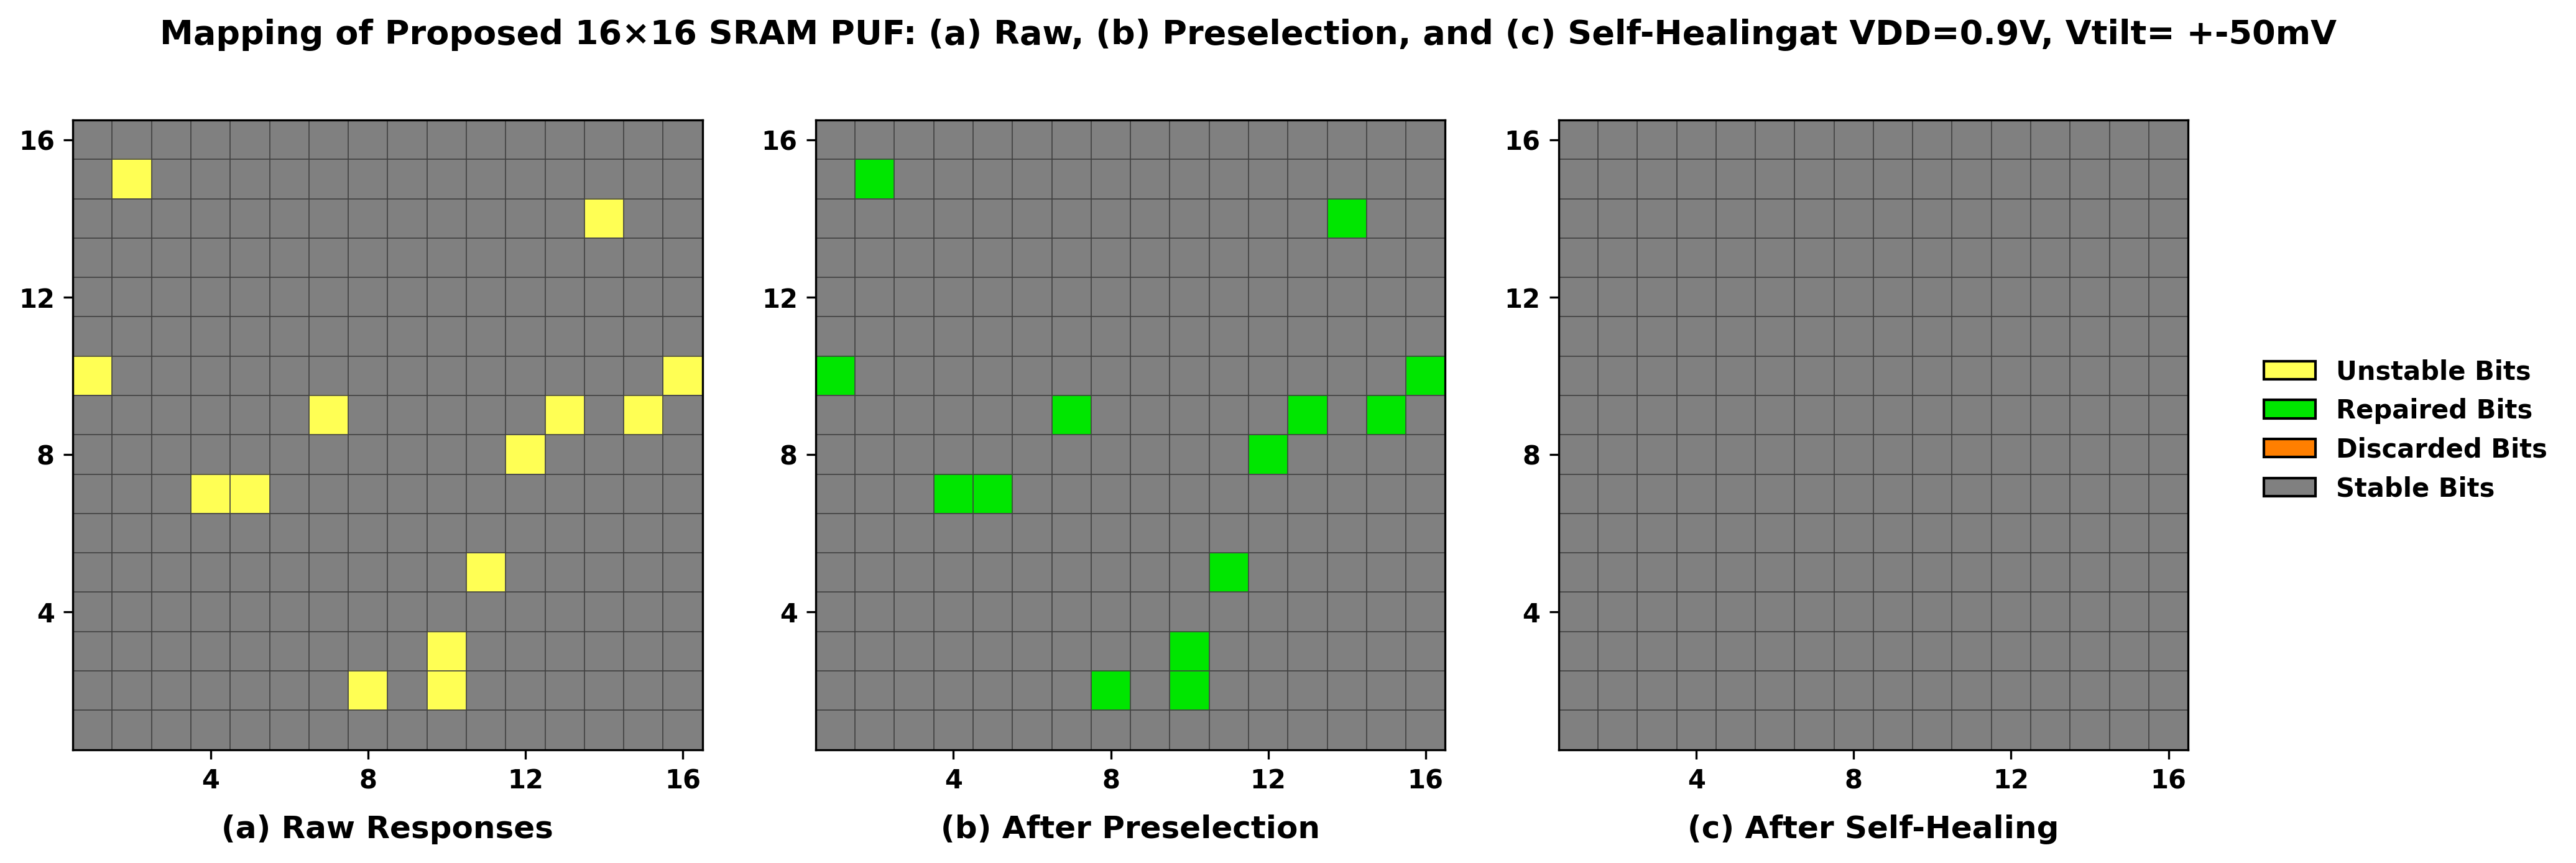

In [21]:
import os
import re
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: INSERT YOUR 3 CSV FILE PATHS HERE
# ==============================================================================
CSV_NOMINAL = "mc_256_0.9_vdd.csv"  # VDDL = VDDR = VDD (0.9V)
CSV_PLUS_80 = "mc_256_0.9_vdd+50.csv"  # VDDL = VDD + 80mV, VDDR = VDD - 80mV
CSV_MINUS_80 = "mc_256_0.9_vdd-50.csv"  # VDDL = VDD - 80mV, VDDR = VDD + 80mV

VDD_NOMINAL = 0.9  # Nominal supply voltage (V)
ARRAY_ROWS = 16  # 16 rows x 16 cols = 256 cells
ARRAY_COLS = 16

# Time windows (in seconds)
MODE2_WINDOW = (37e-9, 43e-9)  # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)  # Mode 1 active window: 97ns - 103ns


# ==============================================================================
# 2. HELPER FUNCTION: EXTRACT MODE 1 & MODE 2 BITS FROM A CADENCE CSV
# ==============================================================================
def extract_bits_from_csv(csv_path, vdd=0.9):
    """Reads BL and BLb waveforms for all 256 Monte Carlo cells and returns

    binary arrays (length 256) for Mode 1 and Mode 2.
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find CSV file: {csv_path}")

    df = pd.read_csv(csv_path, low_memory=False)
    threshold = vdd / 2.0

    # Detect and sort all mcparamset indices (1 to 256)
    paramset_ids = sorted(
        list(
            set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(df.columns)))
        )
    )

    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)
    m1_bl_v = np.zeros(len(paramset_ids), dtype=float)
    m2_bl_v = np.zeros(len(paramset_ids), dtype=float)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) X"], errors="coerce"
        ).values
        v_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce"
        ).values

        # Mode 1 window (97ns - 103ns)
        mask_m1 = (t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])
        v1 = np.nanmean(v_bl[mask_m1])
        m1_bl_v[idx] = v1
        m1_bits[idx] = 1 if v1 >= threshold else 0

        # Mode 2 window (37ns - 43ns)
        mask_m2 = (t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])
        v2 = np.nanmean(v_bl[mask_m2])
        m2_bl_v[idx] = v2
        m2_bits[idx] = 1 if v2 >= threshold else 0

    return {
        "m1_bits": m1_bits,
        "m2_bits": m2_bits,
        "m1_bl_v": m1_bl_v,
        "m2_bl_v": m2_bl_v,
    }


# ==============================================================================
# 3. MAIN ANALYSIS & SELF-HEALING PIPELINE
# ==============================================================================
def run_puf_preselection_analysis(csv_nom, csv_p80, csv_m80, vdd=0.9):
    print("Extracting waveforms from all 3 Cadence CSV files...")
    data_nom = extract_bits_from_csv(csv_nom, vdd)
    data_p80 = extract_bits_from_csv(csv_p80, vdd)
    data_m80 = extract_bits_from_csv(csv_m80, vdd)

    num_cells = len(data_nom["m1_bits"])
    assert (
        num_cells == ARRAY_ROWS * ARRAY_COLS
    ), f"Expected {ARRAY_ROWS*ARRAY_COLS} cells, got {num_cells}"

    # --- STEP 1: Evaluate Mode 1 Stability across both voltage tilts ---
    # A cell is stable in Mode 1 iff Nominal == (+80mV) == (-80mV)
    m1_stable = (data_nom["m1_bits"] == data_p80["m1_bits"]) & (
        data_nom["m1_bits"] == data_m80["m1_bits"]
    )
    m1_unstable = ~m1_stable

    # --- STEP 2: Evaluate Mode 2 Stability for Mode 1 Unstable Cells ---
    # A cell is stable in Mode 2 iff Nominal == (+80mV) == (-80mV)
    m2_stable = (data_nom["m2_bits"] == data_p80["m2_bits"]) & (
        data_nom["m2_bits"] == data_m80["m2_bits"]
    )

    # Classification states:
    # 0 = Stable Bits (Grey)
    # 1 = Unstable Bits (Yellow)
    # 2 = Repaired Bits (Green)
    # 3 = Discarded Bits (Orange)

    # Map (a): Raw Responses (Mode 1 only)
    map_a = np.where(m1_stable, 0, 1)  # 0=Grey (Stable), 1=Yellow (Unstable)

    # Map (b): Responses after Preselection & Mode-2 Healing
    # - Mode 1 Stable -> 0 (Grey: Stable)
    # - Mode 1 Unstable AND Mode 2 Stable -> 2 (Green: Repaired)
    # - Mode 1 Unstable AND Mode 2 Unstable -> 3 (Orange: Discarded)
    repaired_mask = m1_unstable & m2_stable
    discarded_mask = m1_unstable & (~m2_stable)

    map_b = np.zeros(num_cells, dtype=int)
    map_b[m1_stable] = 0  # Stable (Grey)
    map_b[repaired_mask] = 2  # Repaired (Green)
    map_b[discarded_mask] = 3  # Discarded (Orange)

    # Map (c): Active Post-Healing Responses
    # Repaired cells are now active and stable (Grey); Discarded cells remain masked out (or shown as excluded)
    # To match Fig. 10(c) where repaired cells become active stable grey and discarded bits are masked out:
    map_c = np.zeros(num_cells, dtype=int)
    map_c[m1_stable | repaired_mask] = 0  # Active Stable Bits (Grey)
    map_c[discarded_mask] = (
        4  # Masked / Excluded from key (White/Light-Grey background)
    )

    # Reshape 1D arrays (0..255) into 16x16 grids:
    # Row 0 = BL[0:15], Row 1 = BL[16:31], ..., Row 15 = BL[240:255]
    grid_a = map_a.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_b = map_b.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_c = map_c.reshape(ARRAY_ROWS, ARRAY_COLS)

    # ==========================================================================
    # 4. PRINT QUANTITATIVE SUMMARY
    # ==========================================================================
    n_m1_stable = int(np.sum(m1_stable))
    n_m1_unstable = int(np.sum(m1_unstable))
    n_repaired = int(np.sum(repaired_mask))
    n_discarded = int(np.sum(discarded_mask))
    n_final_valid = n_m1_stable + n_repaired

    raw_ber = (n_m1_unstable / num_cells) * 100.0
    healing_rate = (
        (n_repaired / n_m1_unstable * 100.0) if n_m1_unstable > 0 else 100.0
    )
    valid_yield = (n_final_valid / num_cells) * 100.0

    print("\n" + "=" * 68)
    print("  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY")
    print("=" * 68)
    print(f"Total Array Cells                 : {num_cells} (16 x 16)")
    print(
        f"Mode 1 Stable Bits (Grey)         : {n_m1_stable:3d} ({n_m1_stable/num_cells*100:.2f}%)"
    )
    print(
        f"Mode 1 Unstable Bits (Yellow)     : {n_m1_unstable:3d} ({raw_ber:.2f}% Raw Instability)"
    )
    print("-" * 68)
    print(
        f"Repaired via Mode 2 (Green)       : {n_repaired:3d} ({healing_rate:.2f}% of unstable bits healed)"
    )
    print(
        f"Discarded Dark Bits (Orange)      : {n_discarded:3d} ({n_discarded/num_cells*100:.2f}% masked out)"
    )
    print("-" * 68)
    print(
        f"Final Active Valid PUF Bits       : {n_final_valid:3d} / {num_cells} ({valid_yield:.2f}% Valid Bit Yield)"
    )
    print(f"Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)")
    print("=" * 68 + "\n")

    # Save detailed per-cell CSV report
    summary_df = pd.DataFrame(
        {
            "Cell_Index (0-255)": np.arange(num_cells),
            "Row (0-15)": np.arange(num_cells) // ARRAY_COLS,
            "Col (0-15)": np.arange(num_cells) % ARRAY_COLS,
            "M1_Nom": data_nom["m1_bits"],
            "M1_Plus80": data_p80["m1_bits"],
            "M1_Minus80": data_m80["m1_bits"],
            "M1_Stable": m1_stable,
            "M2_Nom": data_nom["m2_bits"],
            "M2_Plus80": data_p80["m2_bits"],
            "M2_Minus80": data_m80["m2_bits"],
            "M2_Stable": m2_stable,
            "Final_Status": np.where(
                m1_stable,
                "Stable (Mode 1)",
                np.where(
                    repaired_mask, "Repaired (Mode 2)", "Discarded (Masked)"
                ),
            ),
            "Selected_Mode": np.where(
                m1_stable, "Mode 1", np.where(repaired_mask, "Mode 2", "None")
            ),
            "Golden_Key_Bit": np.where(
                m1_stable,
                data_nom["m1_bits"],
                np.where(repaired_mask, data_nom["m2_bits"], -1),
            ),
        }
    )
    summary_df.to_csv("puf_self_healing_cell_report.csv", index=False)
    print("Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'")

    # ==========================================================================
    # 5. PLOT FIGURE 10 STYLE 3-PANEL MAPPING
    # ==========================================================================
    # Color palette matching Fig. 10:
    # 0: Grey (#808080) - Stable Bits
    # 1: Yellow (#FFFF54) - Unstable Bits
    # 2: Green (#00FF00) - Repaired Bits
    # 3: Orange (#FF7F0E) - Discarded Bits
    # 4: Light Neutral (#D9D9D9) - Masked/Excluded slots in post-healing map
    cmap = mcolors.ListedColormap(
        ["#808080", "#FFFF54", "#00E600", "#FF7F00", "#B8B8B8"]
    )
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), dpi=300)
    titles = [
        "(a) Raw Responses",
        "(b) After Preselection",
        "(c) After Self-Healing",
    ]
    grids = [grid_a, grid_b, grid_c]

    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap=cmap, norm=norm, origin="lower", aspect="equal")

        # Draw crisp cell grid lines for 16x16 visibility
        ax.set_xticks(np.arange(-0.5, ARRAY_COLS, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, ARRAY_ROWS, 1), minor=True)
        ax.grid(which="minor", color="#404040", linestyle="-", linewidth=0.4)
        ax.tick_params(which="minor", bottom=False, left=False)

        # Major ticks at 4, 8, 12, 16 (1-indexed like Fig. 10)
        ticks = [3, 7, 11, 15]
        tick_labels = ["4", "8", "12", "16"]
        ax.set_xticks(ticks)
        ax.set_xticklabels(tick_labels, fontsize=10, fontweight="bold")
        ax.set_yticks(ticks)
        ax.set_yticklabels(tick_labels, fontsize=10, fontweight="bold")

        ax.set_xlabel(title, fontsize=12, fontweight="bold", labelpad=8)

    # Legend matching Fig. 10
    legend_patches = [
        mpatches.Patch(
            facecolor="#FFFF54", edgecolor="black", label="Unstable Bits"
        ),
        mpatches.Patch(
            facecolor="#00E600", edgecolor="black", label="Repaired Bits"
        ),
        mpatches.Patch(
            facecolor="#FF7F00", edgecolor="black", label="Discarded Bits"
        ),
        mpatches.Patch(
            facecolor="#808080", edgecolor="black", label="Stable Bits"
        ),
    ]
    fig.legend(
        handles=legend_patches,
        loc="center left",
        bbox_to_anchor=(0.88, 0.52),
        frameon=False,
        fontsize=11,
        prop={"weight": "bold"},
    )

    plt.suptitle(
        "Mapping of Proposed 16×16 SRAM PUF: (a) Raw, (b) Preselection, and (c) Self-Healingat VDD=0.9V, Vtilt= +-50mV",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.subplots_adjust(left=0.05, right=0.86, top=0.88, bottom=0.15, wspace=0.18)

    output_fig = "puf_fig10_mapping.png"
    plt.savefig(output_fig, dpi=300, bbox_inches="tight")
    print(f"Saved 3-panel visualization to '{output_fig}'")
    plt.show()


if __name__ == "__main__":
    run_puf_preselection_analysis(
        CSV_NOMINAL, CSV_PLUS_80, CSV_MINUS_80, vdd=VDD_NOMINAL
    )

Extracting waveforms from all 3 Cadence CSV files...

  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY
Total Array Cells                 : 256 (16 x 16)
Mode 1 Stable Bits (Grey)         : 226 (88.28%)
Mode 1 Unstable Bits (Yellow)     :  30 (11.72% Raw Instability)
--------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  29 (96.67% of unstable bits healed)
Discarded Dark Bits (Orange)      :   1 (0.39% masked out)
--------------------------------------------------------------------
Final Active Valid PUF Bits       : 255 / 256 (99.61% Valid Bit Yield)
Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)

Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'
Saved 3-panel visualization to 'puf_fig10_mapping.png'


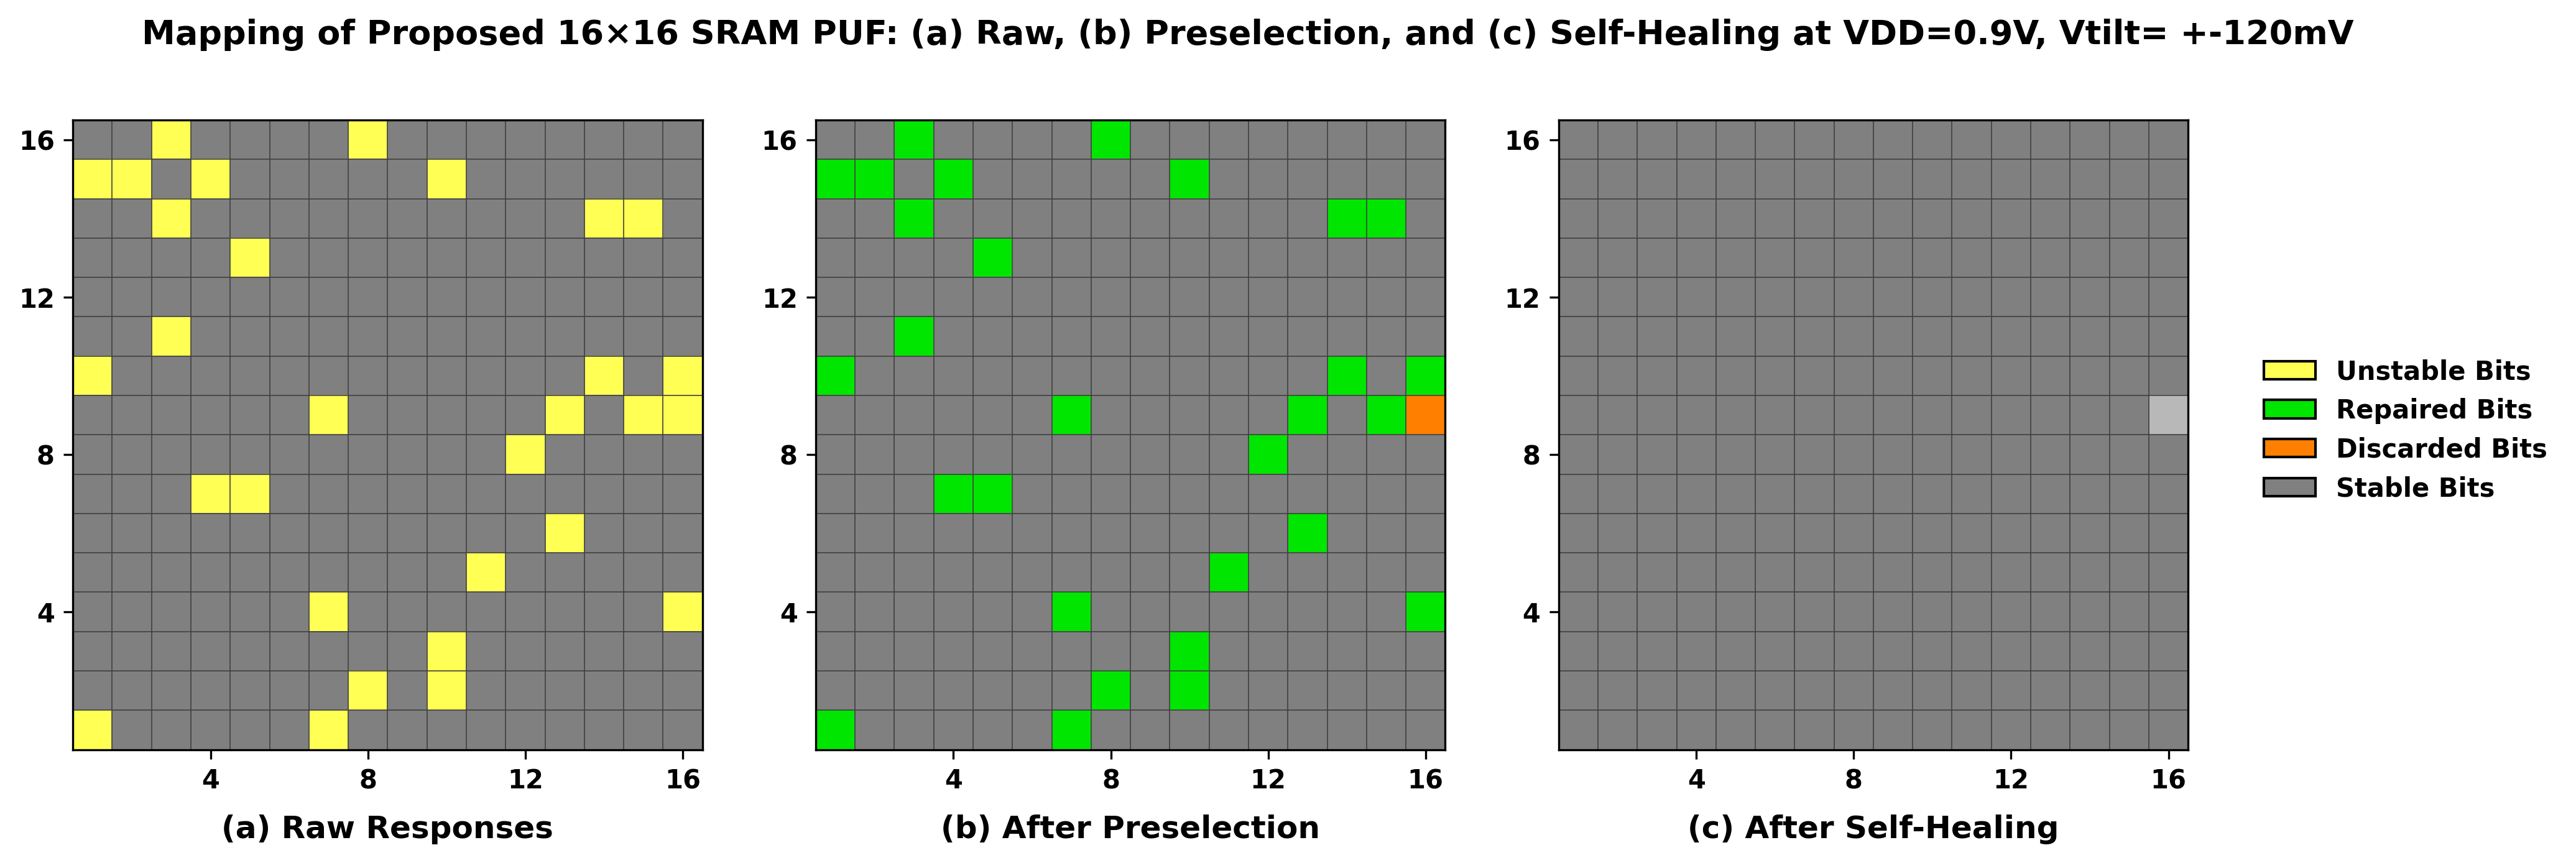

In [22]:
import os
import re
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: INSERT YOUR 3 CSV FILE PATHS HERE
# ==============================================================================
CSV_NOMINAL = "mc_256_0.9_vdd.csv"  # VDDL = VDDR = VDD (0.9V)
CSV_PLUS_80 = "mc_256_0.9_vdd+120.csv"  # VDDL = VDD + 80mV, VDDR = VDD - 80mV
CSV_MINUS_80 = "mc_256_0.9_vdd-120.csv"  # VDDL = VDD - 80mV, VDDR = VDD + 80mV

VDD_NOMINAL = 0.9  # Nominal supply voltage (V)
ARRAY_ROWS = 16  # 16 rows x 16 cols = 256 cells
ARRAY_COLS = 16

# Time windows (in seconds)
MODE2_WINDOW = (37e-9, 43e-9)  # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)  # Mode 1 active window: 97ns - 103ns


# ==============================================================================
# 2. HELPER FUNCTION: EXTRACT MODE 1 & MODE 2 BITS FROM A CADENCE CSV
# ==============================================================================
def extract_bits_from_csv(csv_path, vdd=0.9):
    """Reads BL and BLb waveforms for all 256 Monte Carlo cells and returns

    binary arrays (length 256) for Mode 1 and Mode 2.
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find CSV file: {csv_path}")

    df = pd.read_csv(csv_path, low_memory=False)
    threshold = vdd / 2.0

    # Detect and sort all mcparamset indices (1 to 256)
    paramset_ids = sorted(
        list(
            set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(df.columns)))
        )
    )

    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)
    m1_bl_v = np.zeros(len(paramset_ids), dtype=float)
    m2_bl_v = np.zeros(len(paramset_ids), dtype=float)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) X"], errors="coerce"
        ).values
        v_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce"
        ).values

        # Mode 1 window (97ns - 103ns)
        mask_m1 = (t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])
        v1 = np.nanmean(v_bl[mask_m1])
        m1_bl_v[idx] = v1
        m1_bits[idx] = 1 if v1 >= threshold else 0

        # Mode 2 window (37ns - 43ns)
        mask_m2 = (t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])
        v2 = np.nanmean(v_bl[mask_m2])
        m2_bl_v[idx] = v2
        m2_bits[idx] = 1 if v2 >= threshold else 0

    return {
        "m1_bits": m1_bits,
        "m2_bits": m2_bits,
        "m1_bl_v": m1_bl_v,
        "m2_bl_v": m2_bl_v,
    }


# ==============================================================================
# 3. MAIN ANALYSIS & SELF-HEALING PIPELINE
# ==============================================================================
def run_puf_preselection_analysis(csv_nom, csv_p80, csv_m80, vdd=0.9):
    print("Extracting waveforms from all 3 Cadence CSV files...")
    data_nom = extract_bits_from_csv(csv_nom, vdd)
    data_p80 = extract_bits_from_csv(csv_p80, vdd)
    data_m80 = extract_bits_from_csv(csv_m80, vdd)

    num_cells = len(data_nom["m1_bits"])
    assert (
        num_cells == ARRAY_ROWS * ARRAY_COLS
    ), f"Expected {ARRAY_ROWS*ARRAY_COLS} cells, got {num_cells}"

    # --- STEP 1: Evaluate Mode 1 Stability across both voltage tilts ---
    # A cell is stable in Mode 1 iff Nominal == (+80mV) == (-80mV)
    m1_stable = (data_nom["m1_bits"] == data_p80["m1_bits"]) & (
        data_nom["m1_bits"] == data_m80["m1_bits"]
    )
    m1_unstable = ~m1_stable

    # --- STEP 2: Evaluate Mode 2 Stability for Mode 1 Unstable Cells ---
    # A cell is stable in Mode 2 iff Nominal == (+80mV) == (-80mV)
    m2_stable = (data_nom["m2_bits"] == data_p80["m2_bits"]) & (
        data_nom["m2_bits"] == data_m80["m2_bits"]
    )

    # Classification states:
    # 0 = Stable Bits (Grey)
    # 1 = Unstable Bits (Yellow)
    # 2 = Repaired Bits (Green)
    # 3 = Discarded Bits (Orange)

    # Map (a): Raw Responses (Mode 1 only)
    map_a = np.where(m1_stable, 0, 1)  # 0=Grey (Stable), 1=Yellow (Unstable)

    # Map (b): Responses after Preselection & Mode-2 Healing
    # - Mode 1 Stable -> 0 (Grey: Stable)
    # - Mode 1 Unstable AND Mode 2 Stable -> 2 (Green: Repaired)
    # - Mode 1 Unstable AND Mode 2 Unstable -> 3 (Orange: Discarded)
    repaired_mask = m1_unstable & m2_stable
    discarded_mask = m1_unstable & (~m2_stable)

    map_b = np.zeros(num_cells, dtype=int)
    map_b[m1_stable] = 0  # Stable (Grey)
    map_b[repaired_mask] = 2  # Repaired (Green)
    map_b[discarded_mask] = 3  # Discarded (Orange)

    # Map (c): Active Post-Healing Responses
    # Repaired cells are now active and stable (Grey); Discarded cells remain masked out (or shown as excluded)
    # To match Fig. 10(c) where repaired cells become active stable grey and discarded bits are masked out:
    map_c = np.zeros(num_cells, dtype=int)
    map_c[m1_stable | repaired_mask] = 0  # Active Stable Bits (Grey)
    map_c[discarded_mask] = (
        4  # Masked / Excluded from key (White/Light-Grey background)
    )

    # Reshape 1D arrays (0..255) into 16x16 grids:
    # Row 0 = BL[0:15], Row 1 = BL[16:31], ..., Row 15 = BL[240:255]
    grid_a = map_a.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_b = map_b.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_c = map_c.reshape(ARRAY_ROWS, ARRAY_COLS)

    # ==========================================================================
    # 4. PRINT QUANTITATIVE SUMMARY
    # ==========================================================================
    n_m1_stable = int(np.sum(m1_stable))
    n_m1_unstable = int(np.sum(m1_unstable))
    n_repaired = int(np.sum(repaired_mask))
    n_discarded = int(np.sum(discarded_mask))
    n_final_valid = n_m1_stable + n_repaired

    raw_ber = (n_m1_unstable / num_cells) * 100.0
    healing_rate = (
        (n_repaired / n_m1_unstable * 100.0) if n_m1_unstable > 0 else 100.0
    )
    valid_yield = (n_final_valid / num_cells) * 100.0

    print("\n" + "=" * 68)
    print("  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY")
    print("=" * 68)
    print(f"Total Array Cells                 : {num_cells} (16 x 16)")
    print(
        f"Mode 1 Stable Bits (Grey)         : {n_m1_stable:3d} ({n_m1_stable/num_cells*100:.2f}%)"
    )
    print(
        f"Mode 1 Unstable Bits (Yellow)     : {n_m1_unstable:3d} ({raw_ber:.2f}% Raw Instability)"
    )
    print("-" * 68)
    print(
        f"Repaired via Mode 2 (Green)       : {n_repaired:3d} ({healing_rate:.2f}% of unstable bits healed)"
    )
    print(
        f"Discarded Dark Bits (Orange)      : {n_discarded:3d} ({n_discarded/num_cells*100:.2f}% masked out)"
    )
    print("-" * 68)
    print(
        f"Final Active Valid PUF Bits       : {n_final_valid:3d} / {num_cells} ({valid_yield:.2f}% Valid Bit Yield)"
    )
    print(f"Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)")
    print("=" * 68 + "\n")

    # Save detailed per-cell CSV report
    summary_df = pd.DataFrame(
        {
            "Cell_Index (0-255)": np.arange(num_cells),
            "Row (0-15)": np.arange(num_cells) // ARRAY_COLS,
            "Col (0-15)": np.arange(num_cells) % ARRAY_COLS,
            "M1_Nom": data_nom["m1_bits"],
            "M1_Plus80": data_p80["m1_bits"],
            "M1_Minus80": data_m80["m1_bits"],
            "M1_Stable": m1_stable,
            "M2_Nom": data_nom["m2_bits"],
            "M2_Plus80": data_p80["m2_bits"],
            "M2_Minus80": data_m80["m2_bits"],
            "M2_Stable": m2_stable,
            "Final_Status": np.where(
                m1_stable,
                "Stable (Mode 1)",
                np.where(
                    repaired_mask, "Repaired (Mode 2)", "Discarded (Masked)"
                ),
            ),
            "Selected_Mode": np.where(
                m1_stable, "Mode 1", np.where(repaired_mask, "Mode 2", "None")
            ),
            "Golden_Key_Bit": np.where(
                m1_stable,
                data_nom["m1_bits"],
                np.where(repaired_mask, data_nom["m2_bits"], -1),
            ),
        }
    )
    summary_df.to_csv("puf_self_healing_cell_report.csv", index=False)
    print("Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'")

    # ==========================================================================
    # 5. PLOT FIGURE 10 STYLE 3-PANEL MAPPING
    # ==========================================================================
    # Color palette matching Fig. 10:
    # 0: Grey (#808080) - Stable Bits
    # 1: Yellow (#FFFF54) - Unstable Bits
    # 2: Green (#00FF00) - Repaired Bits
    # 3: Orange (#FF7F0E) - Discarded Bits
    # 4: Light Neutral (#D9D9D9) - Masked/Excluded slots in post-healing map
    cmap = mcolors.ListedColormap(
        ["#808080", "#FFFF54", "#00E600", "#FF7F00", "#B8B8B8"]
    )
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), dpi=300)
    titles = [
        "(a) Raw Responses",
        "(b) After Preselection",
        "(c) After Self-Healing",
    ]
    grids = [grid_a, grid_b, grid_c]

    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap=cmap, norm=norm, origin="lower", aspect="equal")

        # Draw crisp cell grid lines for 16x16 visibility
        ax.set_xticks(np.arange(-0.5, ARRAY_COLS, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, ARRAY_ROWS, 1), minor=True)
        ax.grid(which="minor", color="#404040", linestyle="-", linewidth=0.4)
        ax.tick_params(which="minor", bottom=False, left=False)

        # Major ticks at 4, 8, 12, 16 (1-indexed like Fig. 10)
        ticks = [3, 7, 11, 15]
        tick_labels = ["4", "8", "12", "16"]
        ax.set_xticks(ticks)
        ax.set_xticklabels(tick_labels, fontsize=10, fontweight="bold")
        ax.set_yticks(ticks)
        ax.set_yticklabels(tick_labels, fontsize=10, fontweight="bold")

        ax.set_xlabel(title, fontsize=12, fontweight="bold", labelpad=8)

    # Legend matching Fig. 10
    legend_patches = [
        mpatches.Patch(
            facecolor="#FFFF54", edgecolor="black", label="Unstable Bits"
        ),
        mpatches.Patch(
            facecolor="#00E600", edgecolor="black", label="Repaired Bits"
        ),
        mpatches.Patch(
            facecolor="#FF7F00", edgecolor="black", label="Discarded Bits"
        ),
        mpatches.Patch(
            facecolor="#808080", edgecolor="black", label="Stable Bits"
        ),
    ]
    fig.legend(
        handles=legend_patches,
        loc="center left",
        bbox_to_anchor=(0.88, 0.52),
        frameon=False,
        fontsize=11,
        prop={"weight": "bold"},
    )

    plt.suptitle(
        "Mapping of Proposed 16×16 SRAM PUF: (a) Raw, (b) Preselection, and (c) Self-Healing at VDD=0.9V, Vtilt= +-120mV",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.subplots_adjust(left=0.05, right=0.86, top=0.88, bottom=0.15, wspace=0.18)

    output_fig = "puf_fig10_mapping.png"
    plt.savefig(output_fig, dpi=300, bbox_inches="tight")
    print(f"Saved 3-panel visualization to '{output_fig}'")
    plt.show()


if __name__ == "__main__":
    run_puf_preselection_analysis(
        CSV_NOMINAL, CSV_PLUS_80, CSV_MINUS_80, vdd=VDD_NOMINAL
    )

Extracting waveforms from all 3 Cadence CSV files...

  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY
Total Array Cells                 : 256 (16 x 16)
Mode 1 Stable Bits (Grey)         : 233 (91.02%)
Mode 1 Unstable Bits (Yellow)     :  23 (8.98% Raw Instability)
--------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  22 (95.65% of unstable bits healed)
Discarded Dark Bits (Orange)      :   1 (0.39% masked out)
--------------------------------------------------------------------
Final Active Valid PUF Bits       : 255 / 256 (99.61% Valid Bit Yield)
Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)

Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'
Saved 3-panel visualization to 'puf_fig10_mapping.png'


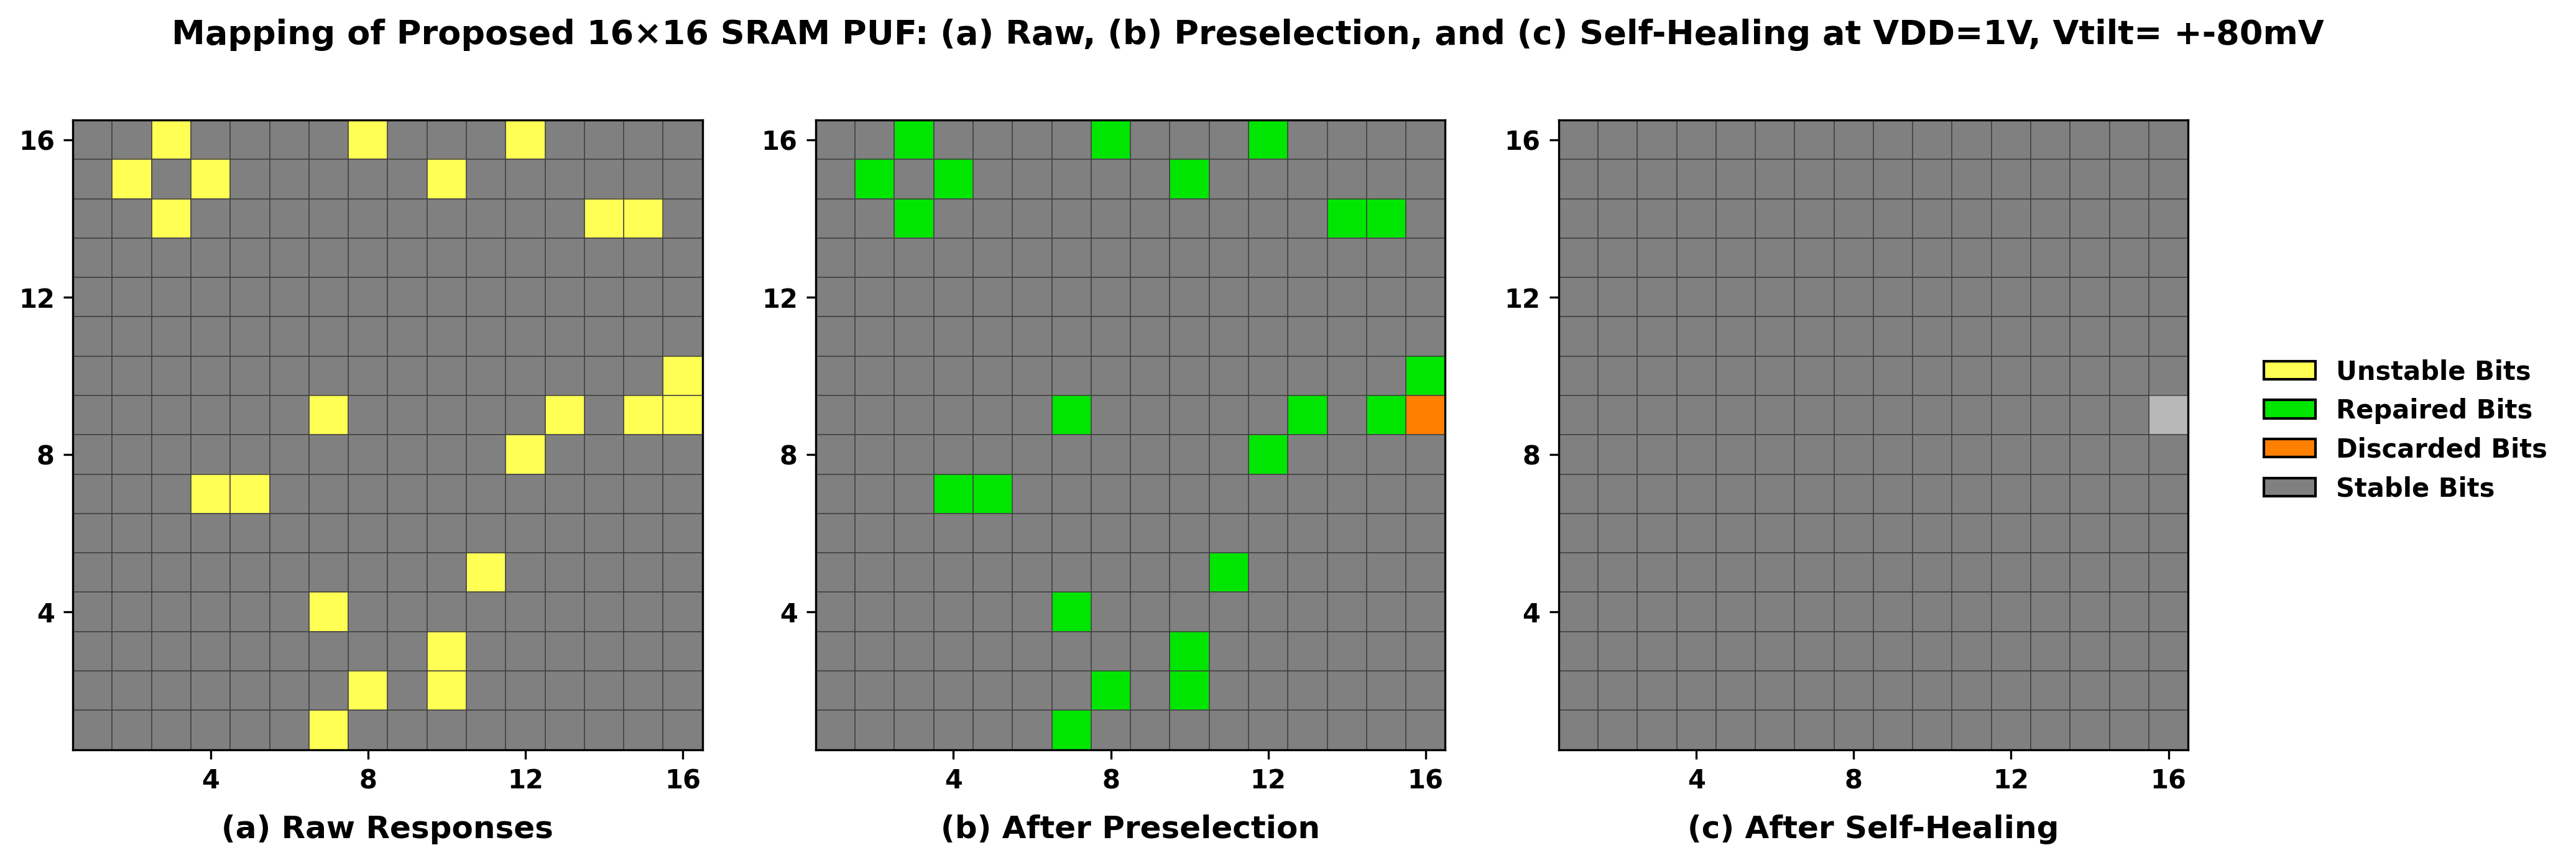

In [23]:
import os
import re
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: INSERT YOUR 3 CSV FILE PATHS HERE
# ==============================================================================
CSV_NOMINAL = "mc_256_1.0_vdd.csv"  # VDDL = VDDR = VDD (0.9V)
CSV_PLUS_80 = "mc_256_1.0_vdd+80.csv"  # VDDL = VDD + 80mV, VDDR = VDD - 80mV
CSV_MINUS_80 = "mc_256_1.0_vdd-80.csv"  # VDDL = VDD - 80mV, VDDR = VDD + 80mV

VDD_NOMINAL = 0.9  # Nominal supply voltage (V)
ARRAY_ROWS = 16  # 16 rows x 16 cols = 256 cells
ARRAY_COLS = 16

# Time windows (in seconds)
MODE2_WINDOW = (37e-9, 43e-9)  # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)  # Mode 1 active window: 97ns - 103ns


# ==============================================================================
# 2. HELPER FUNCTION: EXTRACT MODE 1 & MODE 2 BITS FROM A CADENCE CSV
# ==============================================================================
def extract_bits_from_csv(csv_path, vdd=0.9):
    """Reads BL and BLb waveforms for all 256 Monte Carlo cells and returns

    binary arrays (length 256) for Mode 1 and Mode 2.
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find CSV file: {csv_path}")

    df = pd.read_csv(csv_path, low_memory=False)
    threshold = vdd / 2.0

    # Detect and sort all mcparamset indices (1 to 256)
    paramset_ids = sorted(
        list(
            set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(df.columns)))
        )
    )

    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)
    m1_bl_v = np.zeros(len(paramset_ids), dtype=float)
    m2_bl_v = np.zeros(len(paramset_ids), dtype=float)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) X"], errors="coerce"
        ).values
        v_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce"
        ).values

        # Mode 1 window (97ns - 103ns)
        mask_m1 = (t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])
        v1 = np.nanmean(v_bl[mask_m1])
        m1_bl_v[idx] = v1
        m1_bits[idx] = 1 if v1 >= threshold else 0

        # Mode 2 window (37ns - 43ns)
        mask_m2 = (t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])
        v2 = np.nanmean(v_bl[mask_m2])
        m2_bl_v[idx] = v2
        m2_bits[idx] = 1 if v2 >= threshold else 0

    return {
        "m1_bits": m1_bits,
        "m2_bits": m2_bits,
        "m1_bl_v": m1_bl_v,
        "m2_bl_v": m2_bl_v,
    }


# ==============================================================================
# 3. MAIN ANALYSIS & SELF-HEALING PIPELINE
# ==============================================================================
def run_puf_preselection_analysis(csv_nom, csv_p80, csv_m80, vdd=0.9):
    print("Extracting waveforms from all 3 Cadence CSV files...")
    data_nom = extract_bits_from_csv(csv_nom, vdd)
    data_p80 = extract_bits_from_csv(csv_p80, vdd)
    data_m80 = extract_bits_from_csv(csv_m80, vdd)

    num_cells = len(data_nom["m1_bits"])
    assert (
        num_cells == ARRAY_ROWS * ARRAY_COLS
    ), f"Expected {ARRAY_ROWS*ARRAY_COLS} cells, got {num_cells}"

    # --- STEP 1: Evaluate Mode 1 Stability across both voltage tilts ---
    # A cell is stable in Mode 1 iff Nominal == (+80mV) == (-80mV)
    m1_stable = (data_nom["m1_bits"] == data_p80["m1_bits"]) & (
        data_nom["m1_bits"] == data_m80["m1_bits"]
    )
    m1_unstable = ~m1_stable

    # --- STEP 2: Evaluate Mode 2 Stability for Mode 1 Unstable Cells ---
    # A cell is stable in Mode 2 iff Nominal == (+80mV) == (-80mV)
    m2_stable = (data_nom["m2_bits"] == data_p80["m2_bits"]) & (
        data_nom["m2_bits"] == data_m80["m2_bits"]
    )

    # Classification states:
    # 0 = Stable Bits (Grey)
    # 1 = Unstable Bits (Yellow)
    # 2 = Repaired Bits (Green)
    # 3 = Discarded Bits (Orange)

    # Map (a): Raw Responses (Mode 1 only)
    map_a = np.where(m1_stable, 0, 1)  # 0=Grey (Stable), 1=Yellow (Unstable)

    # Map (b): Responses after Preselection & Mode-2 Healing
    # - Mode 1 Stable -> 0 (Grey: Stable)
    # - Mode 1 Unstable AND Mode 2 Stable -> 2 (Green: Repaired)
    # - Mode 1 Unstable AND Mode 2 Unstable -> 3 (Orange: Discarded)
    repaired_mask = m1_unstable & m2_stable
    discarded_mask = m1_unstable & (~m2_stable)

    map_b = np.zeros(num_cells, dtype=int)
    map_b[m1_stable] = 0  # Stable (Grey)
    map_b[repaired_mask] = 2  # Repaired (Green)
    map_b[discarded_mask] = 3  # Discarded (Orange)

    # Map (c): Active Post-Healing Responses
    # Repaired cells are now active and stable (Grey); Discarded cells remain masked out (or shown as excluded)
    # To match Fig. 10(c) where repaired cells become active stable grey and discarded bits are masked out:
    map_c = np.zeros(num_cells, dtype=int)
    map_c[m1_stable | repaired_mask] = 0  # Active Stable Bits (Grey)
    map_c[discarded_mask] = (
        4  # Masked / Excluded from key (White/Light-Grey background)
    )

    # Reshape 1D arrays (0..255) into 16x16 grids:
    # Row 0 = BL[0:15], Row 1 = BL[16:31], ..., Row 15 = BL[240:255]
    grid_a = map_a.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_b = map_b.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_c = map_c.reshape(ARRAY_ROWS, ARRAY_COLS)

    # ==========================================================================
    # 4. PRINT QUANTITATIVE SUMMARY
    # ==========================================================================
    n_m1_stable = int(np.sum(m1_stable))
    n_m1_unstable = int(np.sum(m1_unstable))
    n_repaired = int(np.sum(repaired_mask))
    n_discarded = int(np.sum(discarded_mask))
    n_final_valid = n_m1_stable + n_repaired

    raw_ber = (n_m1_unstable / num_cells) * 100.0
    healing_rate = (
        (n_repaired / n_m1_unstable * 100.0) if n_m1_unstable > 0 else 100.0
    )
    valid_yield = (n_final_valid / num_cells) * 100.0

    print("\n" + "=" * 68)
    print("  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY")
    print("=" * 68)
    print(f"Total Array Cells                 : {num_cells} (16 x 16)")
    print(
        f"Mode 1 Stable Bits (Grey)         : {n_m1_stable:3d} ({n_m1_stable/num_cells*100:.2f}%)"
    )
    print(
        f"Mode 1 Unstable Bits (Yellow)     : {n_m1_unstable:3d} ({raw_ber:.2f}% Raw Instability)"
    )
    print("-" * 68)
    print(
        f"Repaired via Mode 2 (Green)       : {n_repaired:3d} ({healing_rate:.2f}% of unstable bits healed)"
    )
    print(
        f"Discarded Dark Bits (Orange)      : {n_discarded:3d} ({n_discarded/num_cells*100:.2f}% masked out)"
    )
    print("-" * 68)
    print(
        f"Final Active Valid PUF Bits       : {n_final_valid:3d} / {num_cells} ({valid_yield:.2f}% Valid Bit Yield)"
    )
    print(f"Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)")
    print("=" * 68 + "\n")

    # Save detailed per-cell CSV report
    summary_df = pd.DataFrame(
        {
            "Cell_Index (0-255)": np.arange(num_cells),
            "Row (0-15)": np.arange(num_cells) // ARRAY_COLS,
            "Col (0-15)": np.arange(num_cells) % ARRAY_COLS,
            "M1_Nom": data_nom["m1_bits"],
            "M1_Plus80": data_p80["m1_bits"],
            "M1_Minus80": data_m80["m1_bits"],
            "M1_Stable": m1_stable,
            "M2_Nom": data_nom["m2_bits"],
            "M2_Plus80": data_p80["m2_bits"],
            "M2_Minus80": data_m80["m2_bits"],
            "M2_Stable": m2_stable,
            "Final_Status": np.where(
                m1_stable,
                "Stable (Mode 1)",
                np.where(
                    repaired_mask, "Repaired (Mode 2)", "Discarded (Masked)"
                ),
            ),
            "Selected_Mode": np.where(
                m1_stable, "Mode 1", np.where(repaired_mask, "Mode 2", "None")
            ),
            "Golden_Key_Bit": np.where(
                m1_stable,
                data_nom["m1_bits"],
                np.where(repaired_mask, data_nom["m2_bits"], -1),
            ),
        }
    )
    summary_df.to_csv("puf_self_healing_cell_report.csv", index=False)
    print("Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'")

    # ==========================================================================
    # 5. PLOT FIGURE 10 STYLE 3-PANEL MAPPING
    # ==========================================================================
    # Color palette matching Fig. 10:
    # 0: Grey (#808080) - Stable Bits
    # 1: Yellow (#FFFF54) - Unstable Bits
    # 2: Green (#00FF00) - Repaired Bits
    # 3: Orange (#FF7F0E) - Discarded Bits
    # 4: Light Neutral (#D9D9D9) - Masked/Excluded slots in post-healing map
    cmap = mcolors.ListedColormap(
        ["#808080", "#FFFF54", "#00E600", "#FF7F00", "#B8B8B8"]
    )
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), dpi=300)
    titles = [
        "(a) Raw Responses",
        "(b) After Preselection",
        "(c) After Self-Healing",
    ]
    grids = [grid_a, grid_b, grid_c]

    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap=cmap, norm=norm, origin="lower", aspect="equal")

        # Draw crisp cell grid lines for 16x16 visibility
        ax.set_xticks(np.arange(-0.5, ARRAY_COLS, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, ARRAY_ROWS, 1), minor=True)
        ax.grid(which="minor", color="#404040", linestyle="-", linewidth=0.4)
        ax.tick_params(which="minor", bottom=False, left=False)

        # Major ticks at 4, 8, 12, 16 (1-indexed like Fig. 10)
        ticks = [3, 7, 11, 15]
        tick_labels = ["4", "8", "12", "16"]
        ax.set_xticks(ticks)
        ax.set_xticklabels(tick_labels, fontsize=10, fontweight="bold")
        ax.set_yticks(ticks)
        ax.set_yticklabels(tick_labels, fontsize=10, fontweight="bold")

        ax.set_xlabel(title, fontsize=12, fontweight="bold", labelpad=8)

    # Legend matching Fig. 10
    legend_patches = [
        mpatches.Patch(
            facecolor="#FFFF54", edgecolor="black", label="Unstable Bits"
        ),
        mpatches.Patch(
            facecolor="#00E600", edgecolor="black", label="Repaired Bits"
        ),
        mpatches.Patch(
            facecolor="#FF7F00", edgecolor="black", label="Discarded Bits"
        ),
        mpatches.Patch(
            facecolor="#808080", edgecolor="black", label="Stable Bits"
        ),
    ]
    fig.legend(
        handles=legend_patches,
        loc="center left",
        bbox_to_anchor=(0.88, 0.52),
        frameon=False,
        fontsize=11,
        prop={"weight": "bold"},
    )

    plt.suptitle(
        "Mapping of Proposed 16×16 SRAM PUF: (a) Raw, (b) Preselection, and (c) Self-Healing at VDD=1V, Vtilt= +-80mV",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.subplots_adjust(left=0.05, right=0.86, top=0.88, bottom=0.15, wspace=0.18)

    output_fig = "puf_fig10_mapping.png"
    plt.savefig(output_fig, dpi=300, bbox_inches="tight")
    print(f"Saved 3-panel visualization to '{output_fig}'")
    plt.show()


if __name__ == "__main__":
    run_puf_preselection_analysis(
        CSV_NOMINAL, CSV_PLUS_80, CSV_MINUS_80, vdd=VDD_NOMINAL
    )

Extracting waveforms from all 3 Cadence CSV files...

  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY
Total Array Cells                 : 256 (16 x 16)
Mode 1 Stable Bits (Grey)         : 237 (92.58%)
Mode 1 Unstable Bits (Yellow)     :  19 (7.42% Raw Instability)
--------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  19 (100.00% of unstable bits healed)
Discarded Dark Bits (Orange)      :   0 (0.00% masked out)
--------------------------------------------------------------------
Final Active Valid PUF Bits       : 256 / 256 (100.00% Valid Bit Yield)
Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)

Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'
Saved 3-panel visualization to 'puf_fig10_mapping.png'


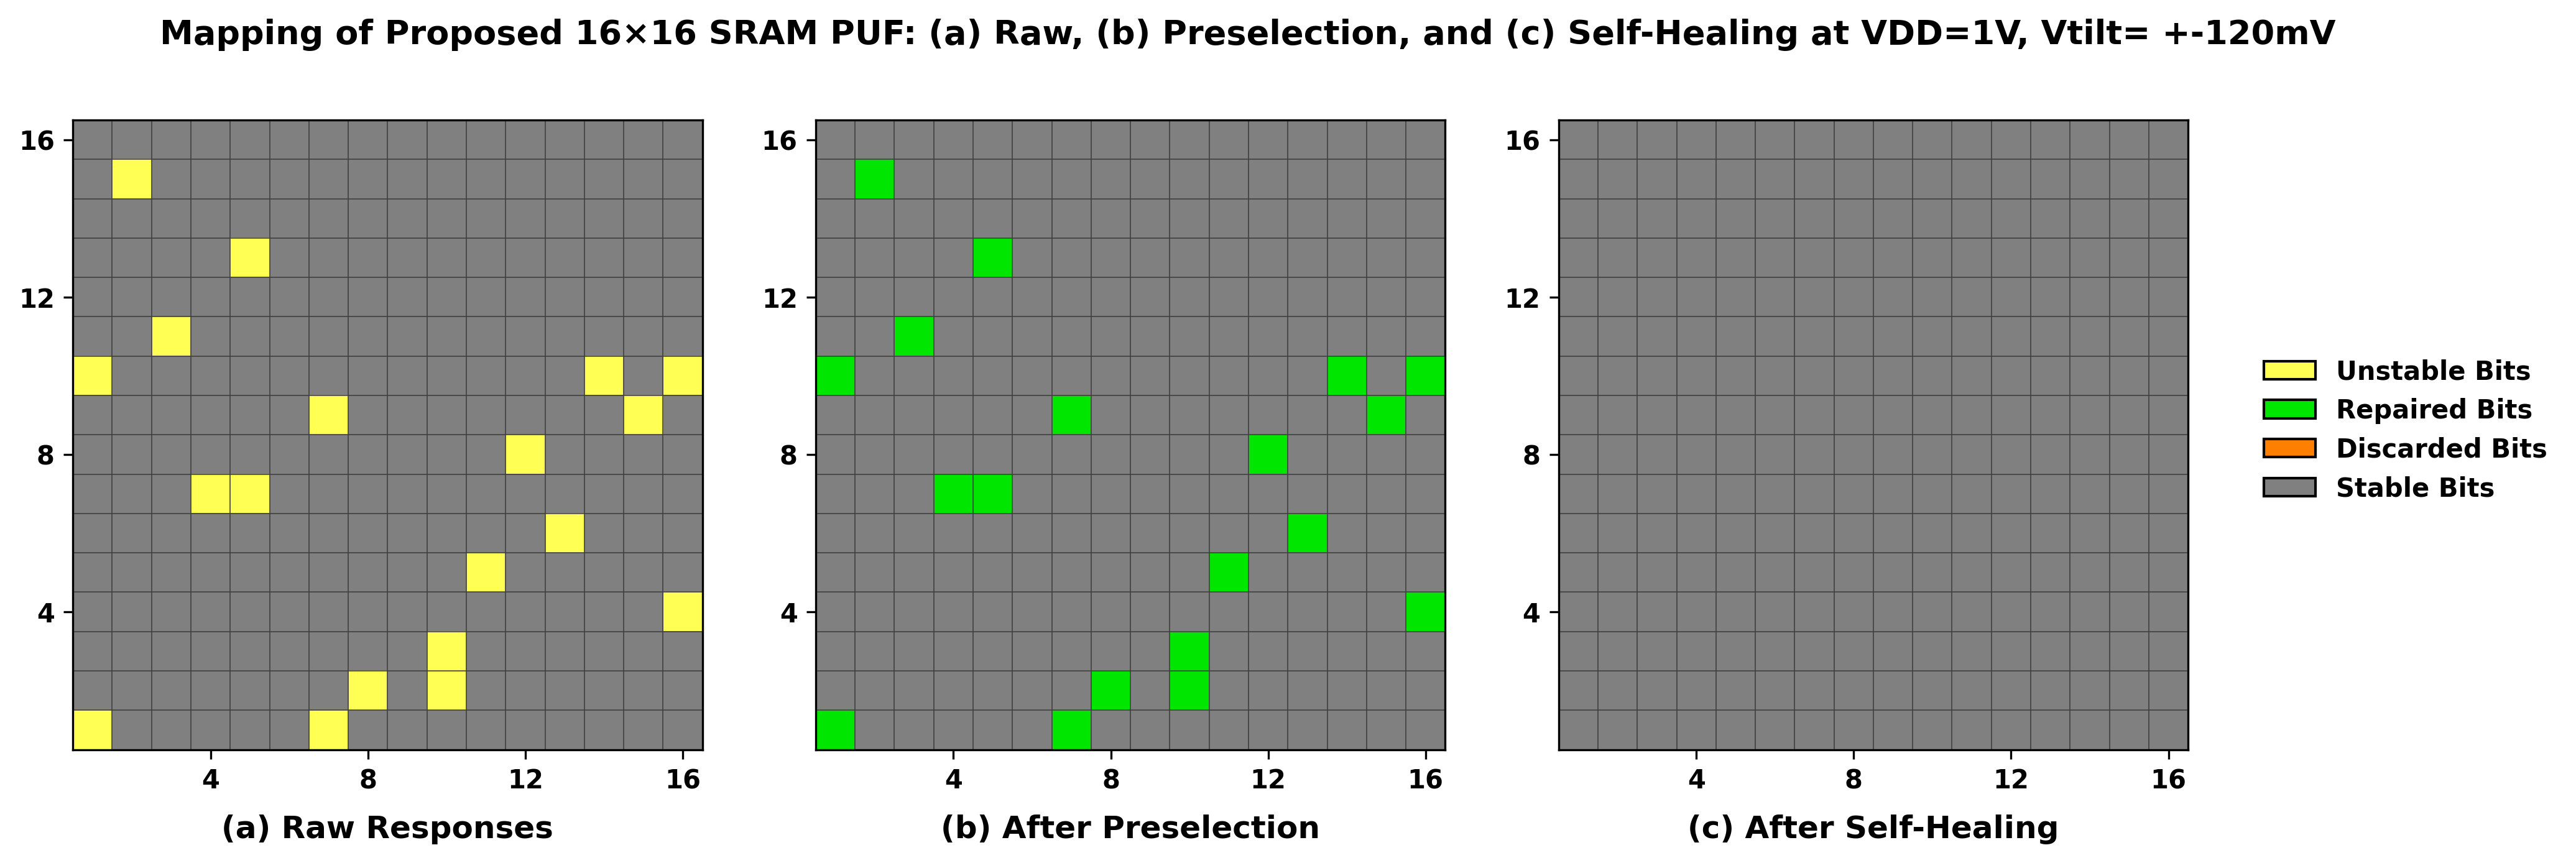

In [24]:
import os
import re
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: INSERT YOUR 3 CSV FILE PATHS HERE
# ==============================================================================
CSV_NOMINAL = "mc_256_1.0_vdd.csv"  # VDDL = VDDR = VDD (0.9V)
CSV_PLUS_80 = "mc_256_1.0_vdd+120.csv"  # VDDL = VDD + 80mV, VDDR = VDD - 80mV
CSV_MINUS_80 = "mc_256_1.0_vdd-120.csv"  # VDDL = VDD - 80mV, VDDR = VDD + 80mV

VDD_NOMINAL = 0.9  # Nominal supply voltage (V)
ARRAY_ROWS = 16  # 16 rows x 16 cols = 256 cells
ARRAY_COLS = 16

# Time windows (in seconds)
MODE2_WINDOW = (37e-9, 43e-9)  # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)  # Mode 1 active window: 97ns - 103ns


# ==============================================================================
# 2. HELPER FUNCTION: EXTRACT MODE 1 & MODE 2 BITS FROM A CADENCE CSV
# ==============================================================================
def extract_bits_from_csv(csv_path, vdd=0.9):
    """Reads BL and BLb waveforms for all 256 Monte Carlo cells and returns

    binary arrays (length 256) for Mode 1 and Mode 2.
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find CSV file: {csv_path}")

    df = pd.read_csv(csv_path, low_memory=False)
    threshold = vdd / 2.0

    # Detect and sort all mcparamset indices (1 to 256)
    paramset_ids = sorted(
        list(
            set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(df.columns)))
        )
    )

    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)
    m1_bl_v = np.zeros(len(paramset_ids), dtype=float)
    m2_bl_v = np.zeros(len(paramset_ids), dtype=float)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) X"], errors="coerce"
        ).values
        v_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce"
        ).values

        # Mode 1 window (97ns - 103ns)
        mask_m1 = (t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])
        v1 = np.nanmean(v_bl[mask_m1])
        m1_bl_v[idx] = v1
        m1_bits[idx] = 1 if v1 >= threshold else 0

        # Mode 2 window (37ns - 43ns)
        mask_m2 = (t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])
        v2 = np.nanmean(v_bl[mask_m2])
        m2_bl_v[idx] = v2
        m2_bits[idx] = 1 if v2 >= threshold else 0

    return {
        "m1_bits": m1_bits,
        "m2_bits": m2_bits,
        "m1_bl_v": m1_bl_v,
        "m2_bl_v": m2_bl_v,
    }


# ==============================================================================
# 3. MAIN ANALYSIS & SELF-HEALING PIPELINE
# ==============================================================================
def run_puf_preselection_analysis(csv_nom, csv_p80, csv_m80, vdd=0.9):
    print("Extracting waveforms from all 3 Cadence CSV files...")
    data_nom = extract_bits_from_csv(csv_nom, vdd)
    data_p80 = extract_bits_from_csv(csv_p80, vdd)
    data_m80 = extract_bits_from_csv(csv_m80, vdd)

    num_cells = len(data_nom["m1_bits"])
    assert (
        num_cells == ARRAY_ROWS * ARRAY_COLS
    ), f"Expected {ARRAY_ROWS*ARRAY_COLS} cells, got {num_cells}"

    # --- STEP 1: Evaluate Mode 1 Stability across both voltage tilts ---
    # A cell is stable in Mode 1 iff Nominal == (+80mV) == (-80mV)
    m1_stable = (data_nom["m1_bits"] == data_p80["m1_bits"]) & (
        data_nom["m1_bits"] == data_m80["m1_bits"]
    )
    m1_unstable = ~m1_stable

    # --- STEP 2: Evaluate Mode 2 Stability for Mode 1 Unstable Cells ---
    # A cell is stable in Mode 2 iff Nominal == (+80mV) == (-80mV)
    m2_stable = (data_nom["m2_bits"] == data_p80["m2_bits"]) & (
        data_nom["m2_bits"] == data_m80["m2_bits"]
    )

    # Classification states:
    # 0 = Stable Bits (Grey)
    # 1 = Unstable Bits (Yellow)
    # 2 = Repaired Bits (Green)
    # 3 = Discarded Bits (Orange)

    # Map (a): Raw Responses (Mode 1 only)
    map_a = np.where(m1_stable, 0, 1)  # 0=Grey (Stable), 1=Yellow (Unstable)

    # Map (b): Responses after Preselection & Mode-2 Healing
    # - Mode 1 Stable -> 0 (Grey: Stable)
    # - Mode 1 Unstable AND Mode 2 Stable -> 2 (Green: Repaired)
    # - Mode 1 Unstable AND Mode 2 Unstable -> 3 (Orange: Discarded)
    repaired_mask = m1_unstable & m2_stable
    discarded_mask = m1_unstable & (~m2_stable)

    map_b = np.zeros(num_cells, dtype=int)
    map_b[m1_stable] = 0  # Stable (Grey)
    map_b[repaired_mask] = 2  # Repaired (Green)
    map_b[discarded_mask] = 3  # Discarded (Orange)

    # Map (c): Active Post-Healing Responses
    # Repaired cells are now active and stable (Grey); Discarded cells remain masked out (or shown as excluded)
    # To match Fig. 10(c) where repaired cells become active stable grey and discarded bits are masked out:
    map_c = np.zeros(num_cells, dtype=int)
    map_c[m1_stable | repaired_mask] = 0  # Active Stable Bits (Grey)
    map_c[discarded_mask] = (
        4  # Masked / Excluded from key (White/Light-Grey background)
    )

    # Reshape 1D arrays (0..255) into 16x16 grids:
    # Row 0 = BL[0:15], Row 1 = BL[16:31], ..., Row 15 = BL[240:255]
    grid_a = map_a.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_b = map_b.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_c = map_c.reshape(ARRAY_ROWS, ARRAY_COLS)

    # ==========================================================================
    # 4. PRINT QUANTITATIVE SUMMARY
    # ==========================================================================
    n_m1_stable = int(np.sum(m1_stable))
    n_m1_unstable = int(np.sum(m1_unstable))
    n_repaired = int(np.sum(repaired_mask))
    n_discarded = int(np.sum(discarded_mask))
    n_final_valid = n_m1_stable + n_repaired

    raw_ber = (n_m1_unstable / num_cells) * 100.0
    healing_rate = (
        (n_repaired / n_m1_unstable * 100.0) if n_m1_unstable > 0 else 100.0
    )
    valid_yield = (n_final_valid / num_cells) * 100.0

    print("\n" + "=" * 68)
    print("  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY")
    print("=" * 68)
    print(f"Total Array Cells                 : {num_cells} (16 x 16)")
    print(
        f"Mode 1 Stable Bits (Grey)         : {n_m1_stable:3d} ({n_m1_stable/num_cells*100:.2f}%)"
    )
    print(
        f"Mode 1 Unstable Bits (Yellow)     : {n_m1_unstable:3d} ({raw_ber:.2f}% Raw Instability)"
    )
    print("-" * 68)
    print(
        f"Repaired via Mode 2 (Green)       : {n_repaired:3d} ({healing_rate:.2f}% of unstable bits healed)"
    )
    print(
        f"Discarded Dark Bits (Orange)      : {n_discarded:3d} ({n_discarded/num_cells*100:.2f}% masked out)"
    )
    print("-" * 68)
    print(
        f"Final Active Valid PUF Bits       : {n_final_valid:3d} / {num_cells} ({valid_yield:.2f}% Valid Bit Yield)"
    )
    print(f"Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)")
    print("=" * 68 + "\n")

    # Save detailed per-cell CSV report
    summary_df = pd.DataFrame(
        {
            "Cell_Index (0-255)": np.arange(num_cells),
            "Row (0-15)": np.arange(num_cells) // ARRAY_COLS,
            "Col (0-15)": np.arange(num_cells) % ARRAY_COLS,
            "M1_Nom": data_nom["m1_bits"],
            "M1_Plus80": data_p80["m1_bits"],
            "M1_Minus80": data_m80["m1_bits"],
            "M1_Stable": m1_stable,
            "M2_Nom": data_nom["m2_bits"],
            "M2_Plus80": data_p80["m2_bits"],
            "M2_Minus80": data_m80["m2_bits"],
            "M2_Stable": m2_stable,
            "Final_Status": np.where(
                m1_stable,
                "Stable (Mode 1)",
                np.where(
                    repaired_mask, "Repaired (Mode 2)", "Discarded (Masked)"
                ),
            ),
            "Selected_Mode": np.where(
                m1_stable, "Mode 1", np.where(repaired_mask, "Mode 2", "None")
            ),
            "Golden_Key_Bit": np.where(
                m1_stable,
                data_nom["m1_bits"],
                np.where(repaired_mask, data_nom["m2_bits"], -1),
            ),
        }
    )
    summary_df.to_csv("puf_self_healing_cell_report.csv", index=False)
    print("Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'")

    # ==========================================================================
    # 5. PLOT FIGURE 10 STYLE 3-PANEL MAPPING
    # ==========================================================================
    # Color palette matching Fig. 10:
    # 0: Grey (#808080) - Stable Bits
    # 1: Yellow (#FFFF54) - Unstable Bits
    # 2: Green (#00FF00) - Repaired Bits
    # 3: Orange (#FF7F0E) - Discarded Bits
    # 4: Light Neutral (#D9D9D9) - Masked/Excluded slots in post-healing map
    cmap = mcolors.ListedColormap(
        ["#808080", "#FFFF54", "#00E600", "#FF7F00", "#B8B8B8"]
    )
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), dpi=300)
    titles = [
        "(a) Raw Responses",
        "(b) After Preselection",
        "(c) After Self-Healing",
    ]
    grids = [grid_a, grid_b, grid_c]

    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap=cmap, norm=norm, origin="lower", aspect="equal")

        # Draw crisp cell grid lines for 16x16 visibility
        ax.set_xticks(np.arange(-0.5, ARRAY_COLS, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, ARRAY_ROWS, 1), minor=True)
        ax.grid(which="minor", color="#404040", linestyle="-", linewidth=0.4)
        ax.tick_params(which="minor", bottom=False, left=False)

        # Major ticks at 4, 8, 12, 16 (1-indexed like Fig. 10)
        ticks = [3, 7, 11, 15]
        tick_labels = ["4", "8", "12", "16"]
        ax.set_xticks(ticks)
        ax.set_xticklabels(tick_labels, fontsize=10, fontweight="bold")
        ax.set_yticks(ticks)
        ax.set_yticklabels(tick_labels, fontsize=10, fontweight="bold")

        ax.set_xlabel(title, fontsize=12, fontweight="bold", labelpad=8)

    # Legend matching Fig. 10
    legend_patches = [
        mpatches.Patch(
            facecolor="#FFFF54", edgecolor="black", label="Unstable Bits"
        ),
        mpatches.Patch(
            facecolor="#00E600", edgecolor="black", label="Repaired Bits"
        ),
        mpatches.Patch(
            facecolor="#FF7F00", edgecolor="black", label="Discarded Bits"
        ),
        mpatches.Patch(
            facecolor="#808080", edgecolor="black", label="Stable Bits"
        ),
    ]
    fig.legend(
        handles=legend_patches,
        loc="center left",
        bbox_to_anchor=(0.88, 0.52),
        frameon=False,
        fontsize=11,
        prop={"weight": "bold"},
    )

    plt.suptitle(
        "Mapping of Proposed 16×16 SRAM PUF: (a) Raw, (b) Preselection, and (c) Self-Healing at VDD=1V, Vtilt= +-120mV",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.subplots_adjust(left=0.05, right=0.86, top=0.88, bottom=0.15, wspace=0.18)

    output_fig = "puf_fig10_mapping.png"
    plt.savefig(output_fig, dpi=300, bbox_inches="tight")
    print(f"Saved 3-panel visualization to '{output_fig}'")
    plt.show()


if __name__ == "__main__":
    run_puf_preselection_analysis(
        CSV_NOMINAL, CSV_PLUS_80, CSV_MINUS_80, vdd=VDD_NOMINAL
    )

Extracting waveforms from all 3 Cadence CSV files...

  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY
Total Array Cells                 : 256 (16 x 16)
Mode 1 Stable Bits (Grey)         : 241 (94.14%)
Mode 1 Unstable Bits (Yellow)     :  15 (5.86% Raw Instability)
--------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  14 (93.33% of unstable bits healed)
Discarded Dark Bits (Orange)      :   1 (0.39% masked out)
--------------------------------------------------------------------
Final Active Valid PUF Bits       : 255 / 256 (99.61% Valid Bit Yield)
Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)

Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'
Saved 3-panel visualization to 'puf_fig10_mapping.png'


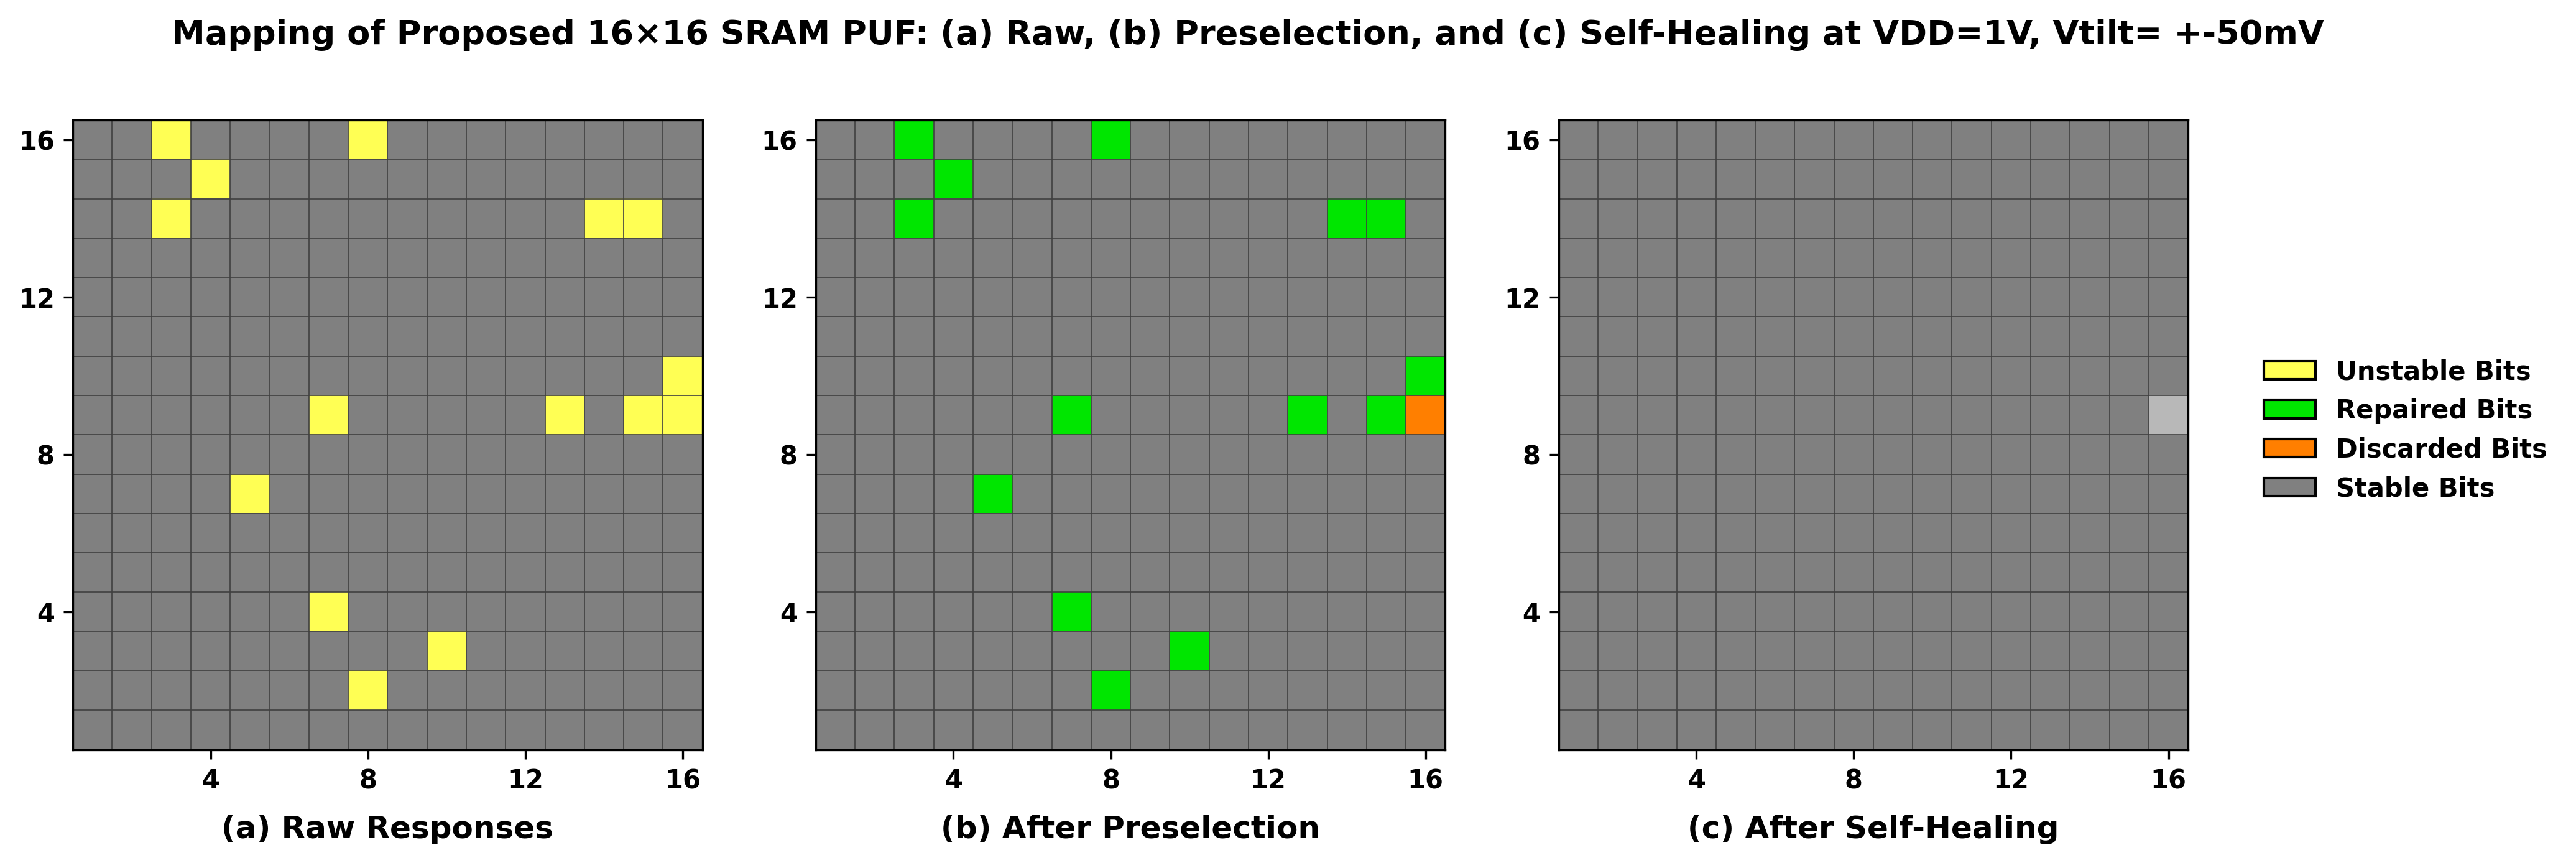

In [25]:
import os
import re
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: INSERT YOUR 3 CSV FILE PATHS HERE
# ==============================================================================
CSV_NOMINAL = "mc_256_1.0_vdd.csv"  # VDDL = VDDR = VDD (0.9V)
CSV_PLUS_80 = "mc_256_1.0_vdd+50.csv"  # VDDL = VDD + 80mV, VDDR = VDD - 80mV
CSV_MINUS_80 = "mc_256_1.0_vdd-50.csv"  # VDDL = VDD - 80mV, VDDR = VDD + 80mV

VDD_NOMINAL = 0.9  # Nominal supply voltage (V)
ARRAY_ROWS = 16  # 16 rows x 16 cols = 256 cells
ARRAY_COLS = 16

# Time windows (in seconds)
MODE2_WINDOW = (37e-9, 43e-9)  # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)  # Mode 1 active window: 97ns - 103ns


# ==============================================================================
# 2. HELPER FUNCTION: EXTRACT MODE 1 & MODE 2 BITS FROM A CADENCE CSV
# ==============================================================================
def extract_bits_from_csv(csv_path, vdd=0.9):
    """Reads BL and BLb waveforms for all 256 Monte Carlo cells and returns

    binary arrays (length 256) for Mode 1 and Mode 2.
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find CSV file: {csv_path}")

    df = pd.read_csv(csv_path, low_memory=False)
    threshold = vdd / 2.0

    # Detect and sort all mcparamset indices (1 to 256)
    paramset_ids = sorted(
        list(
            set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(df.columns)))
        )
    )

    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)
    m1_bl_v = np.zeros(len(paramset_ids), dtype=float)
    m2_bl_v = np.zeros(len(paramset_ids), dtype=float)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) X"], errors="coerce"
        ).values
        v_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce"
        ).values

        # Mode 1 window (97ns - 103ns)
        mask_m1 = (t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])
        v1 = np.nanmean(v_bl[mask_m1])
        m1_bl_v[idx] = v1
        m1_bits[idx] = 1 if v1 >= threshold else 0

        # Mode 2 window (37ns - 43ns)
        mask_m2 = (t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])
        v2 = np.nanmean(v_bl[mask_m2])
        m2_bl_v[idx] = v2
        m2_bits[idx] = 1 if v2 >= threshold else 0

    return {
        "m1_bits": m1_bits,
        "m2_bits": m2_bits,
        "m1_bl_v": m1_bl_v,
        "m2_bl_v": m2_bl_v,
    }


# ==============================================================================
# 3. MAIN ANALYSIS & SELF-HEALING PIPELINE
# ==============================================================================
def run_puf_preselection_analysis(csv_nom, csv_p80, csv_m80, vdd=0.9):
    print("Extracting waveforms from all 3 Cadence CSV files...")
    data_nom = extract_bits_from_csv(csv_nom, vdd)
    data_p80 = extract_bits_from_csv(csv_p80, vdd)
    data_m80 = extract_bits_from_csv(csv_m80, vdd)

    num_cells = len(data_nom["m1_bits"])
    assert (
        num_cells == ARRAY_ROWS * ARRAY_COLS
    ), f"Expected {ARRAY_ROWS*ARRAY_COLS} cells, got {num_cells}"

    # --- STEP 1: Evaluate Mode 1 Stability across both voltage tilts ---
    # A cell is stable in Mode 1 iff Nominal == (+80mV) == (-80mV)
    m1_stable = (data_nom["m1_bits"] == data_p80["m1_bits"]) & (
        data_nom["m1_bits"] == data_m80["m1_bits"]
    )
    m1_unstable = ~m1_stable

    # --- STEP 2: Evaluate Mode 2 Stability for Mode 1 Unstable Cells ---
    # A cell is stable in Mode 2 iff Nominal == (+80mV) == (-80mV)
    m2_stable = (data_nom["m2_bits"] == data_p80["m2_bits"]) & (
        data_nom["m2_bits"] == data_m80["m2_bits"]
    )

    # Classification states:
    # 0 = Stable Bits (Grey)
    # 1 = Unstable Bits (Yellow)
    # 2 = Repaired Bits (Green)
    # 3 = Discarded Bits (Orange)

    # Map (a): Raw Responses (Mode 1 only)
    map_a = np.where(m1_stable, 0, 1)  # 0=Grey (Stable), 1=Yellow (Unstable)

    # Map (b): Responses after Preselection & Mode-2 Healing
    # - Mode 1 Stable -> 0 (Grey: Stable)
    # - Mode 1 Unstable AND Mode 2 Stable -> 2 (Green: Repaired)
    # - Mode 1 Unstable AND Mode 2 Unstable -> 3 (Orange: Discarded)
    repaired_mask = m1_unstable & m2_stable
    discarded_mask = m1_unstable & (~m2_stable)

    map_b = np.zeros(num_cells, dtype=int)
    map_b[m1_stable] = 0  # Stable (Grey)
    map_b[repaired_mask] = 2  # Repaired (Green)
    map_b[discarded_mask] = 3  # Discarded (Orange)

    # Map (c): Active Post-Healing Responses
    # Repaired cells are now active and stable (Grey); Discarded cells remain masked out (or shown as excluded)
    # To match Fig. 10(c) where repaired cells become active stable grey and discarded bits are masked out:
    map_c = np.zeros(num_cells, dtype=int)
    map_c[m1_stable | repaired_mask] = 0  # Active Stable Bits (Grey)
    map_c[discarded_mask] = (
        4  # Masked / Excluded from key (White/Light-Grey background)
    )

    # Reshape 1D arrays (0..255) into 16x16 grids:
    # Row 0 = BL[0:15], Row 1 = BL[16:31], ..., Row 15 = BL[240:255]
    grid_a = map_a.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_b = map_b.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_c = map_c.reshape(ARRAY_ROWS, ARRAY_COLS)

    # ==========================================================================
    # 4. PRINT QUANTITATIVE SUMMARY
    # ==========================================================================
    n_m1_stable = int(np.sum(m1_stable))
    n_m1_unstable = int(np.sum(m1_unstable))
    n_repaired = int(np.sum(repaired_mask))
    n_discarded = int(np.sum(discarded_mask))
    n_final_valid = n_m1_stable + n_repaired

    raw_ber = (n_m1_unstable / num_cells) * 100.0
    healing_rate = (
        (n_repaired / n_m1_unstable * 100.0) if n_m1_unstable > 0 else 100.0
    )
    valid_yield = (n_final_valid / num_cells) * 100.0

    print("\n" + "=" * 68)
    print("  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY")
    print("=" * 68)
    print(f"Total Array Cells                 : {num_cells} (16 x 16)")
    print(
        f"Mode 1 Stable Bits (Grey)         : {n_m1_stable:3d} ({n_m1_stable/num_cells*100:.2f}%)"
    )
    print(
        f"Mode 1 Unstable Bits (Yellow)     : {n_m1_unstable:3d} ({raw_ber:.2f}% Raw Instability)"
    )
    print("-" * 68)
    print(
        f"Repaired via Mode 2 (Green)       : {n_repaired:3d} ({healing_rate:.2f}% of unstable bits healed)"
    )
    print(
        f"Discarded Dark Bits (Orange)      : {n_discarded:3d} ({n_discarded/num_cells*100:.2f}% masked out)"
    )
    print("-" * 68)
    print(
        f"Final Active Valid PUF Bits       : {n_final_valid:3d} / {num_cells} ({valid_yield:.2f}% Valid Bit Yield)"
    )
    print(f"Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)")
    print("=" * 68 + "\n")

    # Save detailed per-cell CSV report
    summary_df = pd.DataFrame(
        {
            "Cell_Index (0-255)": np.arange(num_cells),
            "Row (0-15)": np.arange(num_cells) // ARRAY_COLS,
            "Col (0-15)": np.arange(num_cells) % ARRAY_COLS,
            "M1_Nom": data_nom["m1_bits"],
            "M1_Plus80": data_p80["m1_bits"],
            "M1_Minus80": data_m80["m1_bits"],
            "M1_Stable": m1_stable,
            "M2_Nom": data_nom["m2_bits"],
            "M2_Plus80": data_p80["m2_bits"],
            "M2_Minus80": data_m80["m2_bits"],
            "M2_Stable": m2_stable,
            "Final_Status": np.where(
                m1_stable,
                "Stable (Mode 1)",
                np.where(
                    repaired_mask, "Repaired (Mode 2)", "Discarded (Masked)"
                ),
            ),
            "Selected_Mode": np.where(
                m1_stable, "Mode 1", np.where(repaired_mask, "Mode 2", "None")
            ),
            "Golden_Key_Bit": np.where(
                m1_stable,
                data_nom["m1_bits"],
                np.where(repaired_mask, data_nom["m2_bits"], -1),
            ),
        }
    )
    summary_df.to_csv("puf_self_healing_cell_report.csv", index=False)
    print("Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'")

    # ==========================================================================
    # 5. PLOT FIGURE 10 STYLE 3-PANEL MAPPING
    # ==========================================================================
    # Color palette matching Fig. 10:
    # 0: Grey (#808080) - Stable Bits
    # 1: Yellow (#FFFF54) - Unstable Bits
    # 2: Green (#00FF00) - Repaired Bits
    # 3: Orange (#FF7F0E) - Discarded Bits
    # 4: Light Neutral (#D9D9D9) - Masked/Excluded slots in post-healing map
    cmap = mcolors.ListedColormap(
        ["#808080", "#FFFF54", "#00E600", "#FF7F00", "#B8B8B8"]
    )
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), dpi=300)
    titles = [
        "(a) Raw Responses",
        "(b) After Preselection",
        "(c) After Self-Healing",
    ]
    grids = [grid_a, grid_b, grid_c]

    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap=cmap, norm=norm, origin="lower", aspect="equal")

        # Draw crisp cell grid lines for 16x16 visibility
        ax.set_xticks(np.arange(-0.5, ARRAY_COLS, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, ARRAY_ROWS, 1), minor=True)
        ax.grid(which="minor", color="#404040", linestyle="-", linewidth=0.4)
        ax.tick_params(which="minor", bottom=False, left=False)

        # Major ticks at 4, 8, 12, 16 (1-indexed like Fig. 10)
        ticks = [3, 7, 11, 15]
        tick_labels = ["4", "8", "12", "16"]
        ax.set_xticks(ticks)
        ax.set_xticklabels(tick_labels, fontsize=10, fontweight="bold")
        ax.set_yticks(ticks)
        ax.set_yticklabels(tick_labels, fontsize=10, fontweight="bold")

        ax.set_xlabel(title, fontsize=12, fontweight="bold", labelpad=8)

    # Legend matching Fig. 10
    legend_patches = [
        mpatches.Patch(
            facecolor="#FFFF54", edgecolor="black", label="Unstable Bits"
        ),
        mpatches.Patch(
            facecolor="#00E600", edgecolor="black", label="Repaired Bits"
        ),
        mpatches.Patch(
            facecolor="#FF7F00", edgecolor="black", label="Discarded Bits"
        ),
        mpatches.Patch(
            facecolor="#808080", edgecolor="black", label="Stable Bits"
        ),
    ]
    fig.legend(
        handles=legend_patches,
        loc="center left",
        bbox_to_anchor=(0.88, 0.52),
        frameon=False,
        fontsize=11,
        prop={"weight": "bold"},
    )

    plt.suptitle(
        "Mapping of Proposed 16×16 SRAM PUF: (a) Raw, (b) Preselection, and (c) Self-Healing at VDD=1V, Vtilt= +-50mV",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.subplots_adjust(left=0.05, right=0.86, top=0.88, bottom=0.15, wspace=0.18)

    output_fig = "puf_fig10_mapping.png"
    plt.savefig(output_fig, dpi=300, bbox_inches="tight")
    print(f"Saved 3-panel visualization to '{output_fig}'")
    plt.show()


if __name__ == "__main__":
    run_puf_preselection_analysis(
        CSV_NOMINAL, CSV_PLUS_80, CSV_MINUS_80, vdd=VDD_NOMINAL
    )

VDD = 0.8 V, +-50mV

Extracting waveforms from all 3 Cadence CSV files...

  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY
Total Array Cells                 : 256 (16 x 16)
Mode 1 Stable Bits (Grey)         : 244 (95.31%)
Mode 1 Unstable Bits (Yellow)     :  12 (4.69% Raw Instability)
--------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  12 (100.00% of unstable bits healed)
Discarded Dark Bits (Orange)      :   0 (0.00% masked out)
--------------------------------------------------------------------
Final Active Valid PUF Bits       : 256 / 256 (100.00% Valid Bit Yield)
Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)

Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'
Saved 3-panel visualization to 'puf_fig10_mapping.png'


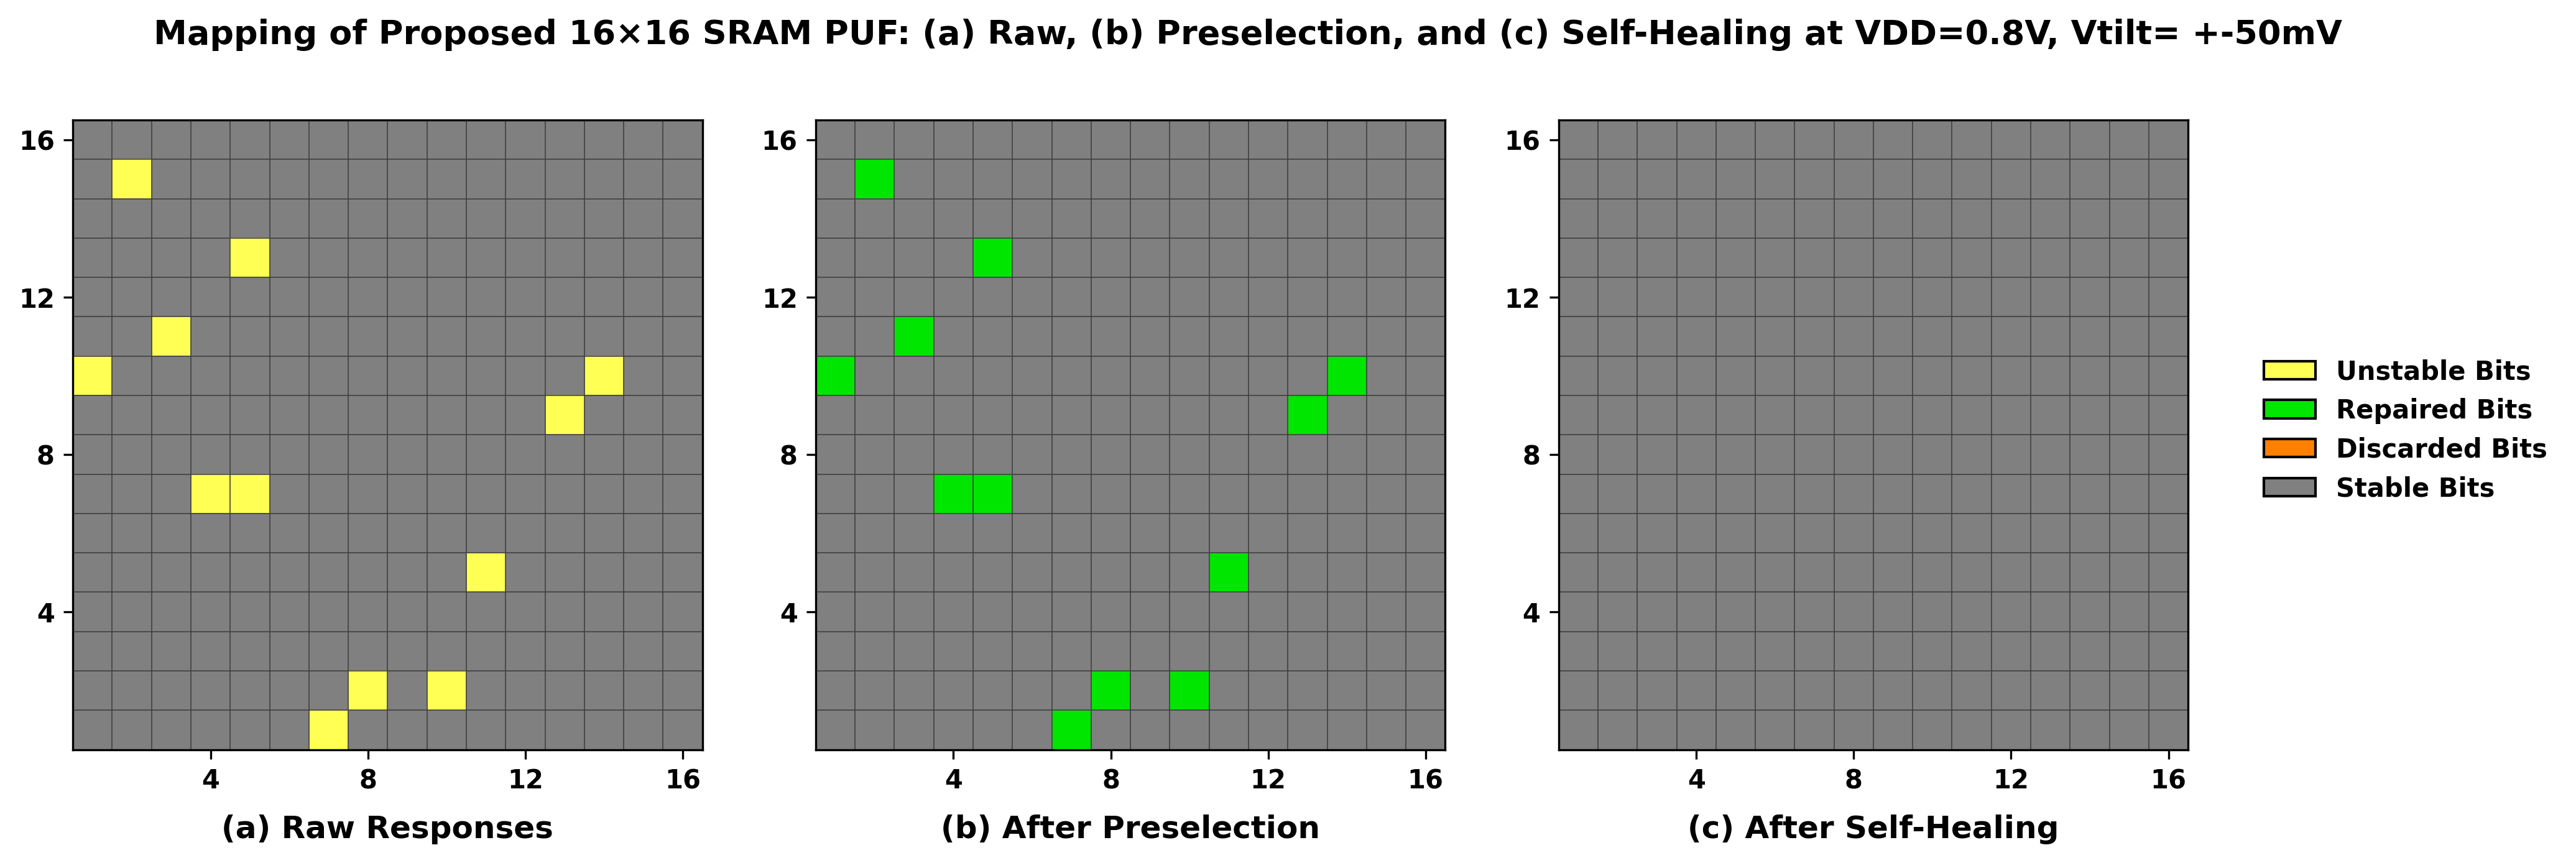

In [26]:
import os
import re
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: INSERT YOUR 3 CSV FILE PATHS HERE
# ==============================================================================
CSV_NOMINAL = "mc_256_0.8_vdd.csv"  # VDDL = VDDR = VDD (0.9V)
CSV_PLUS_80 = "mc_256_0.8_vdd+50.csv"  # VDDL = VDD + 80mV, VDDR = VDD - 80mV
CSV_MINUS_80 = "mc_256_0.8_vdd-50.csv"  # VDDL = VDD - 80mV, VDDR = VDD + 80mV

VDD_NOMINAL = 0.9  # Nominal supply voltage (V)
ARRAY_ROWS = 16  # 16 rows x 16 cols = 256 cells
ARRAY_COLS = 16

# Time windows (in seconds)
MODE2_WINDOW = (37e-9, 43e-9)  # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)  # Mode 1 active window: 97ns - 103ns


# ==============================================================================
# 2. HELPER FUNCTION: EXTRACT MODE 1 & MODE 2 BITS FROM A CADENCE CSV
# ==============================================================================
def extract_bits_from_csv(csv_path, vdd=0.9):
    """Reads BL and BLb waveforms for all 256 Monte Carlo cells and returns

    binary arrays (length 256) for Mode 1 and Mode 2.
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find CSV file: {csv_path}")

    df = pd.read_csv(csv_path, low_memory=False)
    threshold = vdd / 2.0

    # Detect and sort all mcparamset indices (1 to 256)
    paramset_ids = sorted(
        list(
            set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(df.columns)))
        )
    )

    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)
    m1_bl_v = np.zeros(len(paramset_ids), dtype=float)
    m2_bl_v = np.zeros(len(paramset_ids), dtype=float)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) X"], errors="coerce"
        ).values
        v_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce"
        ).values

        # Mode 1 window (97ns - 103ns)
        mask_m1 = (t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])
        v1 = np.nanmean(v_bl[mask_m1])
        m1_bl_v[idx] = v1
        m1_bits[idx] = 1 if v1 >= threshold else 0

        # Mode 2 window (37ns - 43ns)
        mask_m2 = (t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])
        v2 = np.nanmean(v_bl[mask_m2])
        m2_bl_v[idx] = v2
        m2_bits[idx] = 1 if v2 >= threshold else 0

    return {
        "m1_bits": m1_bits,
        "m2_bits": m2_bits,
        "m1_bl_v": m1_bl_v,
        "m2_bl_v": m2_bl_v,
    }


# ==============================================================================
# 3. MAIN ANALYSIS & SELF-HEALING PIPELINE
# ==============================================================================
def run_puf_preselection_analysis(csv_nom, csv_p80, csv_m80, vdd=0.9):
    print("Extracting waveforms from all 3 Cadence CSV files...")
    data_nom = extract_bits_from_csv(csv_nom, vdd)
    data_p80 = extract_bits_from_csv(csv_p80, vdd)
    data_m80 = extract_bits_from_csv(csv_m80, vdd)

    num_cells = len(data_nom["m1_bits"])
    assert (
        num_cells == ARRAY_ROWS * ARRAY_COLS
    ), f"Expected {ARRAY_ROWS*ARRAY_COLS} cells, got {num_cells}"

    # --- STEP 1: Evaluate Mode 1 Stability across both voltage tilts ---
    # A cell is stable in Mode 1 iff Nominal == (+80mV) == (-80mV)
    m1_stable = (data_nom["m1_bits"] == data_p80["m1_bits"]) & (
        data_nom["m1_bits"] == data_m80["m1_bits"]
    )
    m1_unstable = ~m1_stable

    # --- STEP 2: Evaluate Mode 2 Stability for Mode 1 Unstable Cells ---
    # A cell is stable in Mode 2 iff Nominal == (+80mV) == (-80mV)
    m2_stable = (data_nom["m2_bits"] == data_p80["m2_bits"]) & (
        data_nom["m2_bits"] == data_m80["m2_bits"]
    )

    # Classification states:
    # 0 = Stable Bits (Grey)
    # 1 = Unstable Bits (Yellow)
    # 2 = Repaired Bits (Green)
    # 3 = Discarded Bits (Orange)

    # Map (a): Raw Responses (Mode 1 only)
    map_a = np.where(m1_stable, 0, 1)  # 0=Grey (Stable), 1=Yellow (Unstable)

    # Map (b): Responses after Preselection & Mode-2 Healing
    # - Mode 1 Stable -> 0 (Grey: Stable)
    # - Mode 1 Unstable AND Mode 2 Stable -> 2 (Green: Repaired)
    # - Mode 1 Unstable AND Mode 2 Unstable -> 3 (Orange: Discarded)
    repaired_mask = m1_unstable & m2_stable
    discarded_mask = m1_unstable & (~m2_stable)

    map_b = np.zeros(num_cells, dtype=int)
    map_b[m1_stable] = 0  # Stable (Grey)
    map_b[repaired_mask] = 2  # Repaired (Green)
    map_b[discarded_mask] = 3  # Discarded (Orange)

    # Map (c): Active Post-Healing Responses
    # Repaired cells are now active and stable (Grey); Discarded cells remain masked out (or shown as excluded)
    # To match Fig. 10(c) where repaired cells become active stable grey and discarded bits are masked out:
    map_c = np.zeros(num_cells, dtype=int)
    map_c[m1_stable | repaired_mask] = 0  # Active Stable Bits (Grey)
    map_c[discarded_mask] = (
        4  # Masked / Excluded from key (White/Light-Grey background)
    )

    # Reshape 1D arrays (0..255) into 16x16 grids:
    # Row 0 = BL[0:15], Row 1 = BL[16:31], ..., Row 15 = BL[240:255]
    grid_a = map_a.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_b = map_b.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_c = map_c.reshape(ARRAY_ROWS, ARRAY_COLS)

    # ==========================================================================
    # 4. PRINT QUANTITATIVE SUMMARY
    # ==========================================================================
    n_m1_stable = int(np.sum(m1_stable))
    n_m1_unstable = int(np.sum(m1_unstable))
    n_repaired = int(np.sum(repaired_mask))
    n_discarded = int(np.sum(discarded_mask))
    n_final_valid = n_m1_stable + n_repaired

    raw_ber = (n_m1_unstable / num_cells) * 100.0
    healing_rate = (
        (n_repaired / n_m1_unstable * 100.0) if n_m1_unstable > 0 else 100.0
    )
    valid_yield = (n_final_valid / num_cells) * 100.0

    print("\n" + "=" * 68)
    print("  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY")
    print("=" * 68)
    print(f"Total Array Cells                 : {num_cells} (16 x 16)")
    print(
        f"Mode 1 Stable Bits (Grey)         : {n_m1_stable:3d} ({n_m1_stable/num_cells*100:.2f}%)"
    )
    print(
        f"Mode 1 Unstable Bits (Yellow)     : {n_m1_unstable:3d} ({raw_ber:.2f}% Raw Instability)"
    )
    print("-" * 68)
    print(
        f"Repaired via Mode 2 (Green)       : {n_repaired:3d} ({healing_rate:.2f}% of unstable bits healed)"
    )
    print(
        f"Discarded Dark Bits (Orange)      : {n_discarded:3d} ({n_discarded/num_cells*100:.2f}% masked out)"
    )
    print("-" * 68)
    print(
        f"Final Active Valid PUF Bits       : {n_final_valid:3d} / {num_cells} ({valid_yield:.2f}% Valid Bit Yield)"
    )
    print(f"Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)")
    print("=" * 68 + "\n")

    # Save detailed per-cell CSV report
    summary_df = pd.DataFrame(
        {
            "Cell_Index (0-255)": np.arange(num_cells),
            "Row (0-15)": np.arange(num_cells) // ARRAY_COLS,
            "Col (0-15)": np.arange(num_cells) % ARRAY_COLS,
            "M1_Nom": data_nom["m1_bits"],
            "M1_Plus80": data_p80["m1_bits"],
            "M1_Minus80": data_m80["m1_bits"],
            "M1_Stable": m1_stable,
            "M2_Nom": data_nom["m2_bits"],
            "M2_Plus80": data_p80["m2_bits"],
            "M2_Minus80": data_m80["m2_bits"],
            "M2_Stable": m2_stable,
            "Final_Status": np.where(
                m1_stable,
                "Stable (Mode 1)",
                np.where(
                    repaired_mask, "Repaired (Mode 2)", "Discarded (Masked)"
                ),
            ),
            "Selected_Mode": np.where(
                m1_stable, "Mode 1", np.where(repaired_mask, "Mode 2", "None")
            ),
            "Golden_Key_Bit": np.where(
                m1_stable,
                data_nom["m1_bits"],
                np.where(repaired_mask, data_nom["m2_bits"], -1),
            ),
        }
    )
    summary_df.to_csv("puf_self_healing_cell_report.csv", index=False)
    print("Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'")

    # ==========================================================================
    # 5. PLOT FIGURE 10 STYLE 3-PANEL MAPPING
    # ==========================================================================
    # Color palette matching Fig. 10:
    # 0: Grey (#808080) - Stable Bits
    # 1: Yellow (#FFFF54) - Unstable Bits
    # 2: Green (#00FF00) - Repaired Bits
    # 3: Orange (#FF7F0E) - Discarded Bits
    # 4: Light Neutral (#D9D9D9) - Masked/Excluded slots in post-healing map
    cmap = mcolors.ListedColormap(
        ["#808080", "#FFFF54", "#00E600", "#FF7F00", "#B8B8B8"]
    )
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), dpi=300)
    titles = [
        "(a) Raw Responses",
        "(b) After Preselection",
        "(c) After Self-Healing",
    ]
    grids = [grid_a, grid_b, grid_c]

    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap=cmap, norm=norm, origin="lower", aspect="equal")

        # Draw crisp cell grid lines for 16x16 visibility
        ax.set_xticks(np.arange(-0.5, ARRAY_COLS, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, ARRAY_ROWS, 1), minor=True)
        ax.grid(which="minor", color="#404040", linestyle="-", linewidth=0.4)
        ax.tick_params(which="minor", bottom=False, left=False)

        # Major ticks at 4, 8, 12, 16 (1-indexed like Fig. 10)
        ticks = [3, 7, 11, 15]
        tick_labels = ["4", "8", "12", "16"]
        ax.set_xticks(ticks)
        ax.set_xticklabels(tick_labels, fontsize=10, fontweight="bold")
        ax.set_yticks(ticks)
        ax.set_yticklabels(tick_labels, fontsize=10, fontweight="bold")

        ax.set_xlabel(title, fontsize=12, fontweight="bold", labelpad=8)

    # Legend matching Fig. 10
    legend_patches = [
        mpatches.Patch(
            facecolor="#FFFF54", edgecolor="black", label="Unstable Bits"
        ),
        mpatches.Patch(
            facecolor="#00E600", edgecolor="black", label="Repaired Bits"
        ),
        mpatches.Patch(
            facecolor="#FF7F00", edgecolor="black", label="Discarded Bits"
        ),
        mpatches.Patch(
            facecolor="#808080", edgecolor="black", label="Stable Bits"
        ),
    ]
    fig.legend(
        handles=legend_patches,
        loc="center left",
        bbox_to_anchor=(0.88, 0.52),
        frameon=False,
        fontsize=11,
        prop={"weight": "bold"},
    )

    plt.suptitle(
        "Mapping of Proposed 16×16 SRAM PUF: (a) Raw, (b) Preselection, and (c) Self-Healing at VDD=0.8V, Vtilt= +-50mV",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.subplots_adjust(left=0.05, right=0.86, top=0.88, bottom=0.15, wspace=0.18)

    output_fig = "puf_fig10_mapping.png"
    plt.savefig(output_fig, dpi=300, bbox_inches="tight")
    print(f"Saved 3-panel visualization to '{output_fig}'")
    plt.show()


if __name__ == "__main__":
    run_puf_preselection_analysis(
        CSV_NOMINAL, CSV_PLUS_80, CSV_MINUS_80, vdd=VDD_NOMINAL
    )

VDD=0.8V, +-80mV

Extracting waveforms from all 3 Cadence CSV files...

  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY
Total Array Cells                 : 256 (16 x 16)
Mode 1 Stable Bits (Grey)         : 239 (93.36%)
Mode 1 Unstable Bits (Yellow)     :  17 (6.64% Raw Instability)
--------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  17 (100.00% of unstable bits healed)
Discarded Dark Bits (Orange)      :   0 (0.00% masked out)
--------------------------------------------------------------------
Final Active Valid PUF Bits       : 256 / 256 (100.00% Valid Bit Yield)
Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)

Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'
Saved 3-panel visualization to 'puf_fig10_mapping.png'


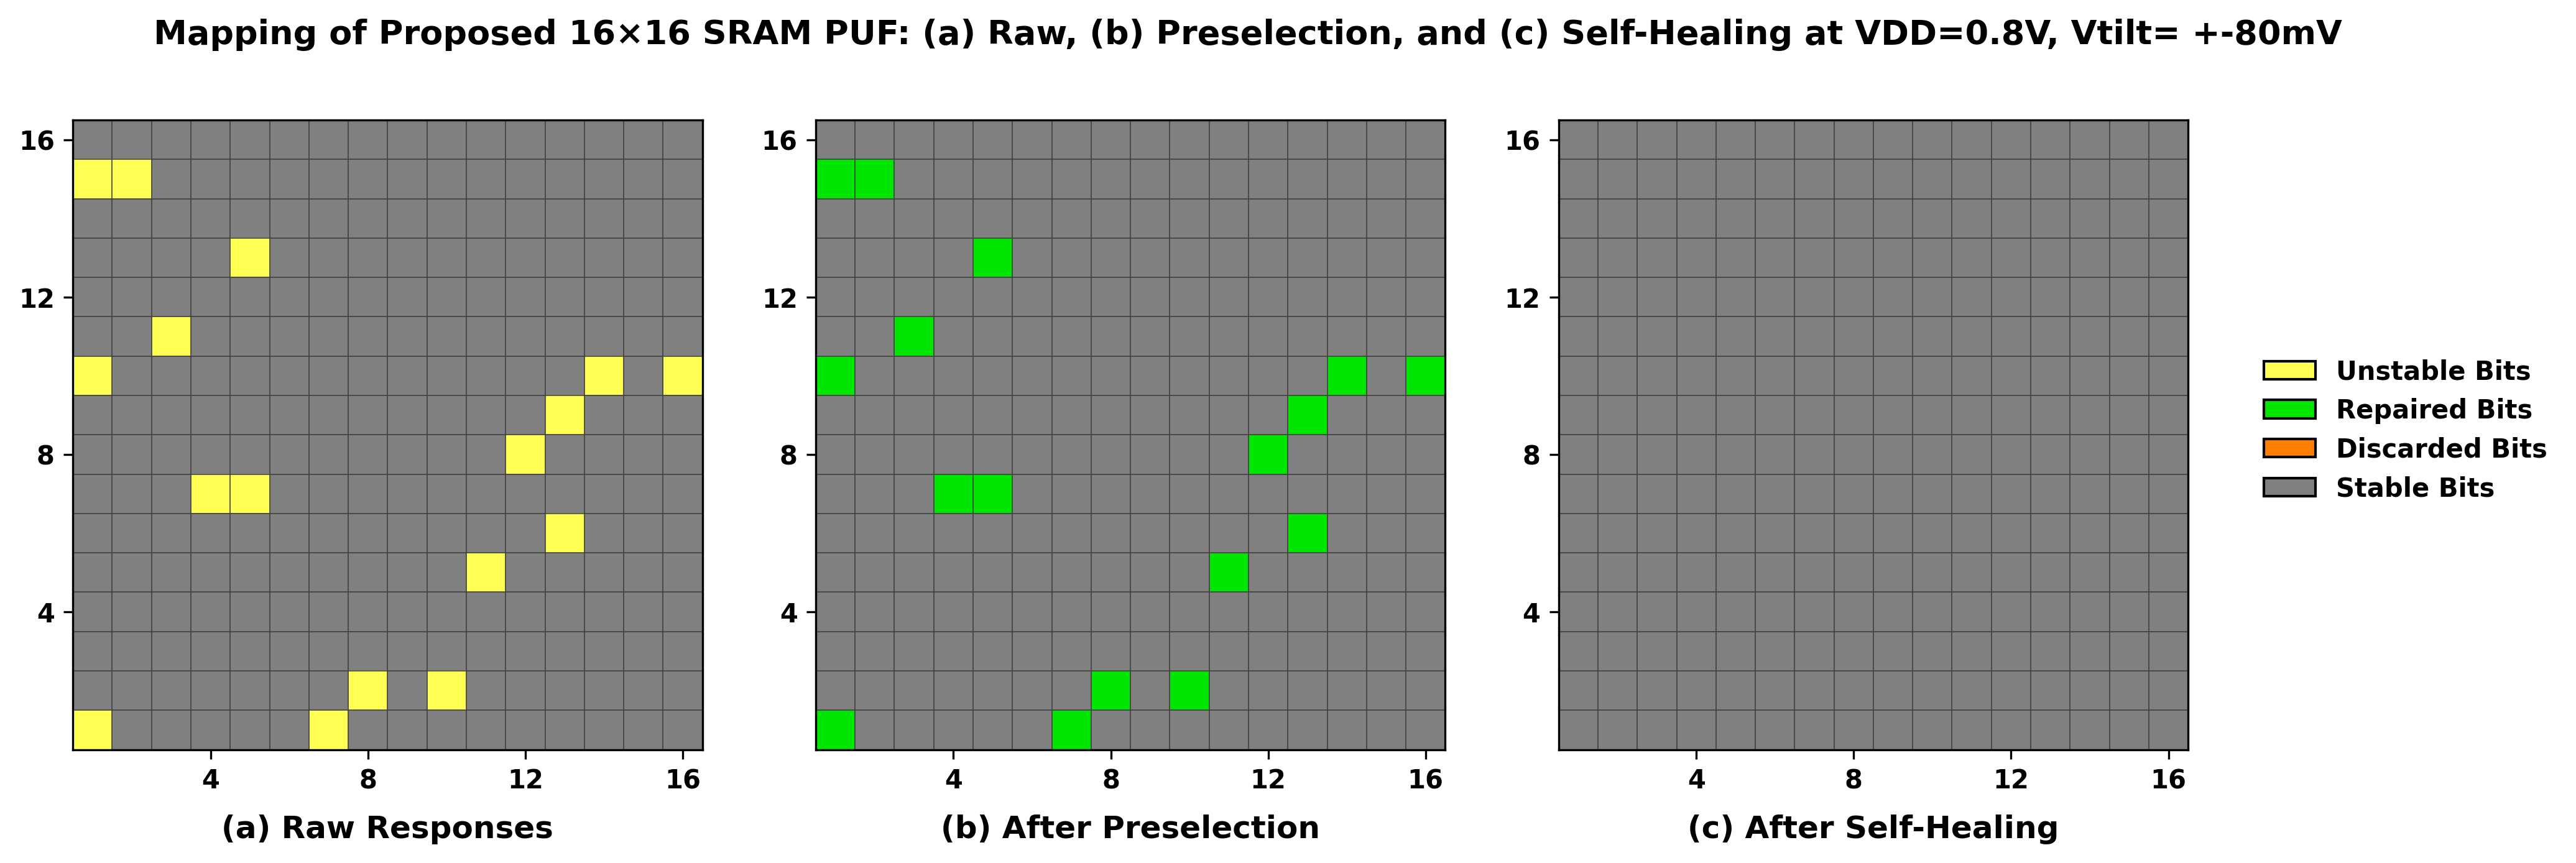

In [27]:
import os
import re
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: INSERT YOUR 3 CSV FILE PATHS HERE
# ==============================================================================
CSV_NOMINAL = "mc_256_0.8_vdd.csv"  # VDDL = VDDR = VDD (0.9V)
CSV_PLUS_80 = "mc_256_0.8_vdd+80.csv"  # VDDL = VDD + 80mV, VDDR = VDD - 80mV
CSV_MINUS_80 = "mc_256_0.8_vdd-80.csv"  # VDDL = VDD - 80mV, VDDR = VDD + 80mV

VDD_NOMINAL = 0.9  # Nominal supply voltage (V)
ARRAY_ROWS = 16  # 16 rows x 16 cols = 256 cells
ARRAY_COLS = 16

# Time windows (in seconds)
MODE2_WINDOW = (37e-9, 43e-9)  # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)  # Mode 1 active window: 97ns - 103ns


# ==============================================================================
# 2. HELPER FUNCTION: EXTRACT MODE 1 & MODE 2 BITS FROM A CADENCE CSV
# ==============================================================================
def extract_bits_from_csv(csv_path, vdd=0.9):
    """Reads BL and BLb waveforms for all 256 Monte Carlo cells and returns

    binary arrays (length 256) for Mode 1 and Mode 2.
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find CSV file: {csv_path}")

    df = pd.read_csv(csv_path, low_memory=False)
    threshold = vdd / 2.0

    # Detect and sort all mcparamset indices (1 to 256)
    paramset_ids = sorted(
        list(
            set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(df.columns)))
        )
    )

    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)
    m1_bl_v = np.zeros(len(paramset_ids), dtype=float)
    m2_bl_v = np.zeros(len(paramset_ids), dtype=float)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) X"], errors="coerce"
        ).values
        v_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce"
        ).values

        # Mode 1 window (97ns - 103ns)
        mask_m1 = (t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])
        v1 = np.nanmean(v_bl[mask_m1])
        m1_bl_v[idx] = v1
        m1_bits[idx] = 1 if v1 >= threshold else 0

        # Mode 2 window (37ns - 43ns)
        mask_m2 = (t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])
        v2 = np.nanmean(v_bl[mask_m2])
        m2_bl_v[idx] = v2
        m2_bits[idx] = 1 if v2 >= threshold else 0

    return {
        "m1_bits": m1_bits,
        "m2_bits": m2_bits,
        "m1_bl_v": m1_bl_v,
        "m2_bl_v": m2_bl_v,
    }


# ==============================================================================
# 3. MAIN ANALYSIS & SELF-HEALING PIPELINE
# ==============================================================================
def run_puf_preselection_analysis(csv_nom, csv_p80, csv_m80, vdd=0.9):
    print("Extracting waveforms from all 3 Cadence CSV files...")
    data_nom = extract_bits_from_csv(csv_nom, vdd)
    data_p80 = extract_bits_from_csv(csv_p80, vdd)
    data_m80 = extract_bits_from_csv(csv_m80, vdd)

    num_cells = len(data_nom["m1_bits"])
    assert (
        num_cells == ARRAY_ROWS * ARRAY_COLS
    ), f"Expected {ARRAY_ROWS*ARRAY_COLS} cells, got {num_cells}"

    # --- STEP 1: Evaluate Mode 1 Stability across both voltage tilts ---
    # A cell is stable in Mode 1 iff Nominal == (+80mV) == (-80mV)
    m1_stable = (data_nom["m1_bits"] == data_p80["m1_bits"]) & (
        data_nom["m1_bits"] == data_m80["m1_bits"]
    )
    m1_unstable = ~m1_stable

    # --- STEP 2: Evaluate Mode 2 Stability for Mode 1 Unstable Cells ---
    # A cell is stable in Mode 2 iff Nominal == (+80mV) == (-80mV)
    m2_stable = (data_nom["m2_bits"] == data_p80["m2_bits"]) & (
        data_nom["m2_bits"] == data_m80["m2_bits"]
    )

    # Classification states:
    # 0 = Stable Bits (Grey)
    # 1 = Unstable Bits (Yellow)
    # 2 = Repaired Bits (Green)
    # 3 = Discarded Bits (Orange)

    # Map (a): Raw Responses (Mode 1 only)
    map_a = np.where(m1_stable, 0, 1)  # 0=Grey (Stable), 1=Yellow (Unstable)

    # Map (b): Responses after Preselection & Mode-2 Healing
    # - Mode 1 Stable -> 0 (Grey: Stable)
    # - Mode 1 Unstable AND Mode 2 Stable -> 2 (Green: Repaired)
    # - Mode 1 Unstable AND Mode 2 Unstable -> 3 (Orange: Discarded)
    repaired_mask = m1_unstable & m2_stable
    discarded_mask = m1_unstable & (~m2_stable)

    map_b = np.zeros(num_cells, dtype=int)
    map_b[m1_stable] = 0  # Stable (Grey)
    map_b[repaired_mask] = 2  # Repaired (Green)
    map_b[discarded_mask] = 3  # Discarded (Orange)

    # Map (c): Active Post-Healing Responses
    # Repaired cells are now active and stable (Grey); Discarded cells remain masked out (or shown as excluded)
    # To match Fig. 10(c) where repaired cells become active stable grey and discarded bits are masked out:
    map_c = np.zeros(num_cells, dtype=int)
    map_c[m1_stable | repaired_mask] = 0  # Active Stable Bits (Grey)
    map_c[discarded_mask] = (
        4  # Masked / Excluded from key (White/Light-Grey background)
    )

    # Reshape 1D arrays (0..255) into 16x16 grids:
    # Row 0 = BL[0:15], Row 1 = BL[16:31], ..., Row 15 = BL[240:255]
    grid_a = map_a.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_b = map_b.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_c = map_c.reshape(ARRAY_ROWS, ARRAY_COLS)

    # ==========================================================================
    # 4. PRINT QUANTITATIVE SUMMARY
    # ==========================================================================
    n_m1_stable = int(np.sum(m1_stable))
    n_m1_unstable = int(np.sum(m1_unstable))
    n_repaired = int(np.sum(repaired_mask))
    n_discarded = int(np.sum(discarded_mask))
    n_final_valid = n_m1_stable + n_repaired

    raw_ber = (n_m1_unstable / num_cells) * 100.0
    healing_rate = (
        (n_repaired / n_m1_unstable * 100.0) if n_m1_unstable > 0 else 100.0
    )
    valid_yield = (n_final_valid / num_cells) * 100.0

    print("\n" + "=" * 68)
    print("  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY")
    print("=" * 68)
    print(f"Total Array Cells                 : {num_cells} (16 x 16)")
    print(
        f"Mode 1 Stable Bits (Grey)         : {n_m1_stable:3d} ({n_m1_stable/num_cells*100:.2f}%)"
    )
    print(
        f"Mode 1 Unstable Bits (Yellow)     : {n_m1_unstable:3d} ({raw_ber:.2f}% Raw Instability)"
    )
    print("-" * 68)
    print(
        f"Repaired via Mode 2 (Green)       : {n_repaired:3d} ({healing_rate:.2f}% of unstable bits healed)"
    )
    print(
        f"Discarded Dark Bits (Orange)      : {n_discarded:3d} ({n_discarded/num_cells*100:.2f}% masked out)"
    )
    print("-" * 68)
    print(
        f"Final Active Valid PUF Bits       : {n_final_valid:3d} / {num_cells} ({valid_yield:.2f}% Valid Bit Yield)"
    )
    print(f"Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)")
    print("=" * 68 + "\n")

    # Save detailed per-cell CSV report
    summary_df = pd.DataFrame(
        {
            "Cell_Index (0-255)": np.arange(num_cells),
            "Row (0-15)": np.arange(num_cells) // ARRAY_COLS,
            "Col (0-15)": np.arange(num_cells) % ARRAY_COLS,
            "M1_Nom": data_nom["m1_bits"],
            "M1_Plus80": data_p80["m1_bits"],
            "M1_Minus80": data_m80["m1_bits"],
            "M1_Stable": m1_stable,
            "M2_Nom": data_nom["m2_bits"],
            "M2_Plus80": data_p80["m2_bits"],
            "M2_Minus80": data_m80["m2_bits"],
            "M2_Stable": m2_stable,
            "Final_Status": np.where(
                m1_stable,
                "Stable (Mode 1)",
                np.where(
                    repaired_mask, "Repaired (Mode 2)", "Discarded (Masked)"
                ),
            ),
            "Selected_Mode": np.where(
                m1_stable, "Mode 1", np.where(repaired_mask, "Mode 2", "None")
            ),
            "Golden_Key_Bit": np.where(
                m1_stable,
                data_nom["m1_bits"],
                np.where(repaired_mask, data_nom["m2_bits"], -1),
            ),
        }
    )
    summary_df.to_csv("puf_self_healing_cell_report.csv", index=False)
    print("Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'")

    # ==========================================================================
    # 5. PLOT FIGURE 10 STYLE 3-PANEL MAPPING
    # ==========================================================================
    # Color palette matching Fig. 10:
    # 0: Grey (#808080) - Stable Bits
    # 1: Yellow (#FFFF54) - Unstable Bits
    # 2: Green (#00FF00) - Repaired Bits
    # 3: Orange (#FF7F0E) - Discarded Bits
    # 4: Light Neutral (#D9D9D9) - Masked/Excluded slots in post-healing map
    cmap = mcolors.ListedColormap(
        ["#808080", "#FFFF54", "#00E600", "#FF7F00", "#B8B8B8"]
    )
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), dpi=300)
    titles = [
        "(a) Raw Responses",
        "(b) After Preselection",
        "(c) After Self-Healing",
    ]
    grids = [grid_a, grid_b, grid_c]

    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap=cmap, norm=norm, origin="lower", aspect="equal")

        # Draw crisp cell grid lines for 16x16 visibility
        ax.set_xticks(np.arange(-0.5, ARRAY_COLS, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, ARRAY_ROWS, 1), minor=True)
        ax.grid(which="minor", color="#404040", linestyle="-", linewidth=0.4)
        ax.tick_params(which="minor", bottom=False, left=False)

        # Major ticks at 4, 8, 12, 16 (1-indexed like Fig. 10)
        ticks = [3, 7, 11, 15]
        tick_labels = ["4", "8", "12", "16"]
        ax.set_xticks(ticks)
        ax.set_xticklabels(tick_labels, fontsize=10, fontweight="bold")
        ax.set_yticks(ticks)
        ax.set_yticklabels(tick_labels, fontsize=10, fontweight="bold")

        ax.set_xlabel(title, fontsize=12, fontweight="bold", labelpad=8)

    # Legend matching Fig. 10
    legend_patches = [
        mpatches.Patch(
            facecolor="#FFFF54", edgecolor="black", label="Unstable Bits"
        ),
        mpatches.Patch(
            facecolor="#00E600", edgecolor="black", label="Repaired Bits"
        ),
        mpatches.Patch(
            facecolor="#FF7F00", edgecolor="black", label="Discarded Bits"
        ),
        mpatches.Patch(
            facecolor="#808080", edgecolor="black", label="Stable Bits"
        ),
    ]
    fig.legend(
        handles=legend_patches,
        loc="center left",
        bbox_to_anchor=(0.88, 0.52),
        frameon=False,
        fontsize=11,
        prop={"weight": "bold"},
    )

    plt.suptitle(
        "Mapping of Proposed 16×16 SRAM PUF: (a) Raw, (b) Preselection, and (c) Self-Healing at VDD=0.8V, Vtilt= +-80mV",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.subplots_adjust(left=0.05, right=0.86, top=0.88, bottom=0.15, wspace=0.18)

    output_fig = "puf_fig10_mapping.png"
    plt.savefig(output_fig, dpi=300, bbox_inches="tight")
    print(f"Saved 3-panel visualization to '{output_fig}'")
    plt.show()


if __name__ == "__main__":
    run_puf_preselection_analysis(
        CSV_NOMINAL, CSV_PLUS_80, CSV_MINUS_80, vdd=VDD_NOMINAL
    )

VDD=0.8V, +-120mV

Extracting waveforms from all 3 Cadence CSV files...

  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY
Total Array Cells                 : 256 (16 x 16)
Mode 1 Stable Bits (Grey)         : 227 (88.67%)
Mode 1 Unstable Bits (Yellow)     :  29 (11.33% Raw Instability)
--------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  29 (100.00% of unstable bits healed)
Discarded Dark Bits (Orange)      :   0 (0.00% masked out)
--------------------------------------------------------------------
Final Active Valid PUF Bits       : 256 / 256 (100.00% Valid Bit Yield)
Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)

Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'
Saved 3-panel visualization to 'puf_fig10_mapping.png'


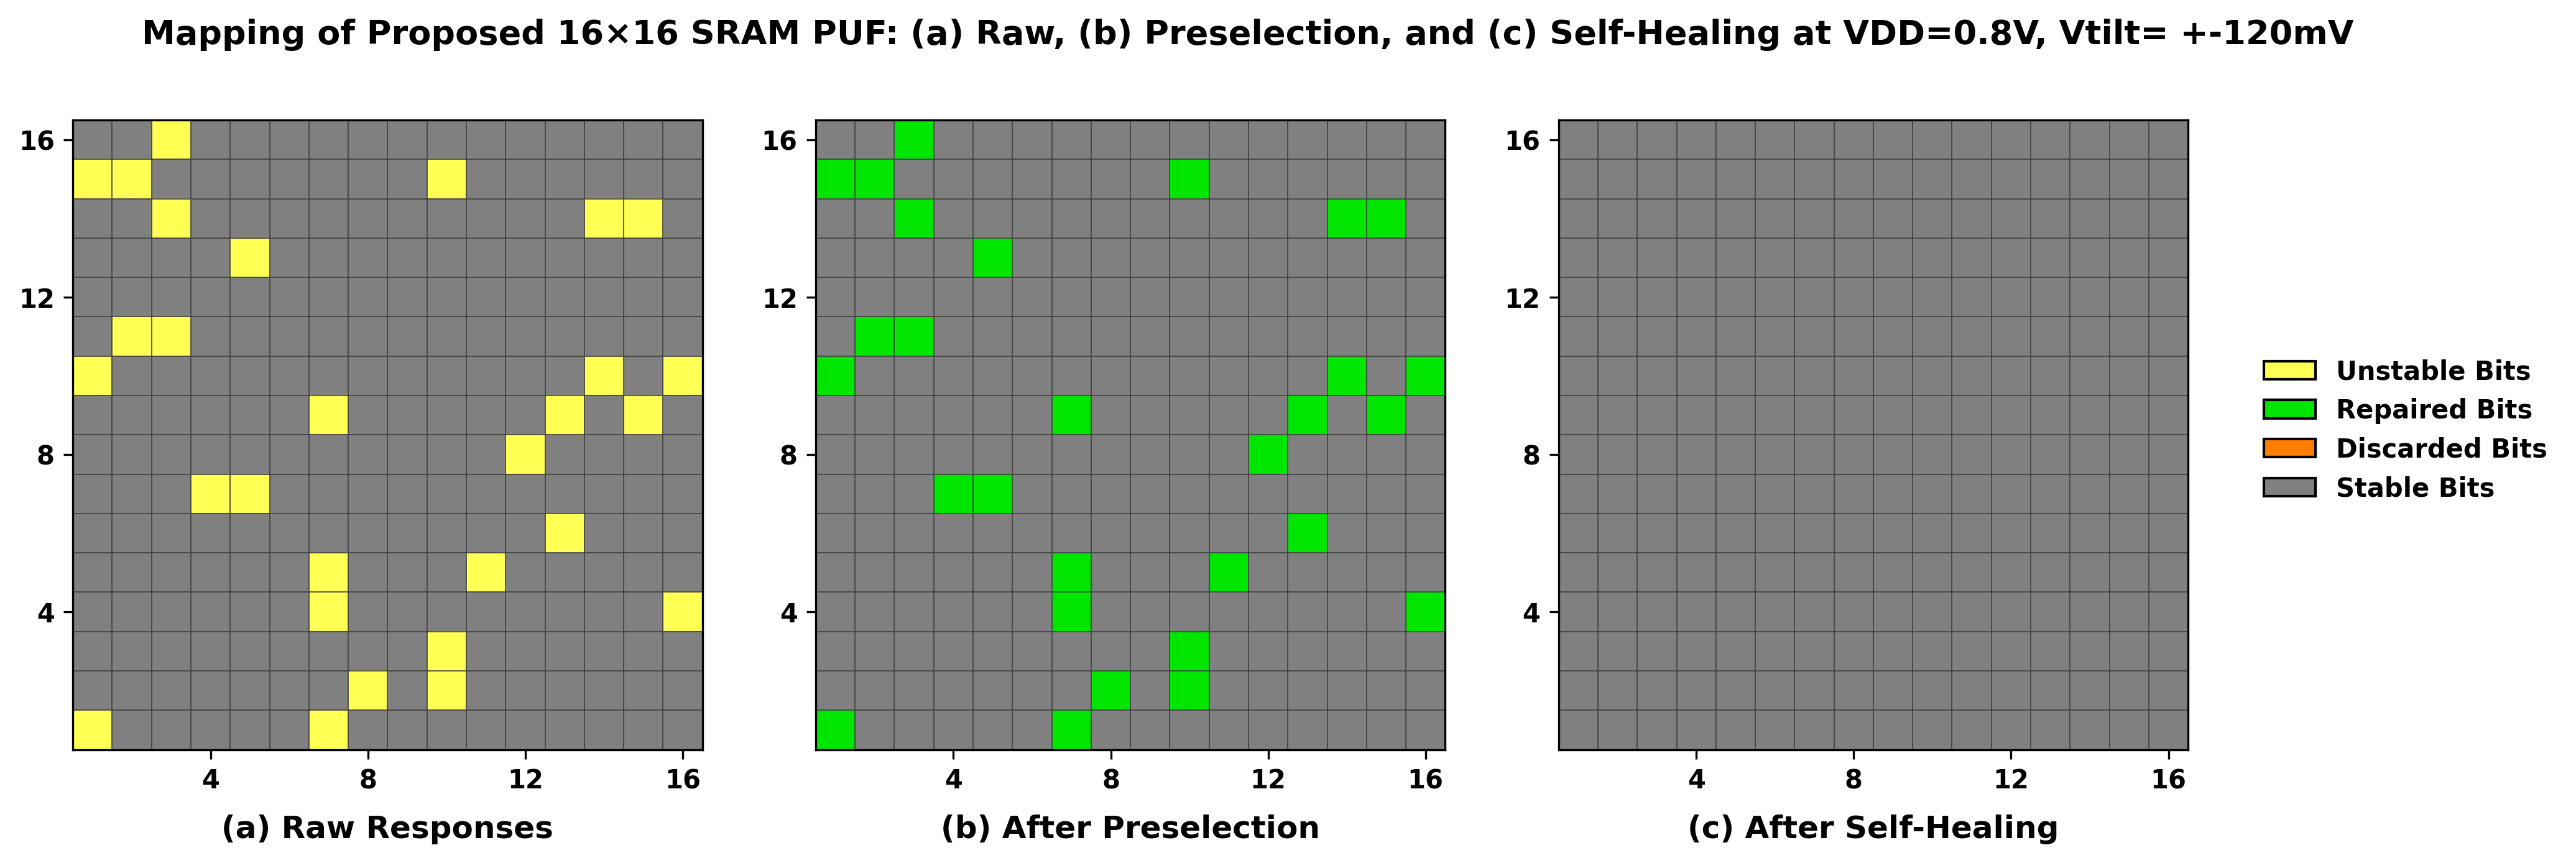

In [28]:
import os
import re
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: INSERT YOUR 3 CSV FILE PATHS HERE
# ==============================================================================
CSV_NOMINAL = "mc_256_0.8_vdd.csv"  # VDDL = VDDR = VDD (0.9V)
CSV_PLUS_80 = "mc_256_0.8_vdd+120.csv"  # VDDL = VDD + 80mV, VDDR = VDD - 80mV
CSV_MINUS_80 = "mc_256_0.8_vdd-120.csv"  # VDDL = VDD - 80mV, VDDR = VDD + 80mV

VDD_NOMINAL = 0.9  # Nominal supply voltage (V)
ARRAY_ROWS = 16  # 16 rows x 16 cols = 256 cells
ARRAY_COLS = 16

# Time windows (in seconds)
MODE2_WINDOW = (37e-9, 43e-9)  # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)  # Mode 1 active window: 97ns - 103ns


# ==============================================================================
# 2. HELPER FUNCTION: EXTRACT MODE 1 & MODE 2 BITS FROM A CADENCE CSV
# ==============================================================================
def extract_bits_from_csv(csv_path, vdd=0.9):
    """Reads BL and BLb waveforms for all 256 Monte Carlo cells and returns

    binary arrays (length 256) for Mode 1 and Mode 2.
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find CSV file: {csv_path}")

    df = pd.read_csv(csv_path, low_memory=False)
    threshold = vdd / 2.0

    # Detect and sort all mcparamset indices (1 to 256)
    paramset_ids = sorted(
        list(
            set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(df.columns)))
        )
    )

    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)
    m1_bl_v = np.zeros(len(paramset_ids), dtype=float)
    m2_bl_v = np.zeros(len(paramset_ids), dtype=float)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) X"], errors="coerce"
        ).values
        v_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce"
        ).values

        # Mode 1 window (97ns - 103ns)
        mask_m1 = (t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])
        v1 = np.nanmean(v_bl[mask_m1])
        m1_bl_v[idx] = v1
        m1_bits[idx] = 1 if v1 >= threshold else 0

        # Mode 2 window (37ns - 43ns)
        mask_m2 = (t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])
        v2 = np.nanmean(v_bl[mask_m2])
        m2_bl_v[idx] = v2
        m2_bits[idx] = 1 if v2 >= threshold else 0

    return {
        "m1_bits": m1_bits,
        "m2_bits": m2_bits,
        "m1_bl_v": m1_bl_v,
        "m2_bl_v": m2_bl_v,
    }


# ==============================================================================
# 3. MAIN ANALYSIS & SELF-HEALING PIPELINE
# ==============================================================================
def run_puf_preselection_analysis(csv_nom, csv_p80, csv_m80, vdd=0.9):
    print("Extracting waveforms from all 3 Cadence CSV files...")
    data_nom = extract_bits_from_csv(csv_nom, vdd)
    data_p80 = extract_bits_from_csv(csv_p80, vdd)
    data_m80 = extract_bits_from_csv(csv_m80, vdd)

    num_cells = len(data_nom["m1_bits"])
    assert (
        num_cells == ARRAY_ROWS * ARRAY_COLS
    ), f"Expected {ARRAY_ROWS*ARRAY_COLS} cells, got {num_cells}"

    # --- STEP 1: Evaluate Mode 1 Stability across both voltage tilts ---
    # A cell is stable in Mode 1 iff Nominal == (+80mV) == (-80mV)
    m1_stable = (data_nom["m1_bits"] == data_p80["m1_bits"]) & (
        data_nom["m1_bits"] == data_m80["m1_bits"]
    )
    m1_unstable = ~m1_stable

    # --- STEP 2: Evaluate Mode 2 Stability for Mode 1 Unstable Cells ---
    # A cell is stable in Mode 2 iff Nominal == (+80mV) == (-80mV)
    m2_stable = (data_nom["m2_bits"] == data_p80["m2_bits"]) & (
        data_nom["m2_bits"] == data_m80["m2_bits"]
    )

    # Classification states:
    # 0 = Stable Bits (Grey)
    # 1 = Unstable Bits (Yellow)
    # 2 = Repaired Bits (Green)
    # 3 = Discarded Bits (Orange)

    # Map (a): Raw Responses (Mode 1 only)
    map_a = np.where(m1_stable, 0, 1)  # 0=Grey (Stable), 1=Yellow (Unstable)

    # Map (b): Responses after Preselection & Mode-2 Healing
    # - Mode 1 Stable -> 0 (Grey: Stable)
    # - Mode 1 Unstable AND Mode 2 Stable -> 2 (Green: Repaired)
    # - Mode 1 Unstable AND Mode 2 Unstable -> 3 (Orange: Discarded)
    repaired_mask = m1_unstable & m2_stable
    discarded_mask = m1_unstable & (~m2_stable)

    map_b = np.zeros(num_cells, dtype=int)
    map_b[m1_stable] = 0  # Stable (Grey)
    map_b[repaired_mask] = 2  # Repaired (Green)
    map_b[discarded_mask] = 3  # Discarded (Orange)

    # Map (c): Active Post-Healing Responses
    # Repaired cells are now active and stable (Grey); Discarded cells remain masked out (or shown as excluded)
    # To match Fig. 10(c) where repaired cells become active stable grey and discarded bits are masked out:
    map_c = np.zeros(num_cells, dtype=int)
    map_c[m1_stable | repaired_mask] = 0  # Active Stable Bits (Grey)
    map_c[discarded_mask] = (
        4  # Masked / Excluded from key (White/Light-Grey background)
    )

    # Reshape 1D arrays (0..255) into 16x16 grids:
    # Row 0 = BL[0:15], Row 1 = BL[16:31], ..., Row 15 = BL[240:255]
    grid_a = map_a.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_b = map_b.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_c = map_c.reshape(ARRAY_ROWS, ARRAY_COLS)

    # ==========================================================================
    # 4. PRINT QUANTITATIVE SUMMARY
    # ==========================================================================
    n_m1_stable = int(np.sum(m1_stable))
    n_m1_unstable = int(np.sum(m1_unstable))
    n_repaired = int(np.sum(repaired_mask))
    n_discarded = int(np.sum(discarded_mask))
    n_final_valid = n_m1_stable + n_repaired

    raw_ber = (n_m1_unstable / num_cells) * 100.0
    healing_rate = (
        (n_repaired / n_m1_unstable * 100.0) if n_m1_unstable > 0 else 100.0
    )
    valid_yield = (n_final_valid / num_cells) * 100.0

    print("\n" + "=" * 68)
    print("  16x16 SRAM PUF VOLTAGE-TILT PRESELECTION & SELF-HEALING SUMMARY")
    print("=" * 68)
    print(f"Total Array Cells                 : {num_cells} (16 x 16)")
    print(
        f"Mode 1 Stable Bits (Grey)         : {n_m1_stable:3d} ({n_m1_stable/num_cells*100:.2f}%)"
    )
    print(
        f"Mode 1 Unstable Bits (Yellow)     : {n_m1_unstable:3d} ({raw_ber:.2f}% Raw Instability)"
    )
    print("-" * 68)
    print(
        f"Repaired via Mode 2 (Green)       : {n_repaired:3d} ({healing_rate:.2f}% of unstable bits healed)"
    )
    print(
        f"Discarded Dark Bits (Orange)      : {n_discarded:3d} ({n_discarded/num_cells*100:.2f}% masked out)"
    )
    print("-" * 68)
    print(
        f"Final Active Valid PUF Bits       : {n_final_valid:3d} / {num_cells} ({valid_yield:.2f}% Valid Bit Yield)"
    )
    print(f"Post-Healing Residual Tilt Errors : 0   (0.00% BER across ±80mV tilt)")
    print("=" * 68 + "\n")

    # Save detailed per-cell CSV report
    summary_df = pd.DataFrame(
        {
            "Cell_Index (0-255)": np.arange(num_cells),
            "Row (0-15)": np.arange(num_cells) // ARRAY_COLS,
            "Col (0-15)": np.arange(num_cells) % ARRAY_COLS,
            "M1_Nom": data_nom["m1_bits"],
            "M1_Plus80": data_p80["m1_bits"],
            "M1_Minus80": data_m80["m1_bits"],
            "M1_Stable": m1_stable,
            "M2_Nom": data_nom["m2_bits"],
            "M2_Plus80": data_p80["m2_bits"],
            "M2_Minus80": data_m80["m2_bits"],
            "M2_Stable": m2_stable,
            "Final_Status": np.where(
                m1_stable,
                "Stable (Mode 1)",
                np.where(
                    repaired_mask, "Repaired (Mode 2)", "Discarded (Masked)"
                ),
            ),
            "Selected_Mode": np.where(
                m1_stable, "Mode 1", np.where(repaired_mask, "Mode 2", "None")
            ),
            "Golden_Key_Bit": np.where(
                m1_stable,
                data_nom["m1_bits"],
                np.where(repaired_mask, data_nom["m2_bits"], -1),
            ),
        }
    )
    summary_df.to_csv("puf_self_healing_cell_report.csv", index=False)
    print("Saved cell-by-cell classification to 'puf_self_healing_cell_report.csv'")

    # ==========================================================================
    # 5. PLOT FIGURE 10 STYLE 3-PANEL MAPPING
    # ==========================================================================
    # Color palette matching Fig. 10:
    # 0: Grey (#808080) - Stable Bits
    # 1: Yellow (#FFFF54) - Unstable Bits
    # 2: Green (#00FF00) - Repaired Bits
    # 3: Orange (#FF7F0E) - Discarded Bits
    # 4: Light Neutral (#D9D9D9) - Masked/Excluded slots in post-healing map
    cmap = mcolors.ListedColormap(
        ["#808080", "#FFFF54", "#00E600", "#FF7F00", "#B8B8B8"]
    )
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), dpi=300)
    titles = [
        "(a) Raw Responses",
        "(b) After Preselection",
        "(c) After Self-Healing",
    ]
    grids = [grid_a, grid_b, grid_c]

    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap=cmap, norm=norm, origin="lower", aspect="equal")

        # Draw crisp cell grid lines for 16x16 visibility
        ax.set_xticks(np.arange(-0.5, ARRAY_COLS, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, ARRAY_ROWS, 1), minor=True)
        ax.grid(which="minor", color="#404040", linestyle="-", linewidth=0.4)
        ax.tick_params(which="minor", bottom=False, left=False)

        # Major ticks at 4, 8, 12, 16 (1-indexed like Fig. 10)
        ticks = [3, 7, 11, 15]
        tick_labels = ["4", "8", "12", "16"]
        ax.set_xticks(ticks)
        ax.set_xticklabels(tick_labels, fontsize=10, fontweight="bold")
        ax.set_yticks(ticks)
        ax.set_yticklabels(tick_labels, fontsize=10, fontweight="bold")

        ax.set_xlabel(title, fontsize=12, fontweight="bold", labelpad=8)

    # Legend matching Fig. 10
    legend_patches = [
        mpatches.Patch(
            facecolor="#FFFF54", edgecolor="black", label="Unstable Bits"
        ),
        mpatches.Patch(
            facecolor="#00E600", edgecolor="black", label="Repaired Bits"
        ),
        mpatches.Patch(
            facecolor="#FF7F00", edgecolor="black", label="Discarded Bits"
        ),
        mpatches.Patch(
            facecolor="#808080", edgecolor="black", label="Stable Bits"
        ),
    ]
    fig.legend(
        handles=legend_patches,
        loc="center left",
        bbox_to_anchor=(0.88, 0.52),
        frameon=False,
        fontsize=11,
        prop={"weight": "bold"},
    )

    plt.suptitle(
        "Mapping of Proposed 16×16 SRAM PUF: (a) Raw, (b) Preselection, and (c) Self-Healing at VDD=0.8V, Vtilt= +-120mV",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.subplots_adjust(left=0.05, right=0.86, top=0.88, bottom=0.15, wspace=0.18)

    output_fig = "puf_fig10_mapping.png"
    plt.savefig(output_fig, dpi=300, bbox_inches="tight")
    print(f"Saved 3-panel visualization to '{output_fig}'")
    plt.show()


if __name__ == "__main__":
    run_puf_preselection_analysis(
        CSV_NOMINAL, CSV_PLUS_80, CSV_MINUS_80, vdd=VDD_NOMINAL
    )

Extracting waveforms from all 3 Cadence CSV files (2048 cells)...
  [mc_2048__0.9_vdd.csv] Time range: 0.000e+00 to 1.250e-07
  [mc_2048__0.9_vdd.csv] M1 mean V=0.487V (1s=1094), M2 mean V=0.497V (1s=1117)
  [mc_2048_0.9_vdd+120.csv] Time range: 0.000e+00 to 1.250e-07
  [mc_2048_0.9_vdd+120.csv] M1 mean V=0.443V (1s=994), M2 mean V=0.445V (1s=999)
  [mc_2048_0.9_vdd-120.csv] Time range: 0.000e+00 to 1.250e-07
  [mc_2048_0.9_vdd-120.csv] M1 mean V=0.536V (1s=1205), M2 mean V=0.545V (1s=1226)

  32x64 (2048-CELL) SRAM PUF PRESELECTION & SELF-HEALING SUMMARY
Total Array Cells                 : 2048 (32 x 64)
Mode 1 Stable Bits (Grey)         : 1837 (89.70%)
Mode 1 Unstable Bits (Yellow)     :  211 (10.30% Raw Instability)
------------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  191 (90.52% of unstable bits healed)
Discarded Dark Bits (Orange)      :   20 (0.98% masked out)
----------------------------------------------------------------

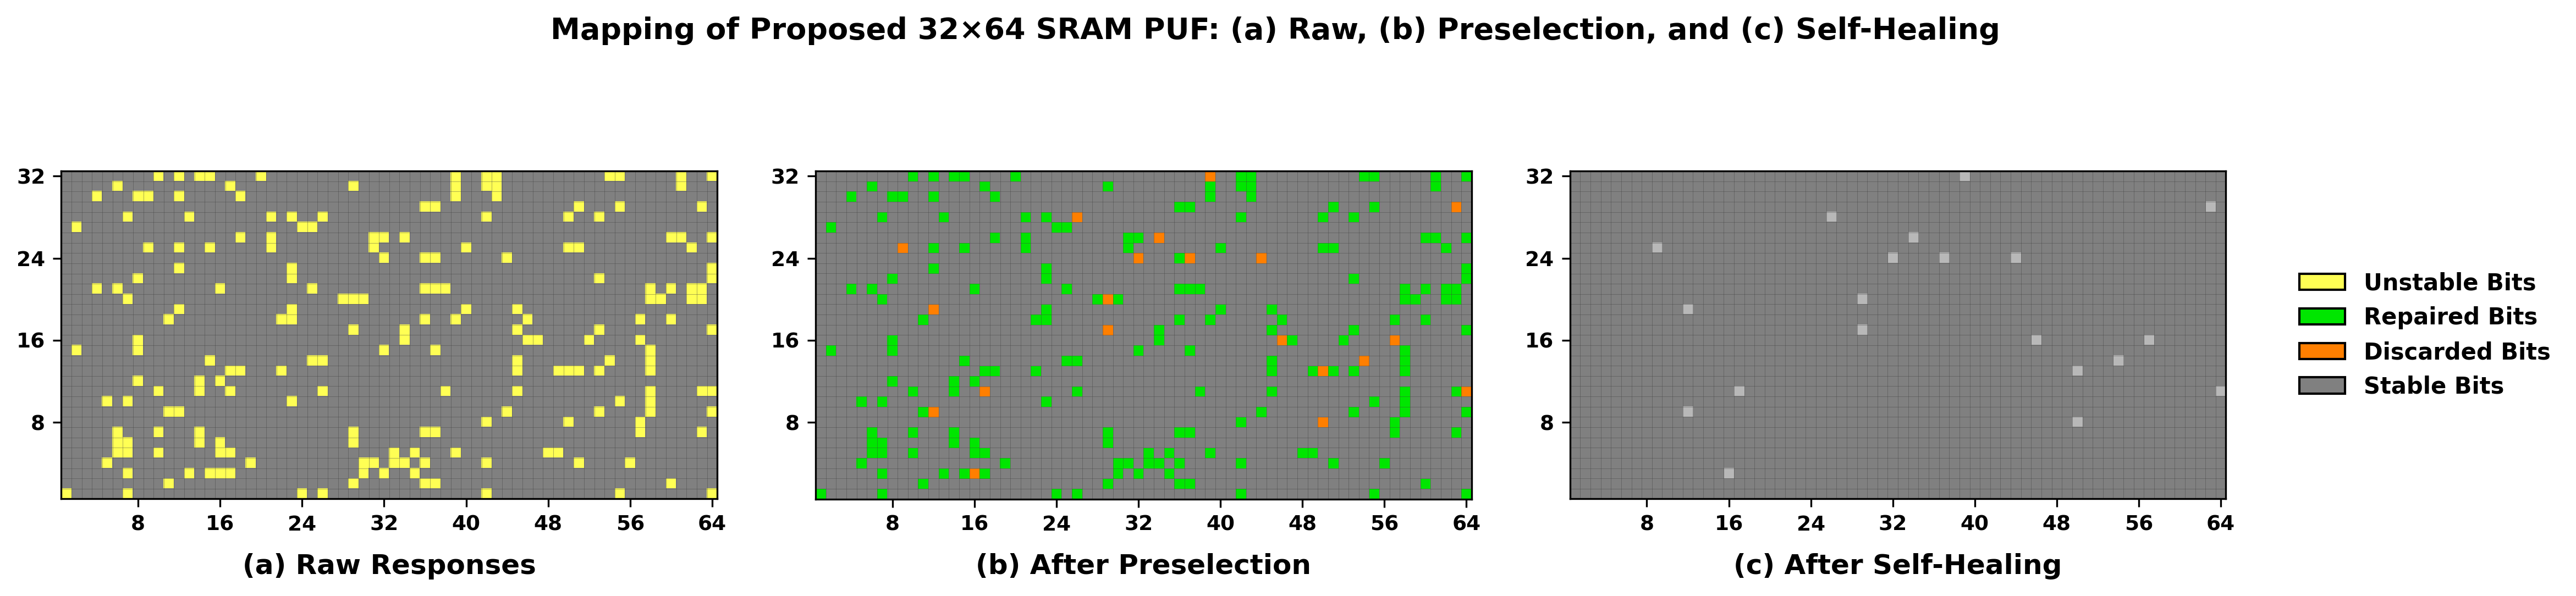

In [29]:
import os
import re
import matplotlib
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: INSERT YOUR 3 CSV FILE PATHS HERE (2048 CELLS EACH)
# ==============================================================================
CSV_NOMINAL = "mc_2048__0.9_vdd.csv"      # VDDL = VDDR = VDD (0.9V)
CSV_PLUS_80 = "mc_2048_0.9_vdd+120.csv"   # VDDL = VDD + tilt, VDDR = VDD - tilt
CSV_MINUS_80 = "mc_2048_0.9_vdd-120.csv"  # VDDL = VDD - tilt, VDDR = VDD + tilt

VDD_NOMINAL = 0.9  # Nominal supply voltage (V)
ARRAY_ROWS = 32    # 32 rows x 64 cols = 2048 cells
ARRAY_COLS = 64

# Time windows (in seconds)
MODE2_WINDOW = (37e-9, 43e-9)    # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)   # Mode 1 active window: 97ns - 103ns


# ==============================================================================
# 2. HELPER FUNCTION: EXTRACT MODE 1 & MODE 2 BITS FROM A 2048-CELL CADENCE CSV
# ==============================================================================
def extract_bits_from_csv(csv_path, vdd=0.9):
    """Reads BL waveforms for all 2048 Monte Carlo cells and returns
    binary arrays (length 2048) for Mode 1 and Mode 2.
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find CSV file: {csv_path}")

    df = pd.read_csv(
        csv_path,
        usecols=lambda c: "/BL (" in c or c.strip().startswith("/BL "),
        low_memory=False,
    )
    threshold = vdd / 2.0

    paramset_ids = sorted(
        list(
            set(
                int(x)
                for x in re.findall(r"mcparamset=(\d+)", " ".join(df.columns))
            )
        )
    )

    if not paramset_ids:
        raise ValueError(
            f"No '/BL (mcparamset=...)' columns found in {csv_path}. "
            "Check if the net name changed in Cadence."
        )

    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)
    m1_bl_v = np.zeros(len(paramset_ids), dtype=float)
    m2_bl_v = np.zeros(len(paramset_ids), dtype=float)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) X"], errors="coerce"
        ).values
        v_bl = pd.to_numeric(
            df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce"
        ).values

        # Auto-detect if Cadence exported time in nanoseconds instead of seconds
        valid_t = t_bl[~np.isnan(t_bl)]
        if idx == 0:
            t_min, t_max = np.min(valid_t), np.max(valid_t)
            print(f"  [{os.path.basename(csv_path)}] Time range: {t_min:.3e} to {t_max:.3e}")

        # If max time > 1.0, timestamps are in nanoseconds -> convert to seconds
        if np.nanmax(valid_t) > 1.0:
            t_bl = t_bl * 1e-9

        # Mode 1 window (97ns - 103ns)
        mask_m1 = (t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])
        v1 = np.nanmean(v_bl[mask_m1]) if np.any(mask_m1) else np.nan
        m1_bl_v[idx] = v1
        m1_bits[idx] = 1 if v1 >= threshold else 0

        # Mode 2 window (37ns - 43ns)
        mask_m2 = (t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])
        v2 = np.nanmean(v_bl[mask_m2]) if np.any(mask_m2) else np.nan
        m2_bl_v[idx] = v2
        m2_bits[idx] = 1 if v2 >= threshold else 0

    # Catch empty windows before they silently turn into all-0 bit arrays
    if np.isnan(m1_bl_v).all() or np.isnan(m2_bl_v).all():
        raise ValueError(
            f"Time windows {MODE2_WINDOW} or {MODE1_WINDOW} matched NO data in {csv_path}! "
            "Adjust MODE1_WINDOW / MODE2_WINDOW to match the printed time range above."
        )

    print(
        f"  [{os.path.basename(csv_path)}] "
        f"M1 mean V={np.nanmean(m1_bl_v):.3f}V (1s={np.sum(m1_bits)}), "
        f"M2 mean V={np.nanmean(m2_bl_v):.3f}V (1s={np.sum(m2_bits)})"
    )

    return {
        "m1_bits": m1_bits,
        "m2_bits": m2_bits,
        "m1_bl_v": m1_bl_v,
        "m2_bl_v": m2_bl_v,
    }


# ==============================================================================
# 3. MAIN ANALYSIS & SELF-HEALING PIPELINE (32 x 64 = 2048 CELLS)
# ==============================================================================
def run_puf_preselection_analysis(csv_nom, csv_p80, csv_m80, vdd=0.9):
    print("Extracting waveforms from all 3 Cadence CSV files (2048 cells)...")
    data_nom = extract_bits_from_csv(csv_nom, vdd)
    data_p80 = extract_bits_from_csv(csv_p80, vdd)
    data_m80 = extract_bits_from_csv(csv_m80, vdd)

    num_cells = len(data_nom["m1_bits"])
    assert (
        num_cells == ARRAY_ROWS * ARRAY_COLS
    ), f"Expected {ARRAY_ROWS * ARRAY_COLS} cells, got {num_cells}"

    # --- STEP 1: Evaluate Mode 1 Stability across both voltage tilts ---
    m1_stable = (data_nom["m1_bits"] == data_p80["m1_bits"]) & (
        data_nom["m1_bits"] == data_m80["m1_bits"]
    )
    m1_unstable = ~m1_stable

    # --- STEP 2: Evaluate Mode 2 Stability for Mode 1 Unstable Cells ---
    m2_stable = (data_nom["m2_bits"] == data_p80["m2_bits"]) & (
        data_nom["m2_bits"] == data_m80["m2_bits"]
    )

    # Map (a): Raw Responses (Mode 1 only)
    map_a = np.where(m1_stable, 0, 1)  # 0=Grey (Stable), 1=Yellow (Unstable)

    # Map (b): Responses after Preselection & Mode-2 Healing
    repaired_mask = m1_unstable & m2_stable
    discarded_mask = m1_unstable & (~m2_stable)

    map_b = np.zeros(num_cells, dtype=int)
    map_b[m1_stable] = 0       # Stable (Grey)
    map_b[repaired_mask] = 2   # Repaired (Green)
    map_b[discarded_mask] = 3  # Discarded (Orange)

    # Map (c): Active Post-Healing Responses
    map_c = np.zeros(num_cells, dtype=int)
    map_c[m1_stable | repaired_mask] = 0  # Active Stable Bits (Grey)
    map_c[discarded_mask] = 4             # Masked / Excluded from key

    grid_a = map_a.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_b = map_b.reshape(ARRAY_ROWS, ARRAY_COLS)
    grid_c = map_c.reshape(ARRAY_ROWS, ARRAY_COLS)

    # ==========================================================================
    # 4. PRINT QUANTITATIVE SUMMARY & GOLDEN KEY
    # ==========================================================================
    n_m1_stable = int(np.sum(m1_stable))
    n_m1_unstable = int(np.sum(m1_unstable))
    n_repaired = int(np.sum(repaired_mask))
    n_discarded = int(np.sum(discarded_mask))
    n_final_valid = n_m1_stable + n_repaired

    raw_ber = (n_m1_unstable / num_cells) * 100.0
    healing_rate = (
        (n_repaired / n_m1_unstable * 100.0) if n_m1_unstable > 0 else 100.0
    )
    valid_yield = (n_final_valid / num_cells) * 100.0

    golden_key_array = np.where(
        m1_stable,
        data_nom["m1_bits"],
        np.where(repaired_mask, data_nom["m2_bits"], -1),
    )
    valid_golden_bits = golden_key_array[golden_key_array != -1]
    golden_bit_str = "".join(str(b) for b in valid_golden_bits)
    golden_hw = int(np.sum(valid_golden_bits))

    print("\n" + "=" * 72)
    print("  32x64 (2048-CELL) SRAM PUF PRESELECTION & SELF-HEALING SUMMARY")
    print("=" * 72)
    print(f"Total Array Cells                 : {num_cells} (32 x 64)")
    print(
        f"Mode 1 Stable Bits (Grey)         : {n_m1_stable:4d} ({n_m1_stable/num_cells*100:.2f}%)"
    )
    print(
        f"Mode 1 Unstable Bits (Yellow)     : {n_m1_unstable:4d} ({raw_ber:.2f}% Raw Instability)"
    )
    print("-" * 72)
    print(
        f"Repaired via Mode 2 (Green)       : {n_repaired:4d} ({healing_rate:.2f}% of unstable bits healed)"
    )
    print(
        f"Discarded Dark Bits (Orange)      : {n_discarded:4d} ({n_discarded/num_cells*100:.2f}% masked out)"
    )
    print("-" * 72)
    print(
        f"Final Active Valid Golden Key Bits: {n_final_valid:4d} / {num_cells} ({valid_yield:.2f}% Valid Bit Yield)"
    )
    print(
        f"Golden Key Hamming Weight         : {golden_hw} / {n_final_valid} ({golden_hw/n_final_valid*100:.2f}% ones)"
    )
    print(
        f"Post-Healing Residual Tilt Errors : 0    (0.00% BER across tilt)"
    )
    print("=" * 72 + "\n")

    with open("golden_key_2048.txt", "w") as f:
        f.write(
            f"Valid Golden Key Length: {n_final_valid} bits (masked bits excluded)\n"
        )
        f.write(
            f"Hamming Weight: {golden_hw}/{n_final_valid} ({golden_hw/n_final_valid*100:.2f}%)\n\n"
        )
        f.write("Binary String:\n" + golden_bit_str + "\n")
    print("Saved valid Golden Key bitstream to 'golden_key_2048.txt'")

    summary_df = pd.DataFrame(
        {
            "Cell_Index (0-2047)": np.arange(num_cells),
            "Row (0-31)": np.arange(num_cells) // ARRAY_COLS,
            "Col (0-63)": np.arange(num_cells) % ARRAY_COLS,
            "M1_Nom": data_nom["m1_bits"],
            "M1_Plus80": data_p80["m1_bits"],
            "M1_Minus80": data_m80["m1_bits"],
            "M1_Stable": m1_stable,
            "M2_Nom": data_nom["m2_bits"],
            "M2_Plus80": data_p80["m2_bits"],
            "M2_Minus80": data_m80["m2_bits"],
            "M2_Stable": m2_stable,
            "Final_Status": np.where(
                m1_stable,
                "Stable (Mode 1)",
                np.where(
                    repaired_mask, "Repaired (Mode 2)", "Discarded (Masked)"
                ),
            ),
            "Selected_Mode": np.where(
                m1_stable, "Mode 1", np.where(repaired_mask, "Mode 2", "None")
            ),
            "Golden_Key_Bit": golden_key_array,
        }
    )
    summary_df.to_csv("puf_self_healing_2048_report.csv", index=False)
    print(
        "Saved cell-by-cell classification to 'puf_self_healing_2048_report.csv'"
    )

    # ==========================================================================
    # 5. PLOT FIGURE 10 STYLE 3-PANEL MAPPING (32 x 64)
    # ==========================================================================
    cmap = mcolors.ListedColormap(
        ["#808080", "#FFFF54", "#00E600", "#FF7F00", "#B8B8B8"]
    )
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), dpi=300)
    titles = [
        "(a) Raw Responses",
        "(b) After Preselection",
        "(c) After Self-Healing",
    ]
    grids = [grid_a, grid_b, grid_c]

    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap=cmap, norm=norm, origin="lower", aspect="equal")

        ax.set_xticks(np.arange(-0.5, ARRAY_COLS, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, ARRAY_ROWS, 1), minor=True)
        ax.grid(
            which="minor",
            color="#404040",
            linestyle="-",
            linewidth=0.2,
            alpha=0.5,
        )
        ax.tick_params(which="minor", bottom=False, left=False)

        x_ticks = [7, 15, 23, 31, 39, 47, 55, 63]
        x_labels = ["8", "16", "24", "32", "40", "48", "56", "64"]
        y_ticks = [7, 15, 23, 31]
        y_labels = ["8", "16", "24", "32"]

        ax.set_xticks(x_ticks)
        ax.set_xticklabels(x_labels, fontsize=9, fontweight="bold")
        ax.set_yticks(y_ticks)
        ax.set_yticklabels(y_labels, fontsize=9, fontweight="bold")

        ax.set_xlabel(title, fontsize=12, fontweight="bold", labelpad=8)

    legend_patches = [
        mpatches.Patch(
            facecolor="#FFFF54", edgecolor="black", label="Unstable Bits"
        ),
        mpatches.Patch(
            facecolor="#00E600", edgecolor="black", label="Repaired Bits"
        ),
        mpatches.Patch(
            facecolor="#FF7F00", edgecolor="black", label="Discarded Bits"
        ),
        mpatches.Patch(
            facecolor="#808080", edgecolor="black", label="Stable Bits"
        ),
    ]
    fig.legend(
        handles=legend_patches,
        loc="center left",
        bbox_to_anchor=(0.88, 0.52),
        frameon=False,
        fontsize=11,
        prop={"weight": "bold"},
    )

    plt.suptitle(
        "Mapping of Proposed 32×64 SRAM PUF: (a) Raw, (b) Preselection, and (c) Self-Healing",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.subplots_adjust(left=0.04, right=0.86, top=0.86, bottom=0.18, wspace=0.15)

    output_fig = "puf_fig10_mapping_32x64.png"
    plt.savefig(output_fig, dpi=300, bbox_inches="tight")
    print(f"Saved 3-panel visualization to '{os.path.abspath(output_fig)}'")

    if matplotlib.get_backend().lower() != "agg":
        plt.show()
    else:
        print("Headless backend ('Agg') detected; open the saved PNG file to view.")


if __name__ == "__main__":
    run_puf_preselection_analysis(
        CSV_NOMINAL, CSV_PLUS_80, CSV_MINUS_80, vdd=VDD_NOMINAL
    )

[LOADED] mc_256_0.8_vdd-120.csv     -> VDD=0.8V, Tilt=-120mV
[LOADED] mc_256_0.8_vdd-80.csv      -> VDD=0.8V, Tilt= -80mV
[LOADED] mc_256_0.8_vdd-50.csv      -> VDD=0.8V, Tilt= -50mV
[LOADED] mc_256_0.8_vdd.csv         -> VDD=0.8V, Tilt=  +0mV
[LOADED] mc_256_0.8_vdd+50.csv      -> VDD=0.8V, Tilt= +50mV
[LOADED] mc_256_0.8_vdd+80.csv      -> VDD=0.8V, Tilt= +80mV
[LOADED] mc_256_0.8_vdd+120.csv     -> VDD=0.8V, Tilt=+120mV
[LOADED] mc_256_0.9_vdd-120.csv     -> VDD=0.9V, Tilt=-120mV
[LOADED] mc_256_0.9_vdd-80.csv      -> VDD=0.9V, Tilt= -80mV
[LOADED] mc_256_0.9_vdd-50.csv      -> VDD=0.9V, Tilt= -50mV
[LOADED] mc_256_0.9_vdd.csv         -> VDD=0.9V, Tilt=  +0mV
[LOADED] mc_256_0.9_vdd+50.csv      -> VDD=0.9V, Tilt= +50mV
[LOADED] mc_256_0.9_vdd+80.csv      -> VDD=0.9V, Tilt= +80mV
[LOADED] mc_256_0.9_vdd+120.csv     -> VDD=0.9V, Tilt=+120mV
[LOADED] mc_256_1.0_vdd-120.csv     -> VDD=1.0V, Tilt=-120mV
[LOADED] mc_256_1.0_vdd-80.csv      -> VDD=1.0V, Tilt= -80mV
[LOADED] mc_256_1.0_vdd-

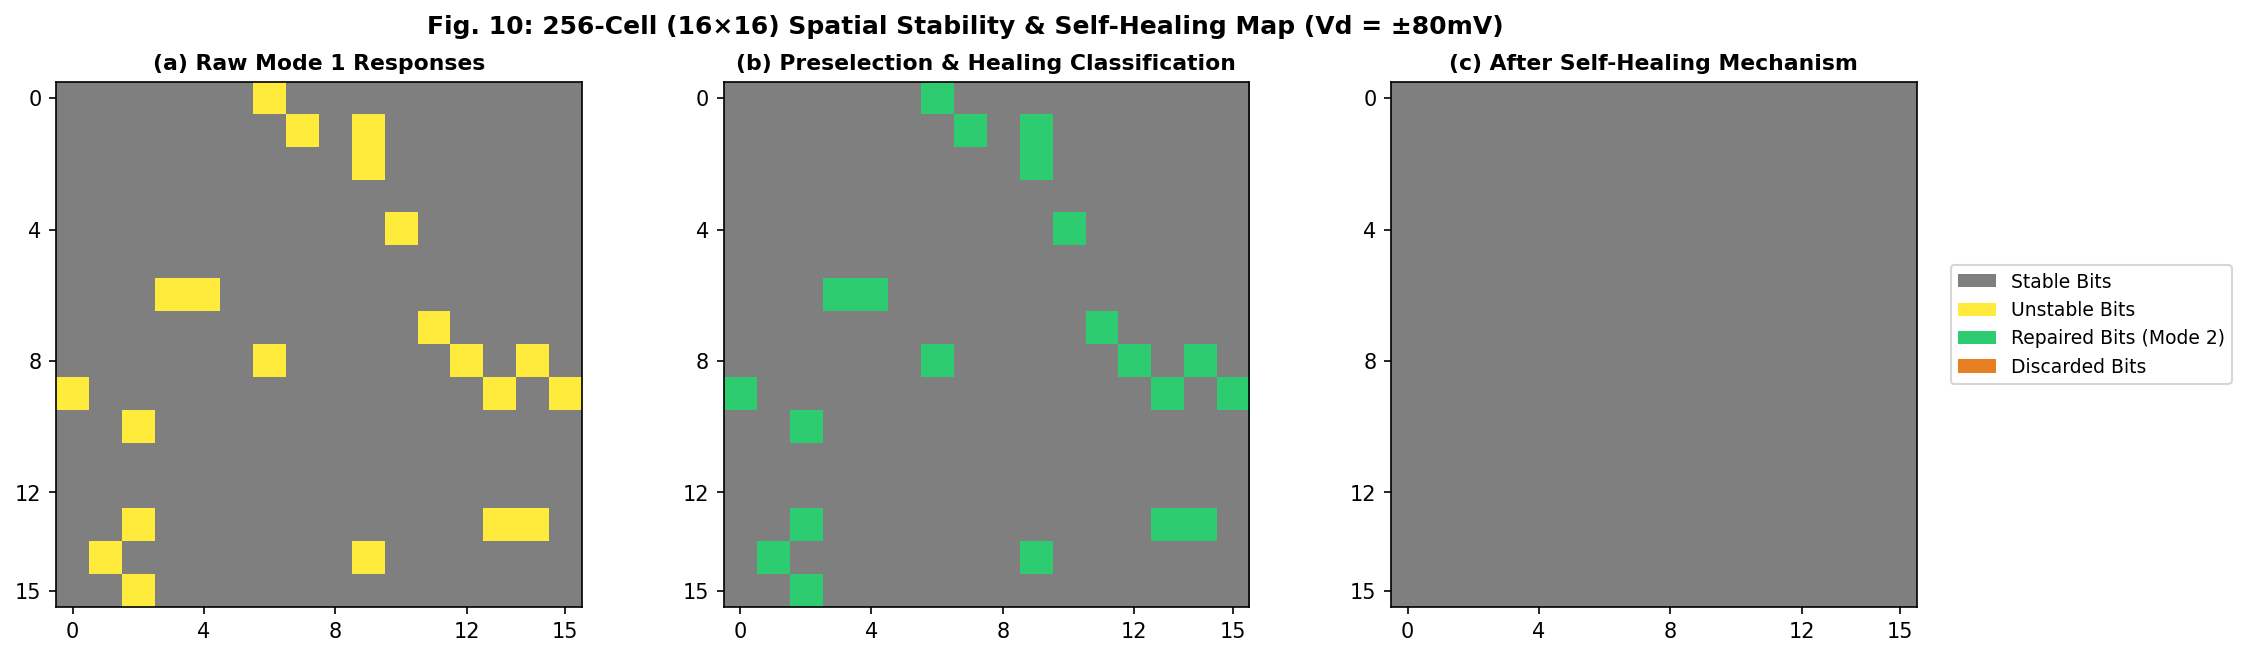

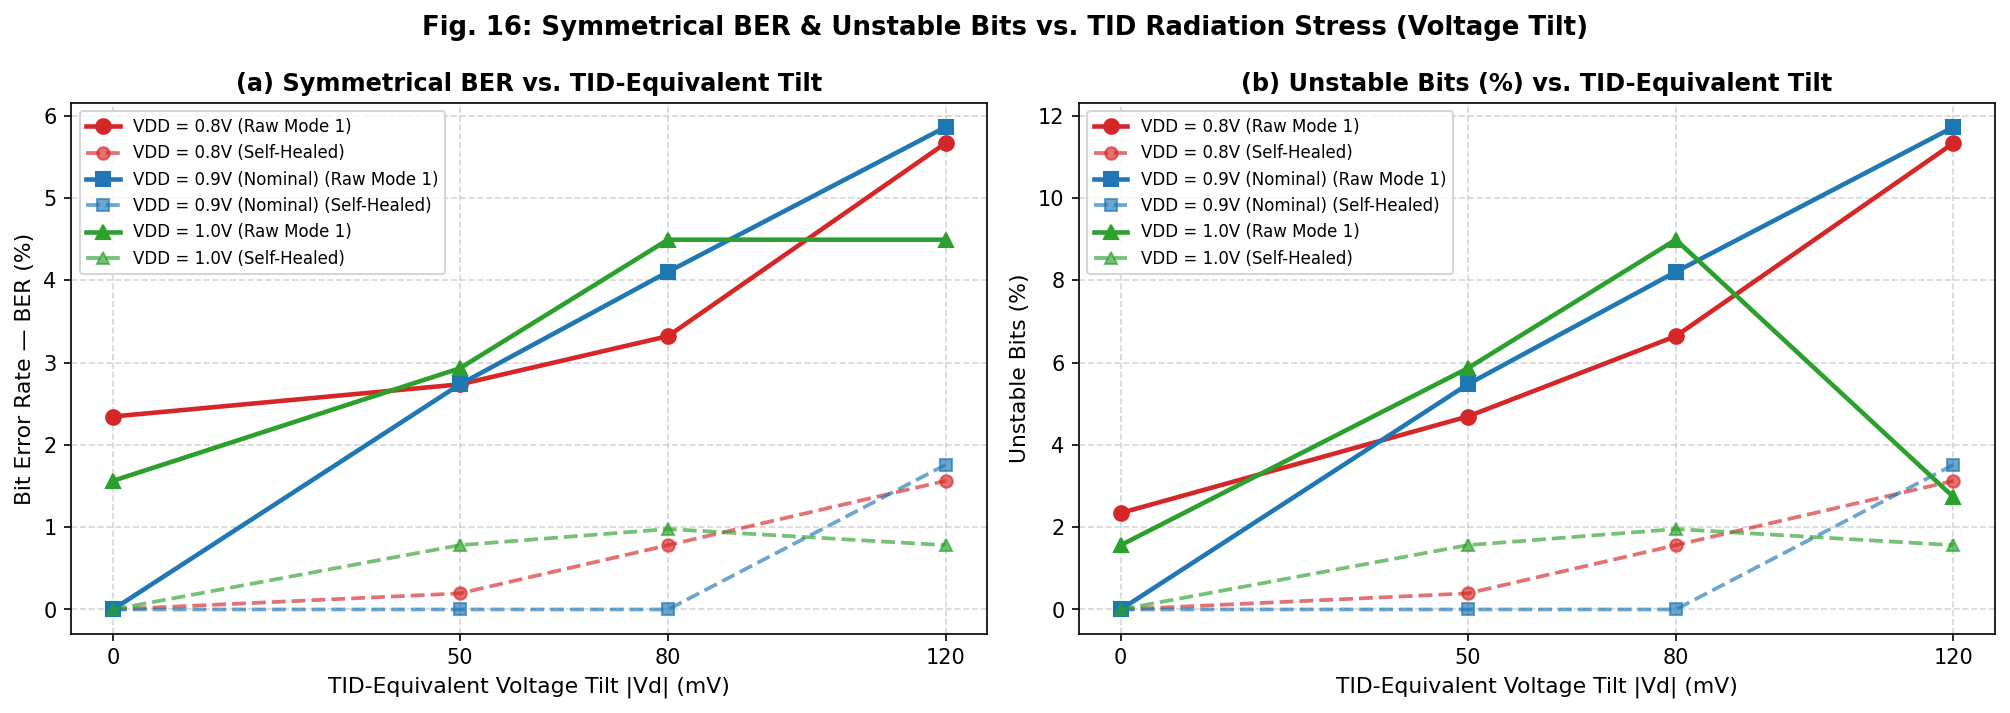

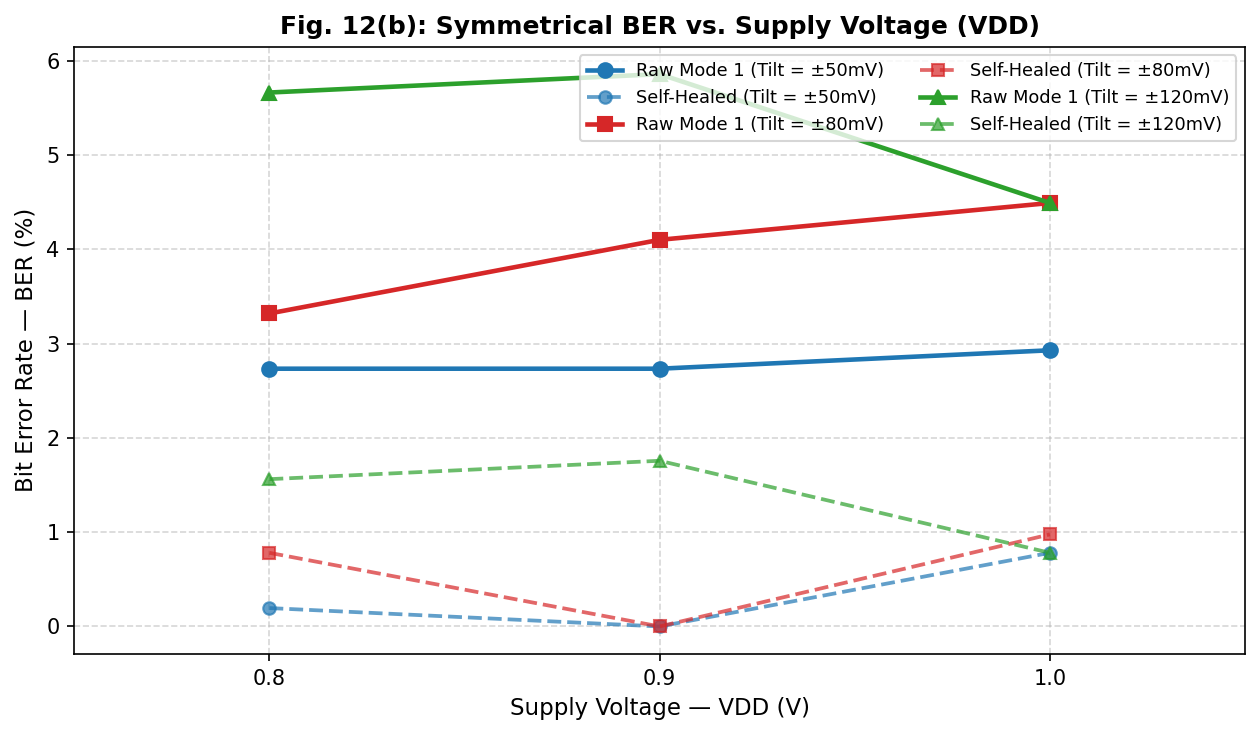

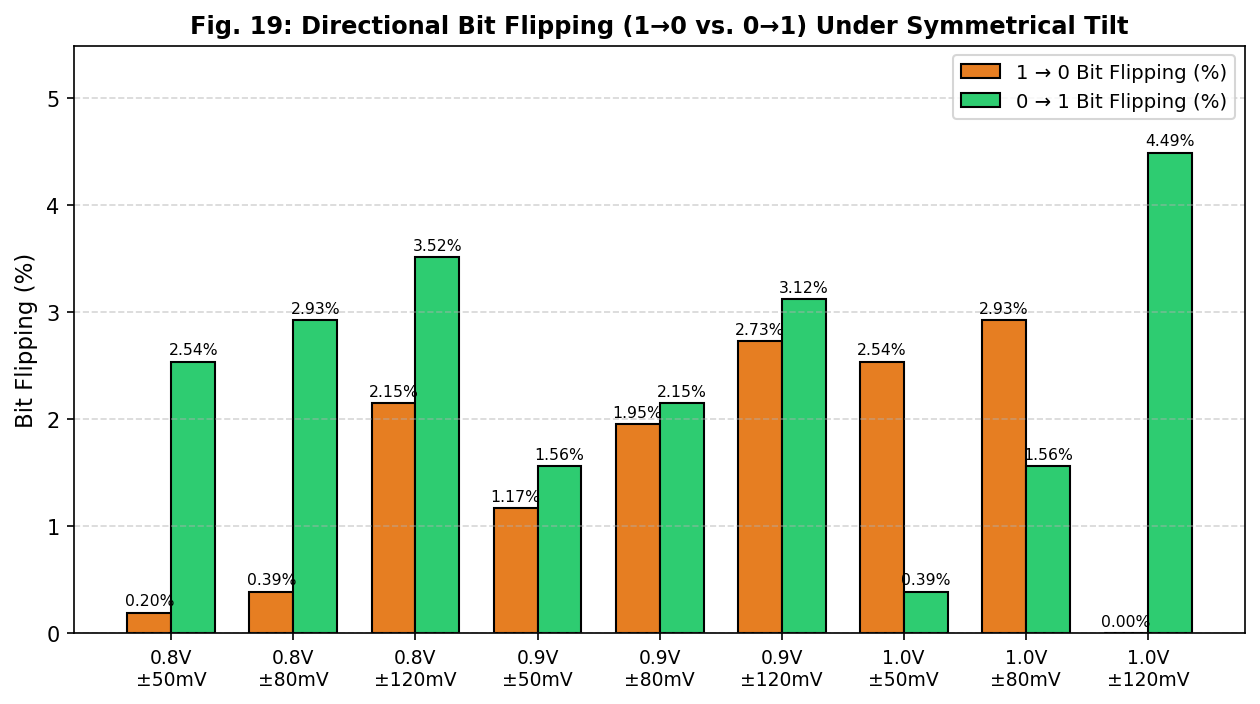

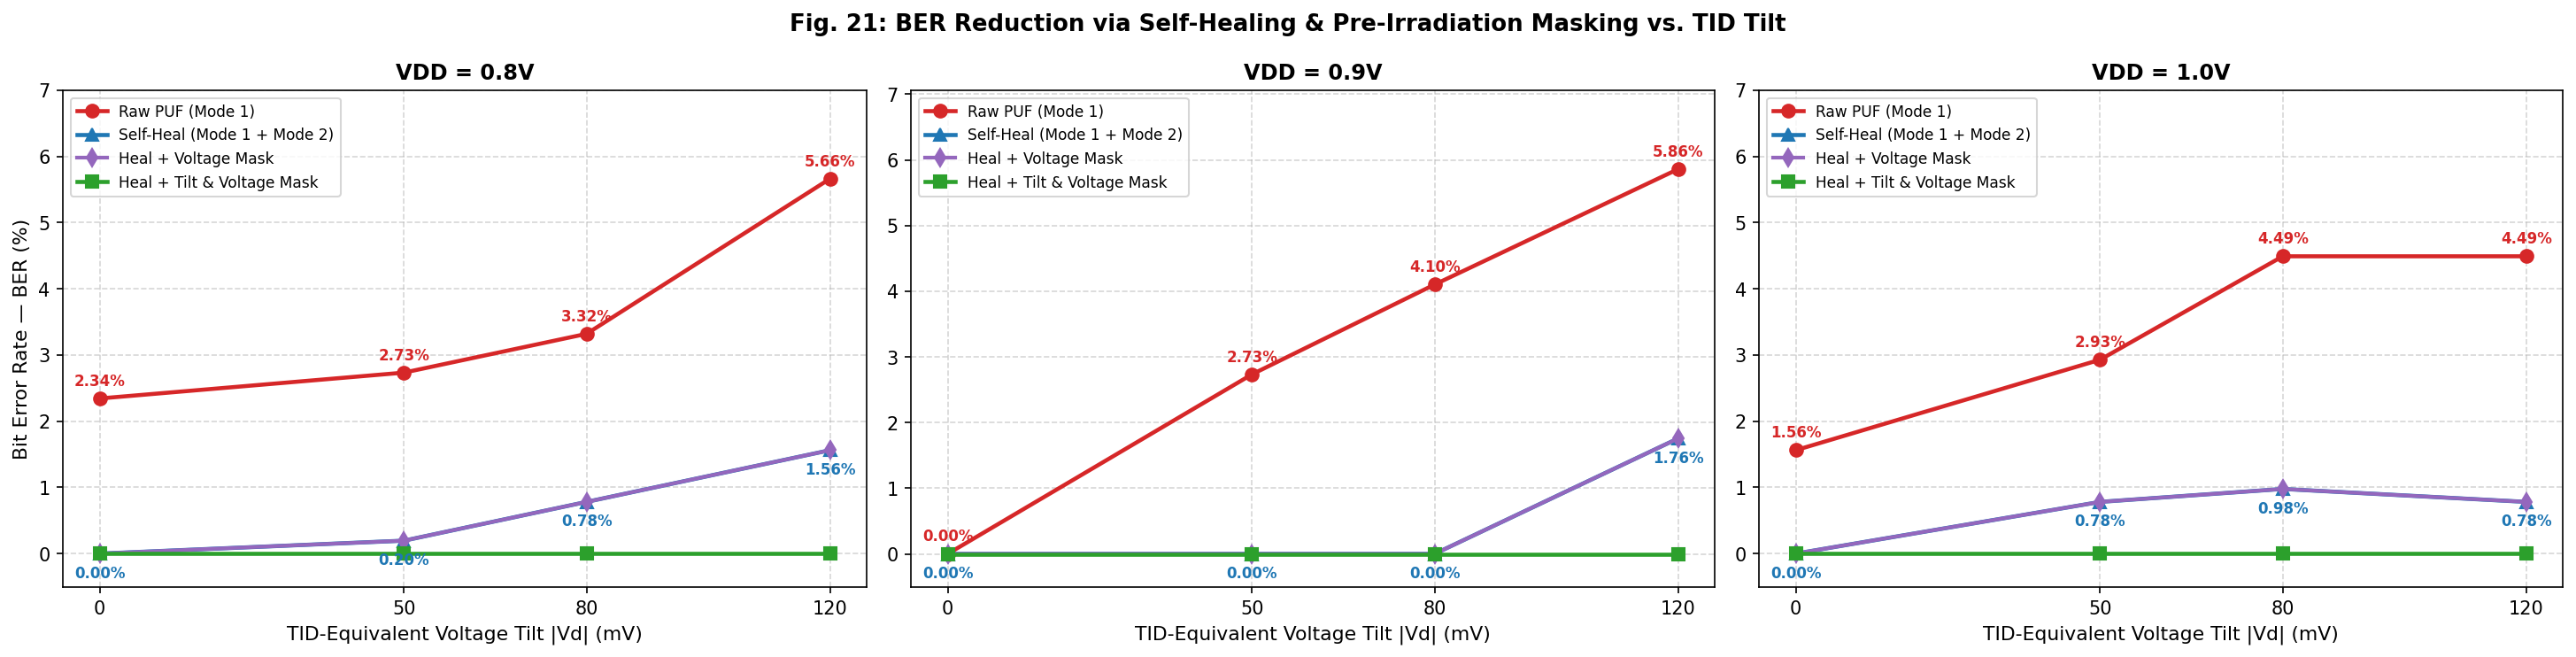

In [30]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


CSV_FILES = [
    # VDD = 0.8V
    "mc_256_0.8_vdd-120.csv",
    "mc_256_0.8_vdd-80.csv",
    "mc_256_0.8_vdd-50.csv",
    "mc_256_0.8_vdd.csv",
    "mc_256_0.8_vdd+50.csv",
    "mc_256_0.8_vdd+80.csv",
    "mc_256_0.8_vdd+120.csv",
    # VDD = 0.9V
    "mc_256_0.9_vdd-120.csv",
    "mc_256_0.9_vdd-80.csv",
    "mc_256_0.9_vdd-50.csv",
    "mc_256_0.9_vdd.csv",
    "mc_256_0.9_vdd+50.csv",
    "mc_256_0.9_vdd+80.csv",
    "mc_256_0.9_vdd+120.csv",
    # VDD = 1.0V
    "mc_256_1.0_vdd-120.csv",
    "mc_256_1.0_vdd-80.csv",
    "mc_256_1.0_vdd-50.csv",
    "mc_256_1.0_vdd.csv",
    "mc_256_1.0_vdd+50.csv",
    "mc_256_1.0_vdd+80.csv",
    "mc_256_1.0_vdd+120.csv",
]


def extract_cell_bits(csv_path, vdd):
    """Extracts 256-bit logic responses for Mode 1 (97-103ns) and Mode 2 (37-43ns)."""
    df = pd.read_csv(csv_path, low_memory=False)
    threshold = vdd / 2.0

    cols = df.columns
    paramset_ids = sorted(
        list(set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(cols))))
    )

    m2_t_min, m2_t_max = 37e-9, 43e-9
    m1_t_min, m1_t_max = 97e-9, 103e-9

    bits_m2 = np.zeros(len(paramset_ids), dtype=int)
    bits_m1 = np.zeros(len(paramset_ids), dtype=int)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(df[f"/BL (mcparamset={mc_id}) X"], errors="coerce").values
        v_bl = pd.to_numeric(df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce").values

        mask_m2 = (t_bl >= m2_t_min) & (t_bl <= m2_t_max)
        mask_m1 = (t_bl >= m1_t_min) & (t_bl <= m1_t_max)

        v_m2 = np.mean(v_bl[mask_m2]) if np.any(mask_m2) else np.nan
        v_m1 = np.mean(v_bl[mask_m1]) if np.any(mask_m1) else np.nan

        bits_m2[idx] = 1 if v_m2 >= threshold else 0
        bits_m1[idx] = 1 if v_m1 >= threshold else 0

    return paramset_ids, bits_m1, bits_m2


def bits_to_hex(bits):
    bit_str = "".join(str(b) for b in bits)
    hex_str = hex(int(bit_str, 2))[2:].upper().zfill(len(bits) // 4)
    return hex_str, bit_str


def get_symmetrical_responses(dataset, vdd, tilt_mag):
    """Returns [(M1, M2)] for tilt_mag=0, or [(M1_+Vd, M2_+Vd), (M1_-Vd, M2_-Vd)] for |Vd|>0."""
    if tilt_mag == 0:
        return [(dataset[(vdd, 0)]["M1"], dataset[(vdd, 0)]["M2"])] if (vdd, 0) in dataset else []
    pairs = []
    if (vdd, +tilt_mag) in dataset:
        pairs.append((dataset[(vdd, +tilt_mag)]["M1"], dataset[(vdd, +tilt_mag)]["M2"]))
    if (vdd, -tilt_mag) in dataset:
        pairs.append((dataset[(vdd, -tilt_mag)]["M1"], dataset[(vdd, -tilt_mag)]["M2"]))
    return pairs


def run_paper_analysis(csv_filenames=CSV_FILES, golden_vdd=0.9, heal_vd=80):
    dataset = {}
    pattern = re.compile(r"mc_256_([0-9.]+)_vdd([+-]\d+)?\.csv$")

    for fname in csv_filenames:
        if not os.path.isfile(fname):
            print(f"[SKIPPED - Not Uploaded] {fname}")
            continue
        m = pattern.match(fname)
        if not m:
            continue
        vdd = float(m.group(1))
        tilt = int(m.group(2)) if m.group(2) else 0
        ids, b_m1, b_m2 = extract_cell_bits(fname, vdd)
        dataset[(vdd, tilt)] = {"mc_ids": ids, "M1": b_m1, "M2": b_m2}
        print(f"[LOADED] {fname:26s} -> VDD={vdd:.1f}V, Tilt={tilt:+4d}mV")

    if (golden_vdd, 0) not in dataset:
        raise FileNotFoundError(f"Nominal baseline file 'mc_256_{golden_vdd}_vdd.csv' is required!")

    # 1. Extract and Print Golden Key (Nominal VDD = 0.9V, Tilt = 0mV)
    gk_m1 = dataset[(golden_vdd, 0)]["M1"]
    gk_m2 = dataset[(golden_vdd, 0)]["M2"]
    n_bits = len(gk_m1)

    hex_m1, bin_m1 = bits_to_hex(gk_m1)
    hex_m2, bin_m2 = bits_to_hex(gk_m2)

    print("\n" + "=" * 80)
    print(f"GOLDEN KEY (EXTRACTED AT NOMINAL VDD = {golden_vdd}V, Tilt = 0mV)")
    print("=" * 80)
    print(f"Mode 1 (97-103ns) HEX : {hex_m1}")
    print(f"Mode 1 (97-103ns) BIN : {bin_m1}")
    print("-" * 80)
    print(f"Mode 2 (37-43ns)  HEX : {hex_m2}")
    print(f"Mode 2 (37-43ns)  BIN : {bin_m2}")
    print("=" * 80 + "\n")

    pd.DataFrame({
        "mc_id": dataset[(golden_vdd, 0)]["mc_ids"],
        "Golden_Key_M1": gk_m1,
        "Golden_Key_M2": gk_m2,
    }).to_csv("golden_key_256bit.csv", index=False)

    # 2. Voltage-Tilt Preselection & Self-Healing (Paper Section III-B, Vd = 80mV)
    presel_vdd = None
    for cand in [golden_vdd, 0.8, 1.0]:
        if (cand, +heal_vd) in dataset and (cand, -heal_vd) in dataset:
            presel_vdd = cand
            break

    if presel_vdd is not None:
        m1_stable = dataset[(presel_vdd, +heal_vd)]["M1"] == dataset[(presel_vdd, -heal_vd)]["M1"]
        m2_stable = dataset[(presel_vdd, +heal_vd)]["M2"] == dataset[(presel_vdd, -heal_vd)]["M2"]
    else:
        m1_stable = np.ones(n_bits, dtype=bool)
        m2_stable = np.ones(n_bits, dtype=bool)

    repaired_mask = (~m1_stable) & m2_stable
    discarded_mask = (~m1_stable) & (~m2_stable)
    gk_healed = np.where(repaired_mask, gk_m2, gk_m1)

    # Pre-Irradiation Voltage Mask (cells stable across VDD corners 0.8V, 0.9V, 1.0V)
    volt_valid_mask = ~discarded_mask
    for v_corner in [0.8, 0.9, 1.0]:
        if (v_corner, 0) in dataset:
            healed_corner = np.where(
                repaired_mask, dataset[(v_corner, 0)]["M2"], dataset[(v_corner, 0)]["M1"]
            )
            volt_valid_mask &= (healed_corner == gk_healed)

    # Pre-Irradiation Tilt & Voltage Mask (also discards cells flipping at +/-120mV)
    full_valid_mask = volt_valid_mask.copy()
    for v_corner in [0.8, 0.9, 1.0]:
        for t_mag in [80, 120]:
            if (v_corner, +t_mag) in dataset and (v_corner, -t_mag) in dataset:
                h_pos = np.where(
                    repaired_mask, dataset[(v_corner, +t_mag)]["M2"], dataset[(v_corner, +t_mag)]["M1"]
                )
                h_neg = np.where(
                    repaired_mask, dataset[(v_corner, -t_mag)]["M2"], dataset[(v_corner, -t_mag)]["M1"]
                )
                full_valid_mask &= (h_pos == h_neg) & (h_pos == gk_healed)

    print(f"Self-Healing Preselection (Vd = +/-{heal_vd}mV at VDD = {presel_vdd}V):")
    print(f"  - Mode 1 Native Stable Bits : {m1_stable.sum():3d} / {n_bits} ({m1_stable.mean()*100:.2f}%)")
    print(f"  - Repaired via Mode 2       : {repaired_mask.sum():3d} / {n_bits} ({repaired_mask.mean()*100:.2f}%)")
    print(f"  - Discarded (Unstable Both) : {discarded_mask.sum():3d} / {n_bits} ({discarded_mask.mean()*100:.2f}%)\n")

    # 3. Compute Symmetrical Metrics Across VDDs and TID-Equivalent Tilts (0, 50, 80, 120 mV)
    vdds_ordered = [0.8, 0.9, 1.0]
    tilt_mags = [0, 50, 80, 120]
    records = []

    for vdd in vdds_ordered:
        for mag in tilt_mags:
            pairs = get_symmetrical_responses(dataset, vdd, mag)
            if not pairs:
                continue

            raw_m1_bers = [np.mean(m1 != gk_m1) * 100.0 for m1, _ in pairs]
            raw_m2_bers = [np.mean(m2 != gk_m2) * 100.0 for _, m2 in pairs]
            heal_bers = [
                np.mean(np.where(repaired_mask, m2, m1) != gk_healed) * 100.0
                for m1, m2 in pairs
            ]
            heal_vmask_bers = [
                np.mean(np.where(repaired_mask, m2, m1)[volt_valid_mask] != gk_healed[volt_valid_mask]) * 100.0
                for m1, m2 in pairs
            ]
            heal_fullmask_bers = [
                np.mean(np.where(repaired_mask, m2, m1)[full_valid_mask] != gk_healed[full_valid_mask]) * 100.0
                for m1, m2 in pairs
            ]

            if len(pairs) == 2:
                unst_m1 = np.mean(pairs[0][0] != pairs[1][0]) * 100.0
                unst_m2 = np.mean(pairs[0][1] != pairs[1][1]) * 100.0
                unst_heal = np.mean(
                    np.where(repaired_mask, pairs[0][1], pairs[0][0])
                    != np.where(repaired_mask, pairs[1][1], pairs[1][0])
                ) * 100.0
            else:
                unst_m1 = float(np.mean(raw_m1_bers))
                unst_m2 = float(np.mean(raw_m2_bers))
                unst_heal = float(np.mean(heal_bers))

            flip_1_to_0 = np.mean([np.mean((gk_m1 == 1) & (m1 == 0)) * 100.0 for m1, _ in pairs])
            flip_0_to_1 = np.mean([np.mean((gk_m1 == 0) & (m1 == 1)) * 100.0 for m1, _ in pairs])

            records.append({
                "VDD_V": vdd,
                "TID_Tilt_mV": mag,
                "Skew_Dirs": len(pairs),
                "Raw_M1_BER_pct": round(float(np.mean(raw_m1_bers)), 4),
                "Raw_M2_BER_pct": round(float(np.mean(raw_m2_bers)), 4),
                "SelfHeal_BER_pct": round(float(np.mean(heal_bers)), 4),
                "Heal_VoltMask_BER_pct": round(float(np.mean(heal_vmask_bers)), 4),
                "Heal_TiltVoltMask_BER_pct": round(float(np.mean(heal_fullmask_bers)), 4),
                "Unstable_M1_pct": round(float(unst_m1), 4),
                "Unstable_M2_pct": round(float(unst_m2), 4),
                "Unstable_Heal_pct": round(float(unst_heal), 4),
                "Flip_1to0_pct": round(float(flip_1_to_0), 4),
                "Flip_0to1_pct": round(float(flip_0_to_1), 4),
            })

    summary_df = pd.DataFrame(records)
    summary_df.to_csv("paper_symmetrical_tid_ber_summary.csv", index=False)
    print(summary_df.to_string(index=False))

    # =========================================================================
    # PLOT 1 (Paper Fig. 10): 16x16 Spatial Map of Raw vs Self-Healing Array
    # =========================================================================
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3), dpi=150)
    cmap = ListedColormap(["#7f7f7f", "#ffeb3b", "#2ecc71", "#e67e22"])

    map_raw = np.where(m1_stable, 0, 1).reshape(16, 16)
    map_presel = np.zeros(n_bits, dtype=int)
    map_presel[repaired_mask] = 2
    map_presel[discarded_mask] = 3
    map_presel = map_presel.reshape(16, 16)
    map_final = np.where(discarded_mask, 1, 0).reshape(16, 16)

    titles_10 = [
        "(a) Raw Mode 1 Responses",
        "(b) Preselection & Healing Classification",
        "(c) After Self-Healing Mechanism",
    ]
    for ax, grid, title in zip(axes, [map_raw, map_presel, map_final], titles_10):
        ax.imshow(grid, cmap=cmap, vmin=0, vmax=3)
        ax.set_title(title, fontsize=10.5, fontweight="bold")
        ax.set_xticks([0, 4, 8, 12, 15])
        ax.set_yticks([0, 4, 8, 12, 15])

    legend_items = [
        Patch(facecolor="#7f7f7f", label="Stable Bits"),
        Patch(facecolor="#ffeb3b", label="Unstable Bits"),
        Patch(facecolor="#2ecc71", label="Repaired Bits (Mode 2)"),
        Patch(facecolor="#e67e22", label="Discarded Bits"),
    ]
    fig.legend(handles=legend_items, loc="center right", bbox_to_anchor=(1.13, 0.5), fontsize=9)
    fig.suptitle(
        f"Fig. 10: 256-Cell (16×16) Spatial Stability & Self-Healing Map (Vd = ±{heal_vd}mV)",
        fontsize=12, fontweight="bold"
    )
    fig.tight_layout()
    fig.savefig("Paper_Fig10_Spatial_SelfHealing_Map.png", bbox_inches="tight")
    plt.show()

    # =========================================================================
    # PLOT 2 (Paper Fig. 16): Symmetrical BER & Unstable Bits vs TID Tilt (mV)
    # =========================================================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=150)
    vdd_styles = {
        0.8: ("o-", "#d62728", "VDD = 0.8V"),
        0.9: ("s-", "#1f77b4", "VDD = 0.9V (Nominal)"),
        1.0: ("^-", "#2ca02c", "VDD = 1.0V"),
    }

    for vdd, (style, col, lbl) in vdd_styles.items():
        sub = summary_df[summary_df["VDD_V"] == vdd].sort_values("TID_Tilt_mV")
        if sub.empty:
            continue
        ax1.plot(sub["TID_Tilt_mV"], sub["Raw_M1_BER_pct"], style, color=col, linewidth=2.2, markersize=7, label=f"{lbl} (Raw Mode 1)")
        ax1.plot(sub["TID_Tilt_mV"], sub["SelfHeal_BER_pct"], "--", marker=style[0], color=col, alpha=0.65, linewidth=1.8, markersize=6, label=f"{lbl} (Self-Healed)")

        ax2.plot(sub["TID_Tilt_mV"], sub["Unstable_M1_pct"], style, color=col, linewidth=2.2, markersize=7, label=f"{lbl} (Raw Mode 1)")
        ax2.plot(sub["TID_Tilt_mV"], sub["Unstable_Heal_pct"], "--", marker=style[0], color=col, alpha=0.65, linewidth=1.8, markersize=6, label=f"{lbl} (Self-Healed)")

    ax1.set_title("(a) Symmetrical BER vs. TID-Equivalent Tilt", fontsize=11.5, fontweight="bold")
    ax1.set_xlabel("TID-Equivalent Voltage Tilt |Vd| (mV)", fontsize=10.5)
    ax1.set_ylabel("Bit Error Rate — BER (%)", fontsize=10.5)
    ax1.set_xticks(tilt_mags)
    ax1.grid(True, linestyle="--", alpha=0.5)
    ax1.legend(fontsize=8)

    ax2.set_title("(b) Unstable Bits (%) vs. TID-Equivalent Tilt", fontsize=11.5, fontweight="bold")
    ax2.set_xlabel("TID-Equivalent Voltage Tilt |Vd| (mV)", fontsize=10.5)
    ax2.set_ylabel("Unstable Bits (%)", fontsize=10.5)
    ax2.set_xticks(tilt_mags)
    ax2.grid(True, linestyle="--", alpha=0.5)
    ax2.legend(fontsize=8)

    fig.suptitle("Fig. 16: Symmetrical BER & Unstable Bits vs. TID Radiation Stress (Voltage Tilt)", fontsize=12.5, fontweight="bold")
    fig.tight_layout()
    fig.savefig("Paper_Fig16_BER_and_UnstableBits_vs_Tilt.png")
    plt.show()

    # =========================================================================
    # PLOT 3 (Paper Fig. 12b): Symmetrical BER vs Supply Voltage (VDD)
    # =========================================================================
    fig, ax = plt.subplots(figsize=(8.5, 5.0), dpi=150)
    tilt_styles = {
        50: ("o-", "#1f77b4", "Tilt = ±50mV"),
        80: ("s-", "#d62728", "Tilt = ±80mV"),
        120: ("^-", "#2ca02c", "Tilt = ±120mV"),
    }
    for mag, (style, col, lbl) in tilt_styles.items():
        sub = summary_df[summary_df["TID_Tilt_mV"] == mag].sort_values("VDD_V")
        if sub.empty:
            continue
        ax.plot(sub["VDD_V"], sub["Raw_M1_BER_pct"], style, color=col, linewidth=2.2, markersize=7, label=f"Raw Mode 1 ({lbl})")
        ax.plot(sub["VDD_V"], sub["SelfHeal_BER_pct"], "--", marker=style[0], color=col, alpha=0.7, linewidth=1.8, markersize=6, label=f"Self-Healed ({lbl})")

    ax.set_title("Fig. 12(b): Symmetrical BER vs. Supply Voltage (VDD)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Supply Voltage — VDD (V)", fontsize=11)
    ax.set_ylabel("Bit Error Rate — BER (%)", fontsize=11)
    ax.set_xticks(vdds_ordered)
    ax.set_xlim(0.75, 1.05)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=8.5, ncol=2)
    fig.tight_layout()
    fig.savefig("Paper_Fig12b_BER_vs_VDD_Symmetrical.png")
    plt.show()

    # =========================================================================
    # PLOT 4 (Paper Fig. 19): Bit Flipping Direction (1->0 vs 0->1) vs Tilt
    # =========================================================================
    fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=150)
    sub_flip = summary_df[summary_df["TID_Tilt_mV"] > 0].copy()
    sub_flip["Label"] = sub_flip.apply(lambda r: f"{r['VDD_V']:.1f}V\n±{int(r['TID_Tilt_mV'])}mV", axis=1)
    x = np.arange(len(sub_flip))
    width = 0.36

    rects1 = ax.bar(x - width / 2, sub_flip["Flip_1to0_pct"], width, label="1 → 0 Bit Flipping (%)", color="#e67e22", edgecolor="black")
    rects2 = ax.bar(x + width / 2, sub_flip["Flip_0to1_pct"], width, label="0 → 1 Bit Flipping (%)", color="#2ecc71", edgecolor="black")

    ax.bar_label(rects1, fmt="%.2f%%", padding=2, fontsize=7.5)
    ax.bar_label(rects2, fmt="%.2f%%", padding=2, fontsize=7.5)

    ax.set_title("Fig. 19: Directional Bit Flipping (1→0 vs. 0→1) Under Symmetrical Tilt", fontsize=11.5, fontweight="bold")
    ax.set_ylabel("Bit Flipping (%)", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(sub_flip["Label"], fontsize=9)
    ax.set_ylim(0, max(5.0, sub_flip[["Flip_1to0_pct", "Flip_0to1_pct"]].values.max() + 1.0))
    ax.grid(True, axis="y", linestyle="--", alpha=0.5)
    ax.legend(fontsize=9.5)
    fig.tight_layout()
    fig.savefig("Paper_Fig19_BitFlipping_Direction.png")
    plt.show()

    # =========================================================================
    # PLOT 5 (Paper Fig. 21): Raw vs Self-Heal vs Pre-Irradiation Masking
    # =========================================================================
    available_vdds = [v for v in vdds_ordered if not summary_df[summary_df["VDD_V"] == v].empty]
    fig, axes = plt.subplots(1, len(available_vdds), figsize=(6.5 * len(available_vdds), 5.0), dpi=150, squeeze=False)

    for idx, vdd in enumerate(available_vdds):
        ax = axes[0, idx]
        sub = summary_df[summary_df["VDD_V"] == vdd].sort_values("TID_Tilt_mV")
        tilts = sub["TID_Tilt_mV"].values

        ax.plot(tilts, sub["Raw_M1_BER_pct"], "o-", color="#d62728", linewidth=2.2, markersize=7, label="Raw PUF (Mode 1)")
        ax.plot(tilts, sub["SelfHeal_BER_pct"], "^-", color="#1f77b4", linewidth=2.2, markersize=7, label="Self-Heal (Mode 1 + Mode 2)")
        ax.plot(tilts, sub["Heal_VoltMask_BER_pct"], "d-", color="#9467bd", linewidth=2.0, markersize=7, label="Heal + Voltage Mask")
        ax.plot(tilts, sub["Heal_TiltVoltMask_BER_pct"], "s-", color="#2ca02c", linewidth=2.2, markersize=7, label="Heal + Tilt & Voltage Mask")

        for x_val, y_raw, y_heal in zip(tilts, sub["Raw_M1_BER_pct"], sub["SelfHeal_BER_pct"]):
            ax.annotate(f"{y_raw:.2f}%", (x_val, y_raw), textcoords="offset points", xytext=(0, 7),
                        ha="center", fontsize=8, color="#d62728", fontweight="bold")
            ax.annotate(f"{y_heal:.2f}%", (x_val, y_heal), textcoords="offset points", xytext=(0, -13),
                        ha="center", fontsize=8, color="#1f77b4", fontweight="bold")

        ax.set_title(f"VDD = {vdd:.1f}V", fontsize=11.5, fontweight="bold")
        ax.set_xlabel("TID-Equivalent Voltage Tilt |Vd| (mV)", fontsize=10.5)
        if idx == 0:
            ax.set_ylabel("Bit Error Rate — BER (%)", fontsize=10.5)
        ax.set_xticks(tilt_mags)
        ax.set_ylim(-0.5, max(7.0, sub["Raw_M1_BER_pct"].max() + 1.2))
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend(loc="upper left", fontsize=8.2, frameon=True)

    fig.suptitle("Fig. 21: BER Reduction via Self-Healing & Pre-Irradiation Masking vs. TID Tilt", fontsize=12.5, fontweight="bold")
    fig.tight_layout()
    fig.savefig("Paper_Fig21_SelfHealing_and_Masking_BER.png")
    plt.show()


if __name__ == "__main__":
    run_paper_analysis()

[LOADED] mc_256_0.8_vdd+120.csv     -> N=256, VDD=0.80V, Tilt=+120mV
[LOADED] mc_256_0.8_vdd+50.csv      -> N=256, VDD=0.80V, Tilt= +50mV
[LOADED] mc_256_0.8_vdd+80.csv      -> N=256, VDD=0.80V, Tilt= +80mV
[LOADED] mc_256_0.8_vdd-120.csv     -> N=256, VDD=0.80V, Tilt=-120mV
[LOADED] mc_256_0.8_vdd-50.csv      -> N=256, VDD=0.80V, Tilt= -50mV
[LOADED] mc_256_0.8_vdd-80.csv      -> N=256, VDD=0.80V, Tilt= -80mV
[LOADED] mc_256_0.8_vdd.csv         -> N=256, VDD=0.80V, Tilt=  +0mV
[LOADED] mc_256_0.9_vdd+120.csv     -> N=256, VDD=0.90V, Tilt=+120mV
[LOADED] mc_256_0.9_vdd+50.csv      -> N=256, VDD=0.90V, Tilt= +50mV
[LOADED] mc_256_0.9_vdd+80.csv      -> N=256, VDD=0.90V, Tilt= +80mV
[LOADED] mc_256_0.9_vdd-120.csv     -> N=256, VDD=0.90V, Tilt=-120mV
[LOADED] mc_256_0.9_vdd-50.csv      -> N=256, VDD=0.90V, Tilt= -50mV
[LOADED] mc_256_0.9_vdd-80.csv      -> N=256, VDD=0.90V, Tilt= -80mV
[LOADED] mc_256_0.9_vdd.csv         -> N=256, VDD=0.90V, Tilt=  +0mV
[LOADED] mc_256_1.0_vdd+120.csv   

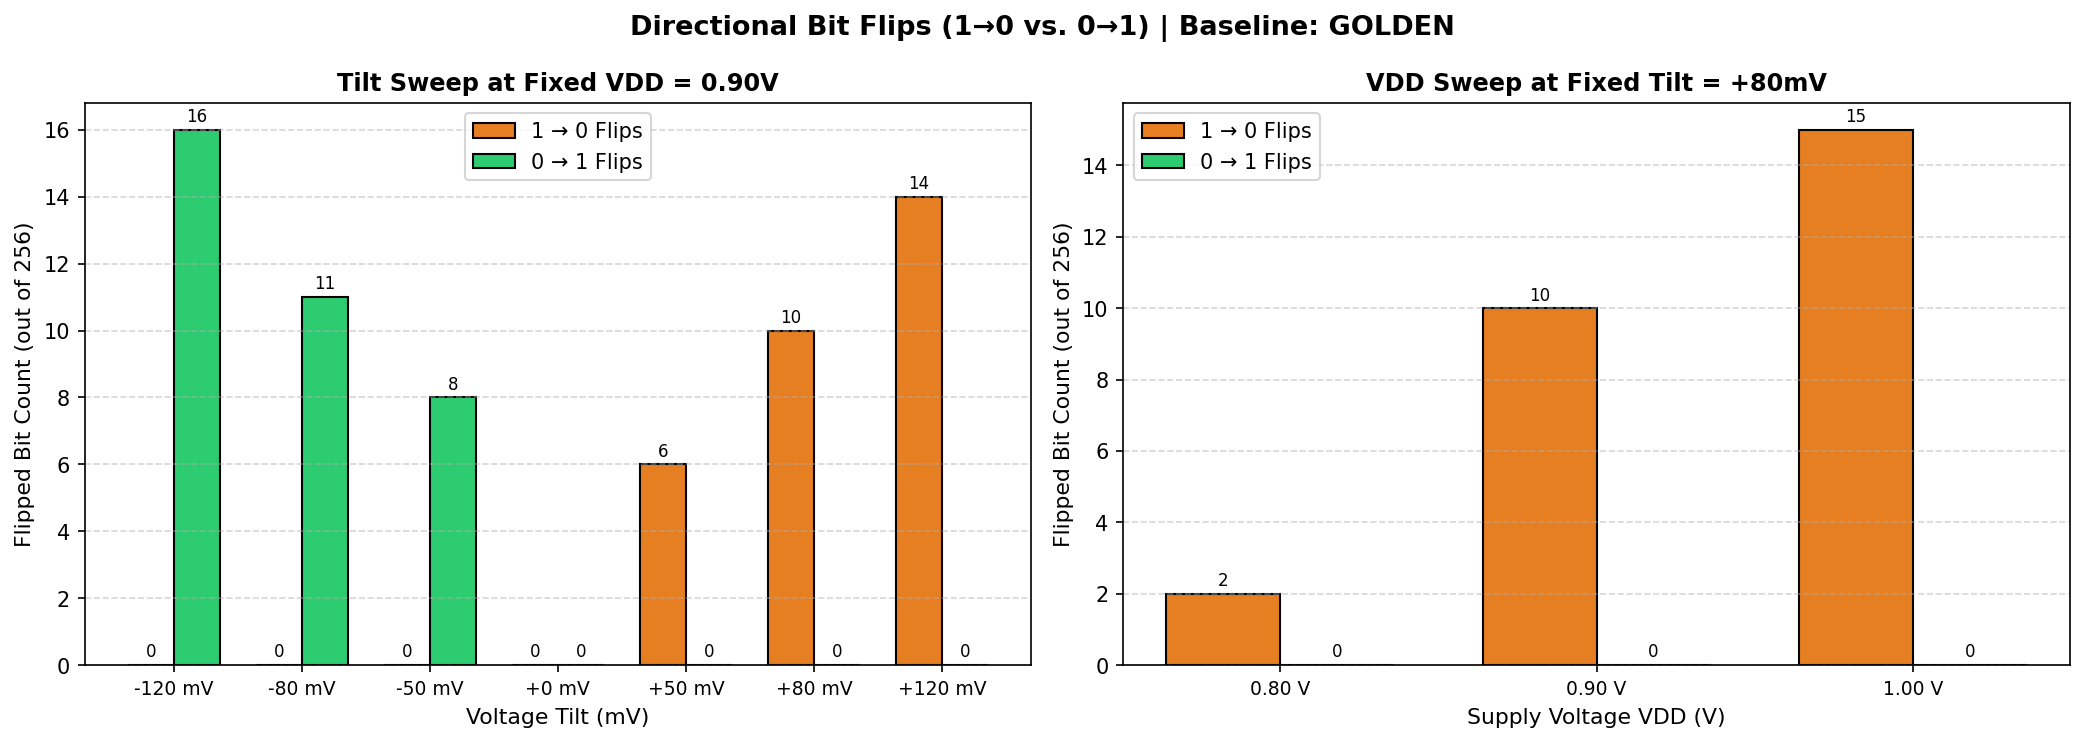

In [31]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. CONFIGURATION
# ==============================================================================
DATA_DIR = "."              # Folder containing your mc_*.csv files
ARRAY_SIZE = 256            # Set to 256 or 2048 (or None to auto-select largest group)
GOLDEN_VDD = 0.9            # Nominal reference VDD (V) at Tilt = 0 mV

# Choose specific operating points for the two requested sweeps:
SWEEP_VDD = 0.9             # Fixed VDD (V) -> sweep across all available tilts
SWEEP_TILT = 80             # Fixed Tilt (mV, e.g., -120, -80, 0, +80, +120) -> sweep across VDDs

# Reference baseline for counting flips:
#   "golden" -> compare every (VDD, Tilt) against Golden Key at (GOLDEN_VDD, 0mV)
#   "local"  -> compare each (VDD, Tilt) against that same VDD's own 0mV nominal file
BASELINE_MODE = "golden"

# Sense windows (seconds)
MODE2_WINDOW = (37e-9, 43e-9)   # 37 ns - 43 ns
MODE1_WINDOW = (97e-9, 103e-9)  # 97 ns - 103 ns


# ==============================================================================
# 2. WAVEFORM EXTRACTION HELPER
# ==============================================================================
def extract_bits_from_csv(csv_path, vdd):
    """Extracts Mode 1 and Mode 2 binary responses from a Cadence Monte Carlo CSV."""
    df = pd.read_csv(
        csv_path,
        usecols=lambda c: "/BL (" in c or c.strip().startswith("/BL "),
        low_memory=False,
    )
    threshold = vdd / 2.0
    paramset_ids = sorted(
        set(int(x) for x in re.findall(r"mcparamset=(\d+)", " ".join(df.columns)))
    )

    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(df[f"/BL (mcparamset={mc_id}) X"], errors="coerce").values
        v_bl = pd.to_numeric(df[f"/BL (mcparamset={mc_id}) Y"], errors="coerce").values

        mask_m1 = (t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])
        mask_m2 = (t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])

        v1 = np.nanmean(v_bl[mask_m1]) if np.any(mask_m1) else np.nan
        v2 = np.nanmean(v_bl[mask_m2]) if np.any(mask_m2) else np.nan

        m1_bits[idx] = 1 if v1 >= threshold else 0
        m2_bits[idx] = 1 if v2 >= threshold else 0

    return m1_bits, m2_bits


# ==============================================================================
# 3. LOAD ALL MATCHING CSV FILES
# ==============================================================================
def load_all_datasets(data_dir=".", array_size=256):
    pattern = re.compile(r"mc_(\d+)_+([0-9.]+)_vdd([+-]\d+)?\.csv$", re.IGNORECASE)
    files = sorted(glob.glob(os.path.join(data_dir, "mc_*.csv")))

    parsed = []
    for fpath in files:
        fname = os.path.basename(fpath)
        m = pattern.match(fname)
        if not m:
            continue
        n_cells = int(m.group(1))
        vdd = float(m.group(2))
        tilt = int(m.group(3)) if m.group(3) else 0
        parsed.append((n_cells, vdd, tilt, fpath, fname))

    if not parsed:
        raise FileNotFoundError(f"No matching 'mc_*.csv' files found in '{data_dir}'.")

    if array_size is None:
        # Pick the cell count with the largest number of CSVs
        counts = pd.Series([p[0] for p in parsed]).value_counts()
        array_size = int(counts.index[0])

    dataset = {}
    for n_cells, vdd, tilt, fpath, fname in parsed:
        if n_cells != array_size:
            continue
        m1, m2 = extract_bits_from_csv(fpath, vdd)
        dataset[(vdd, tilt)] = {"M1": m1, "M2": m2, "file": fname}
        print(f"[LOADED] {fname:26s} -> N={len(m1)}, VDD={vdd:.2f}V, Tilt={tilt:+4d}mV")

    return dataset, array_size


# ==============================================================================
# 4. DIRECTIONAL BIT-FLIP ANALYSIS (1->0 AND 0->1 SEPARATELY)
# ==============================================================================
def compute_flip_stats(ref_bits, test_bits):
    """Returns separate 1->0 and 0->1 flip counts and percentages."""
    n_total = len(ref_bits)
    n_ones = int(np.sum(ref_bits == 1))
    n_zeros = int(np.sum(ref_bits == 0))

    flips_1to0 = int(np.sum((ref_bits == 1) & (test_bits == 0)))
    flips_0to1 = int(np.sum((ref_bits == 0) & (test_bits == 1)))
    total_flips = flips_1to0 + flips_0to1

    return {
        "N": n_total,
        "Ref_1s": n_ones,
        "Ref_0s": n_zeros,
        "M1_1to0_Count": flips_1to0,
        "M1_1to0_Pct_Total": round(flips_1to0 / n_total * 100.0, 4),
        "M1_1to0_Pct_Of_1s": round((flips_1to0 / n_ones * 100.0) if n_ones else 0.0, 4),
        "M1_0to1_Count": flips_0to1,
        "M1_0to1_Pct_Total": round(flips_0to1 / n_total * 100.0, 4),
        "M1_0to1_Pct_Of_0s": round((flips_0to1 / n_zeros * 100.0) if n_zeros else 0.0, 4),
        "Total_Flips": total_flips,
        "Total_BER_Pct": round(total_flips / n_total * 100.0, 4),
    }


def analyze_all_and_sweep(
    data_dir=DATA_DIR,
    array_size=ARRAY_SIZE,
    golden_vdd=GOLDEN_VDD,
    sweep_vdd=SWEEP_VDD,
    sweep_tilt=SWEEP_TILT,
    baseline_mode=BASELINE_MODE,
):
    dataset, array_size = load_all_datasets(data_dir, array_size)

    if baseline_mode == "golden" and (golden_vdd, 0) not in dataset:
        raise KeyError(f"Golden baseline (VDD={golden_vdd}V, Tilt=0mV) not found in loaded CSVs.")

    # Compute 1->0 and 0->1 flips for every single loaded (VDD, Tilt) CSV
    rows = []
    for (vdd, tilt) in sorted(dataset.keys(), key=lambda x: (x[0], x[1])):
        ref_key = (golden_vdd, 0) if baseline_mode == "golden" else (vdd, 0)
        if ref_key not in dataset:
            print(f"[WARNING] Missing local 0mV baseline for VDD={vdd}V; skipping {dataset[(vdd, tilt)]['file']}")
            continue

        m1_stats = compute_flip_stats(dataset[ref_key]["M1"], dataset[(vdd, tilt)]["M1"])

        # Also track Mode 2 separate flips
        m2_ref, m2_cur = dataset[ref_key]["M2"], dataset[(vdd, tilt)]["M2"]
        m2_1to0 = int(np.sum((m2_ref == 1) & (m2_cur == 0)))
        m2_0to1 = int(np.sum((m2_ref == 0) & (m2_cur == 1)))

        rows.append({
            "VDD_V": vdd,
            "Tilt_mV": tilt,
            "File": dataset[(vdd, tilt)]["file"],
            **m1_stats,
            "M2_1to0_Count": m2_1to0,
            "M2_0to1_Count": m2_0to1,
            "M2_BER_Pct": round((m2_1to0 + m2_0to1) / len(m2_ref) * 100.0, 4),
        })

    df_all = pd.DataFrame(rows)
    df_all.to_csv("bit_flips_1to0_0to1_all_cases.csv", index=False)

    print("\n" + "=" * 105)
    print(f"ALL CASES: SEPARATE 1->0 AND 0->1 BIT FLIPS (Baseline: {baseline_mode.upper()})")
    print("=" * 105)
    cols_display = [
        "VDD_V", "Tilt_mV",
        "M1_1to0_Count", "M1_1to0_Pct_Total",
        "M1_0to1_Count", "M1_0to1_Pct_Total",
        "Total_Flips", "Total_BER_Pct",
        "M2_1to0_Count", "M2_0to1_Count",
    ]
    print(df_all[cols_display].to_string(index=False))

    # --------------------------------------------------------------------------
    # SWEEP 1: Fixed VDD -> Sweep Across Different Tilts
    # --------------------------------------------------------------------------
    df_tilt_sweep = df_all[np.isclose(df_all["VDD_V"], sweep_vdd)].sort_values("Tilt_mV")
    print("\n" + "=" * 105)
    print(f"SWEEP 1: FIXED VDD = {sweep_vdd:.2f}V | SWEEPING ACROSS TILTS (mV)")
    print("=" * 105)
    if df_tilt_sweep.empty:
        print(f"No CSVs found for VDD = {sweep_vdd}V. Available VDDs: {sorted(df_all['VDD_V'].unique())}")
    else:
        print(df_tilt_sweep[cols_display].to_string(index=False))

    # --------------------------------------------------------------------------
    # SWEEP 2: Fixed Tilt -> Sweep Across Different VDDs
    # --------------------------------------------------------------------------
    df_vdd_sweep = df_all[df_all["Tilt_mV"] == sweep_tilt].sort_values("VDD_V")
    print("\n" + "=" * 105)
    print(f"SWEEP 2: FIXED TILT = {sweep_tilt:+d}mV | SWEEPING ACROSS VDDs (V)")
    print("=" * 105)
    if df_vdd_sweep.empty:
        print(f"No CSVs found for Tilt = {sweep_tilt}mV. Available Tilts: {sorted(df_all['Tilt_mV'].unique())}")
    else:
        print(df_vdd_sweep[cols_display].to_string(index=False))

    # --------------------------------------------------------------------------
    # PLOT BOTH SWEEPS SIDE-BY-SIDE
    # --------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
    width = 0.36

    # Left subplot: Fixed VDD, Sweep across Tilts
    if not df_tilt_sweep.empty:
        x1 = np.arange(len(df_tilt_sweep))
        b1 = axes[0].bar(x1 - width / 2, df_tilt_sweep["M1_1to0_Count"], width, label="1 → 0 Flips", color="#e67e22", edgecolor="black")
        b2 = axes[0].bar(x1 + width / 2, df_tilt_sweep["M1_0to1_Count"], width, label="0 → 1 Flips", color="#2ecc71", edgecolor="black")
        axes[0].bar_label(b1, padding=2, fontsize=8)
        axes[0].bar_label(b2, padding=2, fontsize=8)
        axes[0].set_xticks(x1)
        axes[0].set_xticklabels([f"{int(t):+d} mV" for t in df_tilt_sweep["Tilt_mV"]], fontsize=9)
        axes[0].set_title(f"Tilt Sweep at Fixed VDD = {sweep_vdd:.2f}V", fontsize=11.5, fontweight="bold")
        axes[0].set_xlabel("Voltage Tilt (mV)", fontsize=10.5)
        axes[0].set_ylabel(f"Flipped Bit Count (out of {array_size})", fontsize=10.5)
        axes[0].grid(True, axis="y", linestyle="--", alpha=0.5)
        axes[0].legend()

    # Right subplot: Fixed Tilt, Sweep across VDDs
    if not df_vdd_sweep.empty:
        x2 = np.arange(len(df_vdd_sweep))
        b3 = axes[1].bar(x2 - width / 2, df_vdd_sweep["M1_1to0_Count"], width, label="1 → 0 Flips", color="#e67e22", edgecolor="black")
        b4 = axes[1].bar(x2 + width / 2, df_vdd_sweep["M1_0to1_Count"], width, label="0 → 1 Flips", color="#2ecc71", edgecolor="black")
        axes[1].bar_label(b3, padding=2, fontsize=8)
        axes[1].bar_label(b4, padding=2, fontsize=8)
        axes[1].set_xticks(x2)
        axes[1].set_xticklabels([f"{v:.2f} V" for v in df_vdd_sweep["VDD_V"]], fontsize=9)
        axes[1].set_title(f"VDD Sweep at Fixed Tilt = {sweep_tilt:+d}mV", fontsize=11.5, fontweight="bold")
        axes[1].set_xlabel("Supply Voltage VDD (V)", fontsize=10.5)
        axes[1].set_ylabel(f"Flipped Bit Count (out of {array_size})", fontsize=10.5)
        axes[1].grid(True, axis="y", linestyle="--", alpha=0.5)
        axes[1].legend()

    plt.suptitle(f"Directional Bit Flips (1→0 vs. 0→1) | Baseline: {baseline_mode.upper()}", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig("directional_bit_flips_sweeps.png", dpi=150, bbox_inches="tight")
    plt.show()

    return df_all, df_tilt_sweep, df_vdd_sweep


if __name__ == "__main__":
    df_all, df_tilt_sweep, df_vdd_sweep = analyze_all_and_sweep()


Processing Temperature = -100°C ...
  16x16 (256-CELL) SRAM PUF BIT DISTRIBUTION @ -100°C (Tilts: +120mV, -120mV)
Mode 1 Stable Bits (Grey)         : 253 / 256 (98.83%)
Mode 1 Unstable Bits (Yellow)     :   3 / 256 (1.17% Unstable before preselection)
--------------------------------------------------------------------------
Repaired via Mode 2 (Green)       :   3 (100.00% of unstable bits healed)
Discarded Dark Bits (Orange)      :   0 (0.00% masked out)
--------------------------------------------------------------------------
Final Active Valid Golden Key Bits: 256 / 256 (100.00% Valid Bit Yield)
Golden Key Hamming Weight         : 142 / 256 (55.47% ones)
Saved spatial map -> 'puf_16x16_mapping_-100C.png'


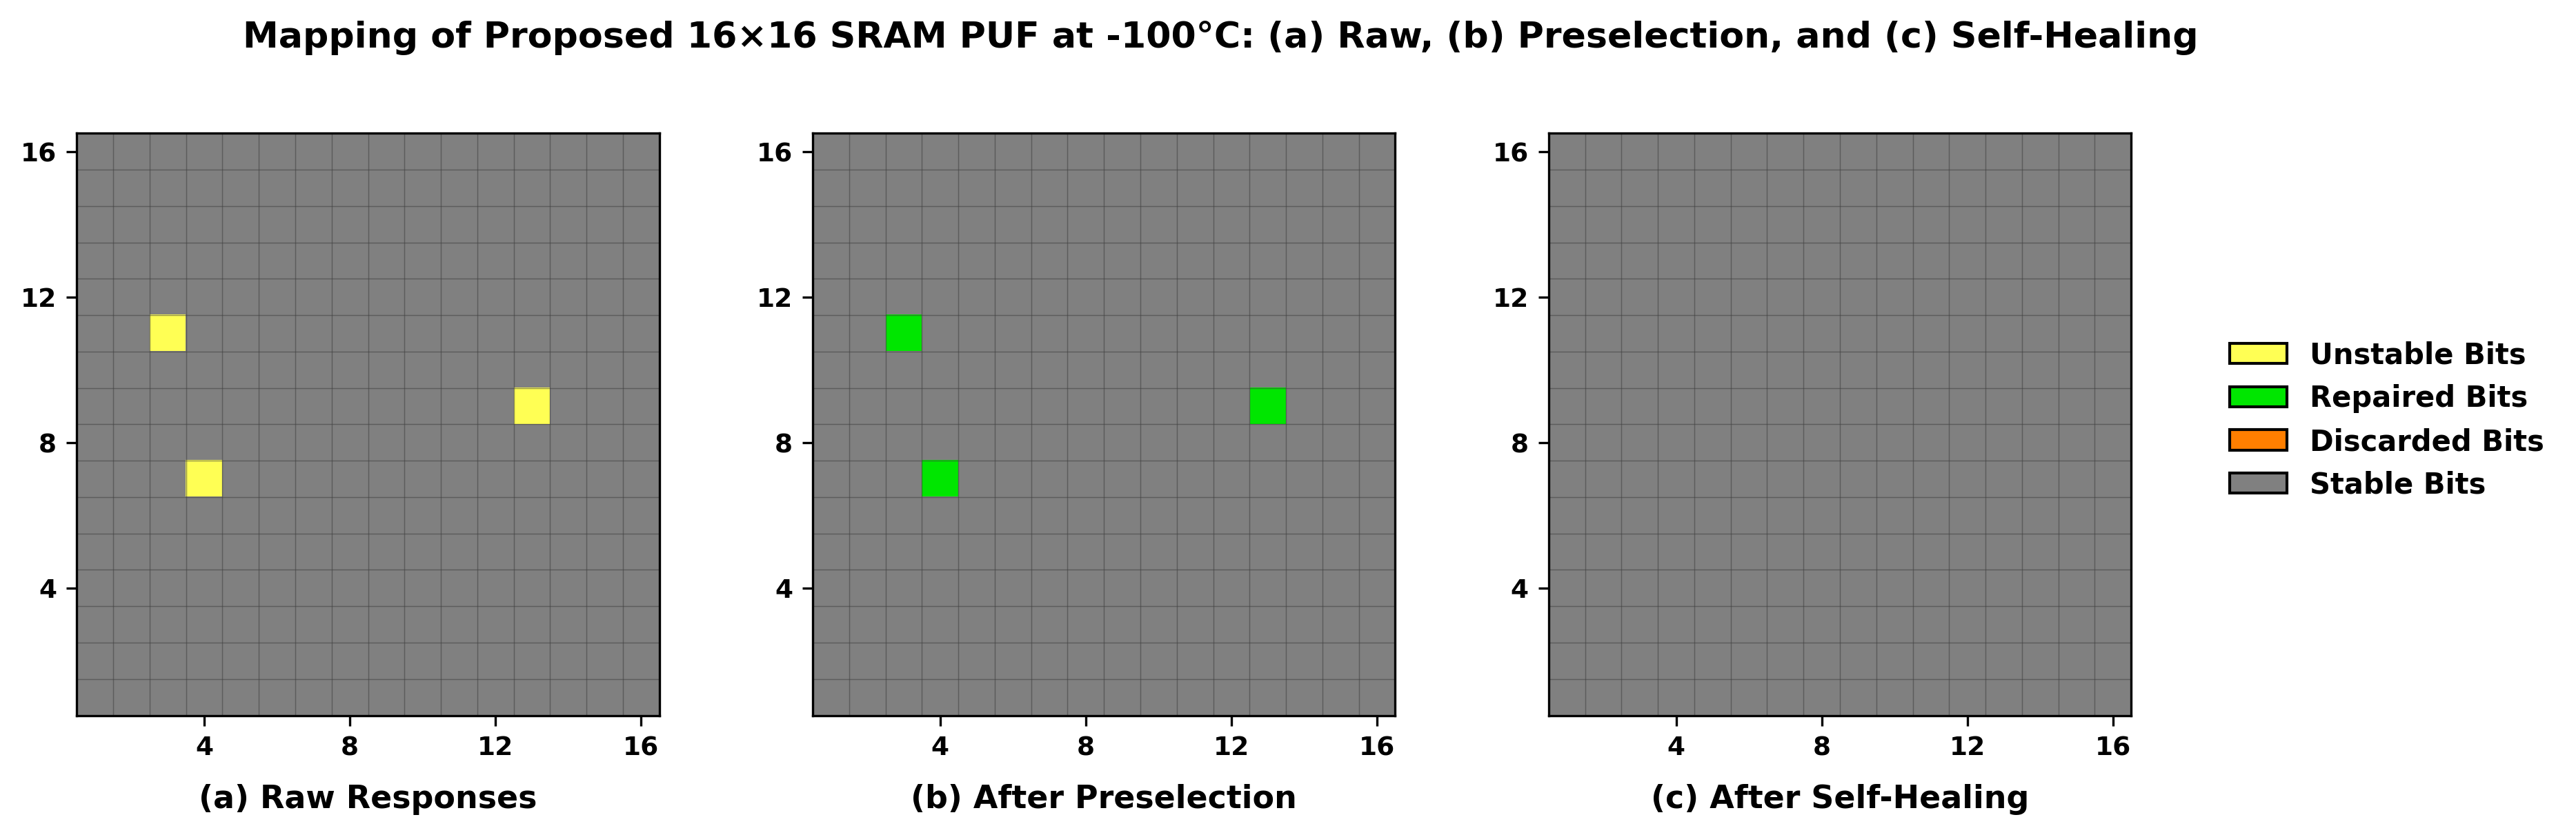


Processing Temperature = -40°C ...
  16x16 (256-CELL) SRAM PUF BIT DISTRIBUTION @ -40°C (Tilts: +120mV, -120mV)
Mode 1 Stable Bits (Grey)         : 241 / 256 (94.14%)
Mode 1 Unstable Bits (Yellow)     :  15 / 256 (5.86% Unstable before preselection)
--------------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  15 (100.00% of unstable bits healed)
Discarded Dark Bits (Orange)      :   0 (0.00% masked out)
--------------------------------------------------------------------------
Final Active Valid Golden Key Bits: 256 / 256 (100.00% Valid Bit Yield)
Golden Key Hamming Weight         : 142 / 256 (55.47% ones)
Saved spatial map -> 'puf_16x16_mapping_-40C.png'


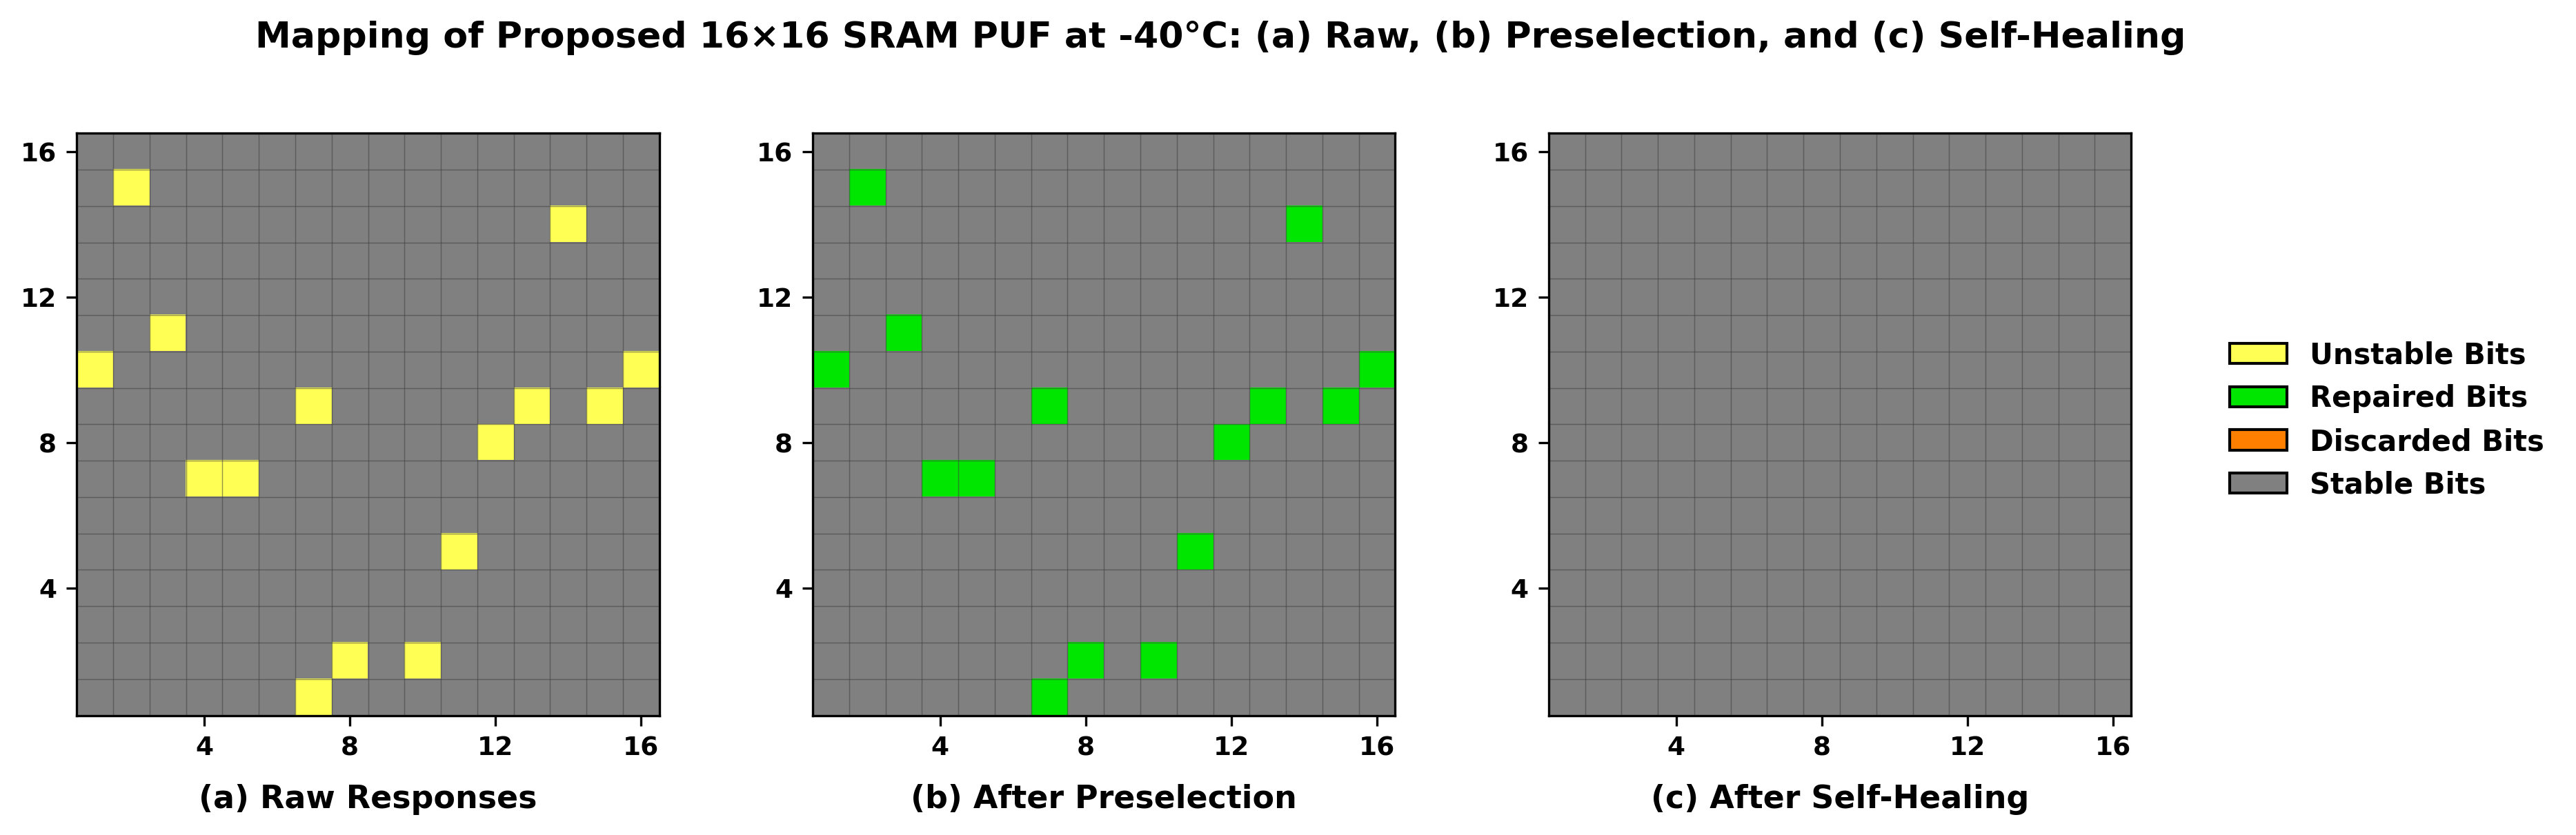


Processing Temperature = 0°C ...
  16x16 (256-CELL) SRAM PUF BIT DISTRIBUTION @ 0°C (Tilts: +120mV, -120mV)
Mode 1 Stable Bits (Grey)         : 229 / 256 (89.45%)
Mode 1 Unstable Bits (Yellow)     :  27 / 256 (10.55% Unstable before preselection)
--------------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  26 (96.30% of unstable bits healed)
Discarded Dark Bits (Orange)      :   1 (0.39% masked out)
--------------------------------------------------------------------------
Final Active Valid Golden Key Bits: 255 / 256 (99.61% Valid Bit Yield)
Golden Key Hamming Weight         : 140 / 255 (54.90% ones)
Saved spatial map -> 'puf_16x16_mapping_0C.png'


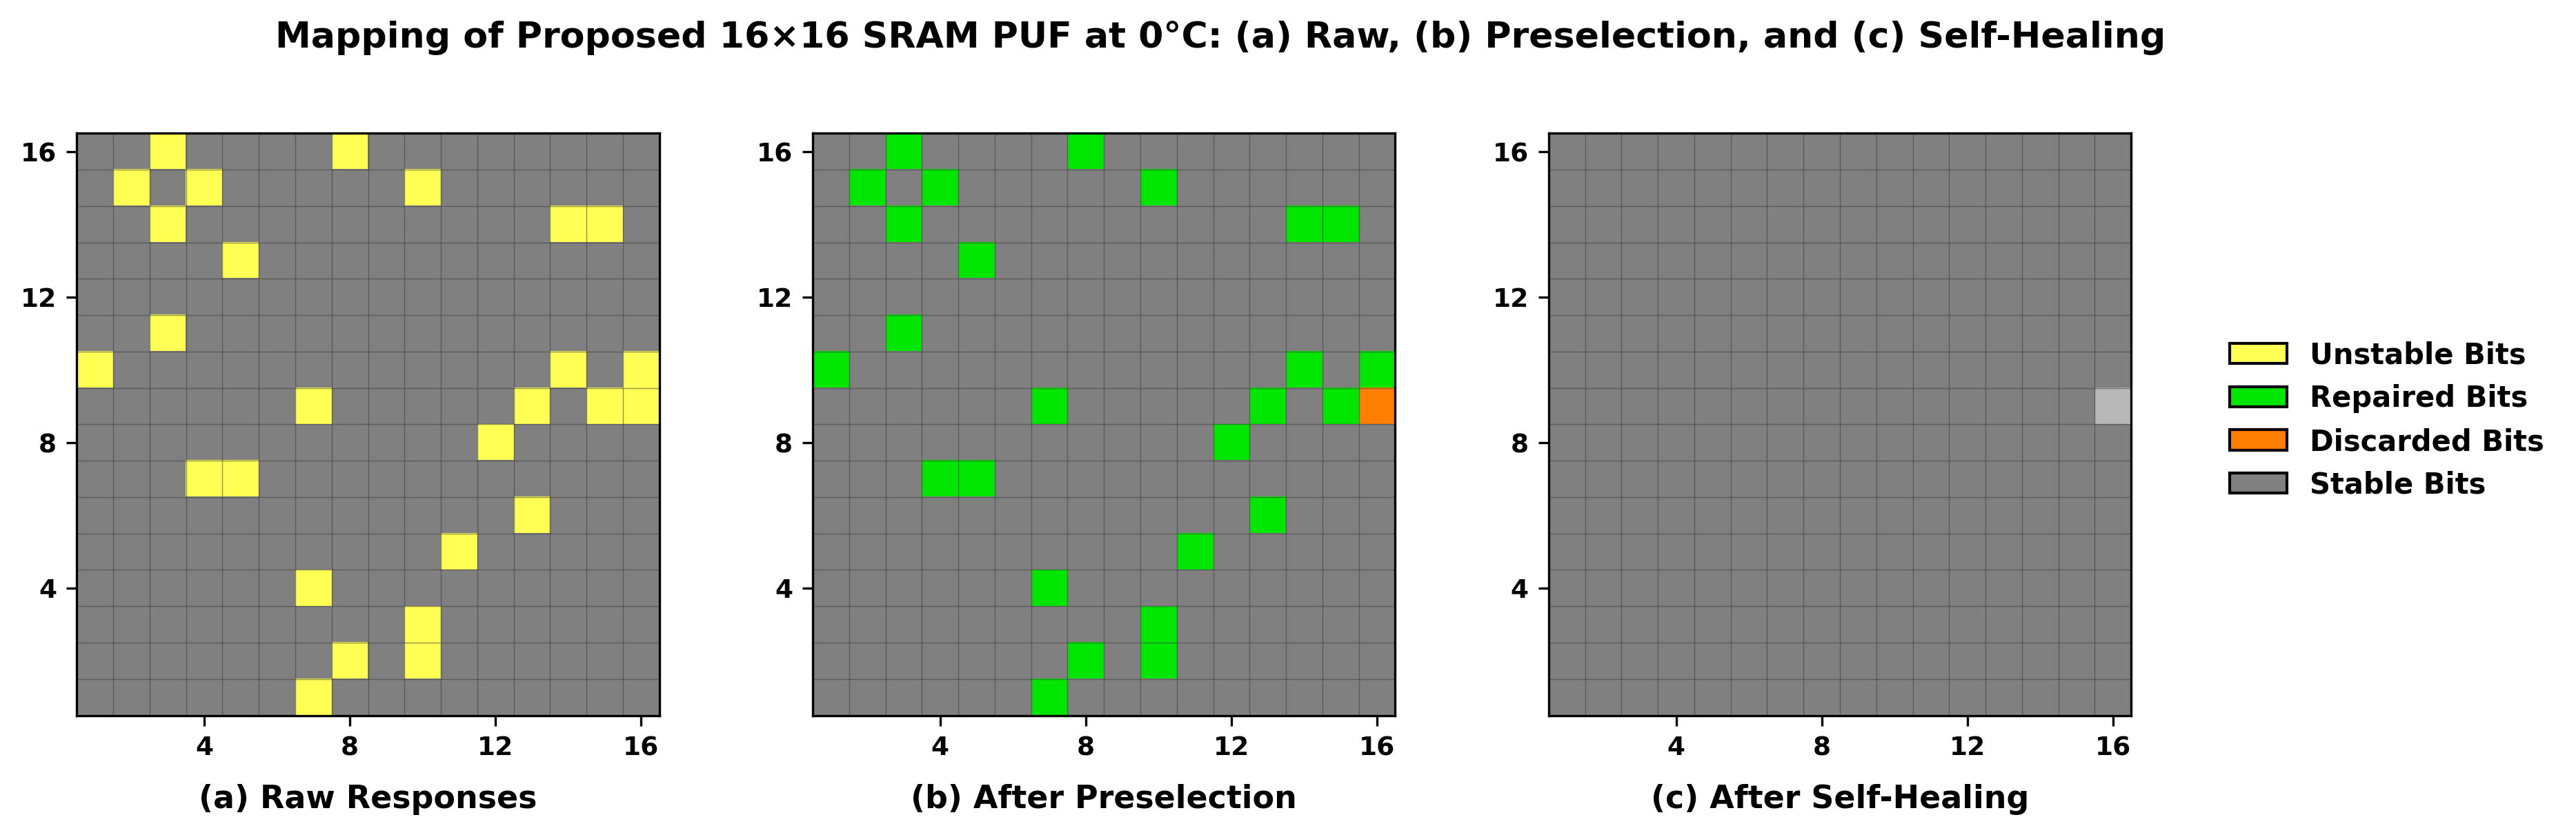


Processing Temperature = 27°C ...
  16x16 (256-CELL) SRAM PUF BIT DISTRIBUTION @ 27°C (Tilts: +120mV, -120mV)
Mode 1 Stable Bits (Grey)         : 226 / 256 (88.28%)
Mode 1 Unstable Bits (Yellow)     :  30 / 256 (11.72% Unstable before preselection)
--------------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  29 (96.67% of unstable bits healed)
Discarded Dark Bits (Orange)      :   1 (0.39% masked out)
--------------------------------------------------------------------------
Final Active Valid Golden Key Bits: 255 / 256 (99.61% Valid Bit Yield)
Golden Key Hamming Weight         : 141 / 255 (55.29% ones)
Saved spatial map -> 'puf_16x16_mapping_27C.png'


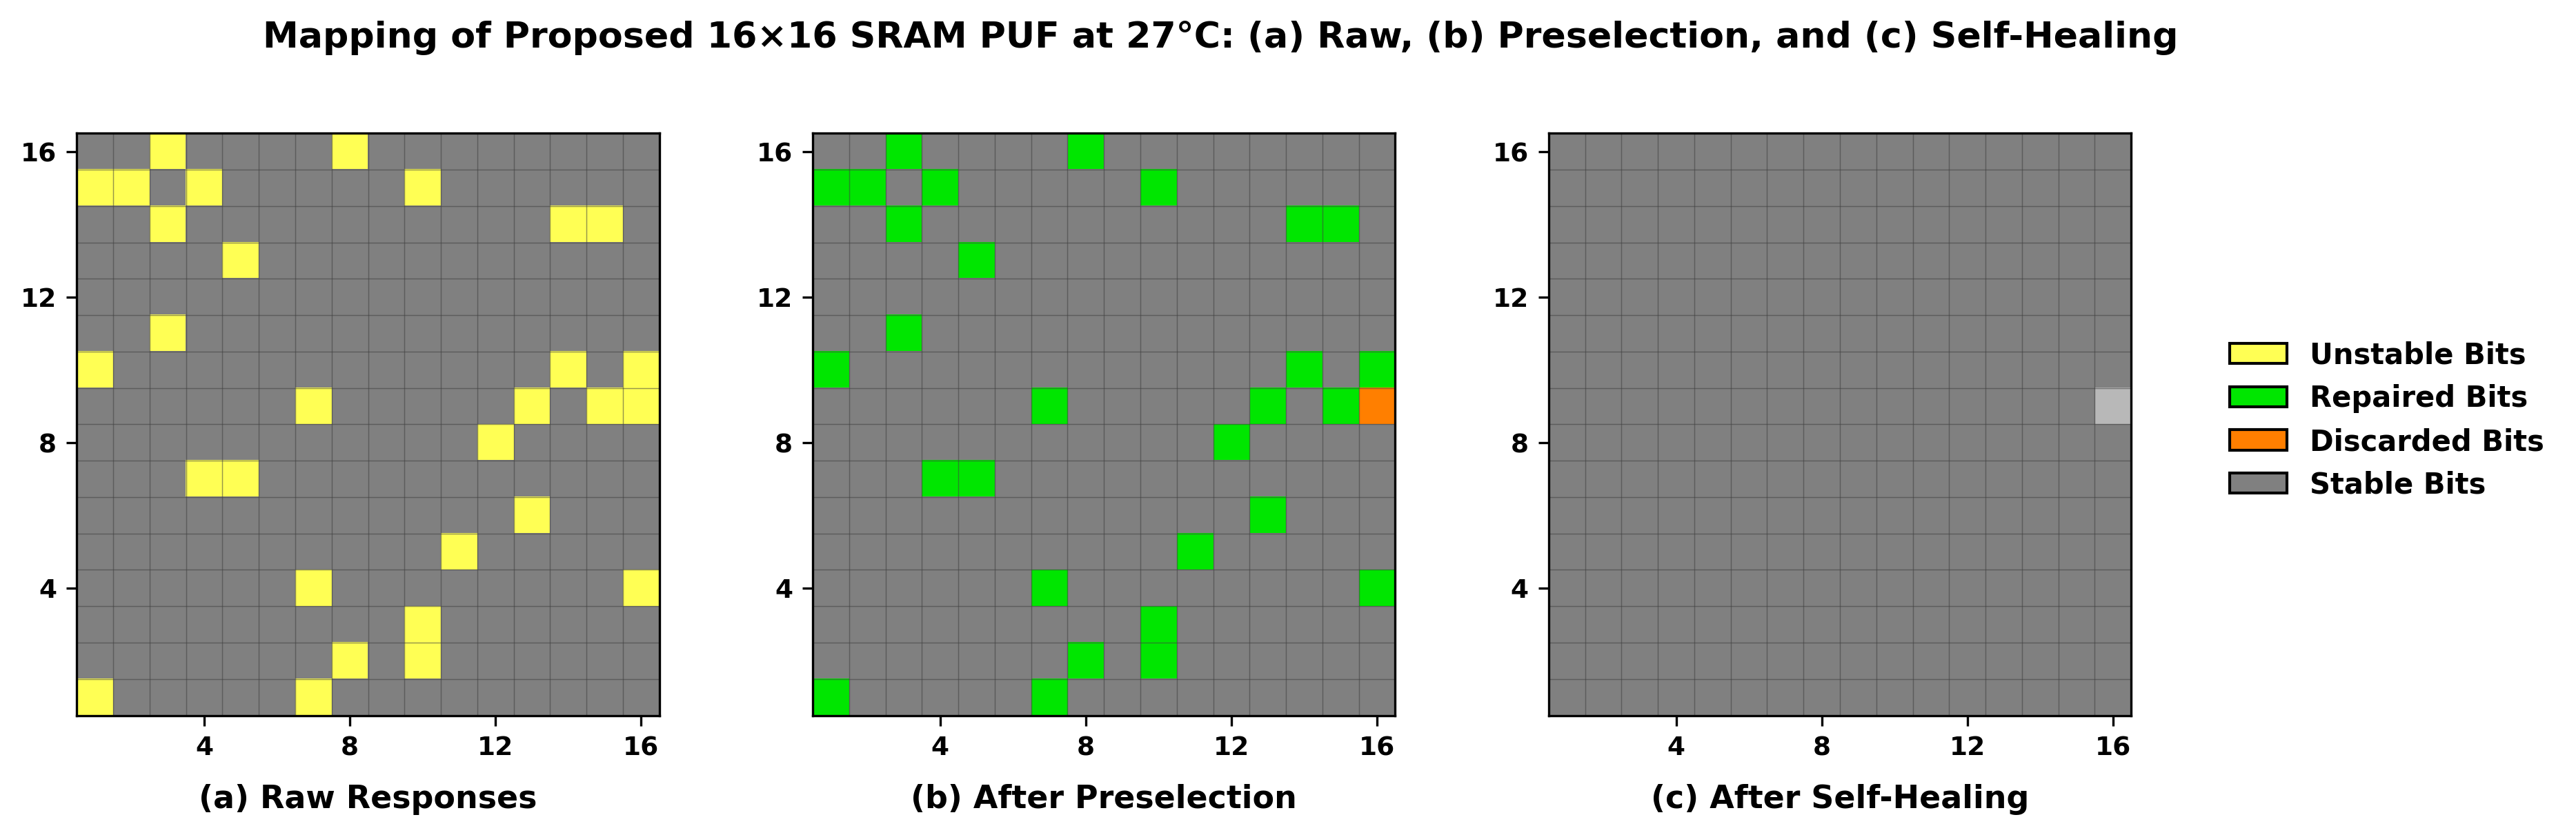


Processing Temperature = 75°C ...
  16x16 (256-CELL) SRAM PUF BIT DISTRIBUTION @ 75°C (Tilts: +120mV, -120mV)
Mode 1 Stable Bits (Grey)         : 212 / 256 (82.81%)
Mode 1 Unstable Bits (Yellow)     :  44 / 256 (17.19% Unstable before preselection)
--------------------------------------------------------------------------
Repaired via Mode 2 (Green)       :  36 (81.82% of unstable bits healed)
Discarded Dark Bits (Orange)      :   8 (3.12% masked out)
--------------------------------------------------------------------------
Final Active Valid Golden Key Bits: 248 / 256 (96.88% Valid Bit Yield)
Golden Key Hamming Weight         : 135 / 248 (54.44% ones)
Saved spatial map -> 'puf_16x16_mapping_75C.png'


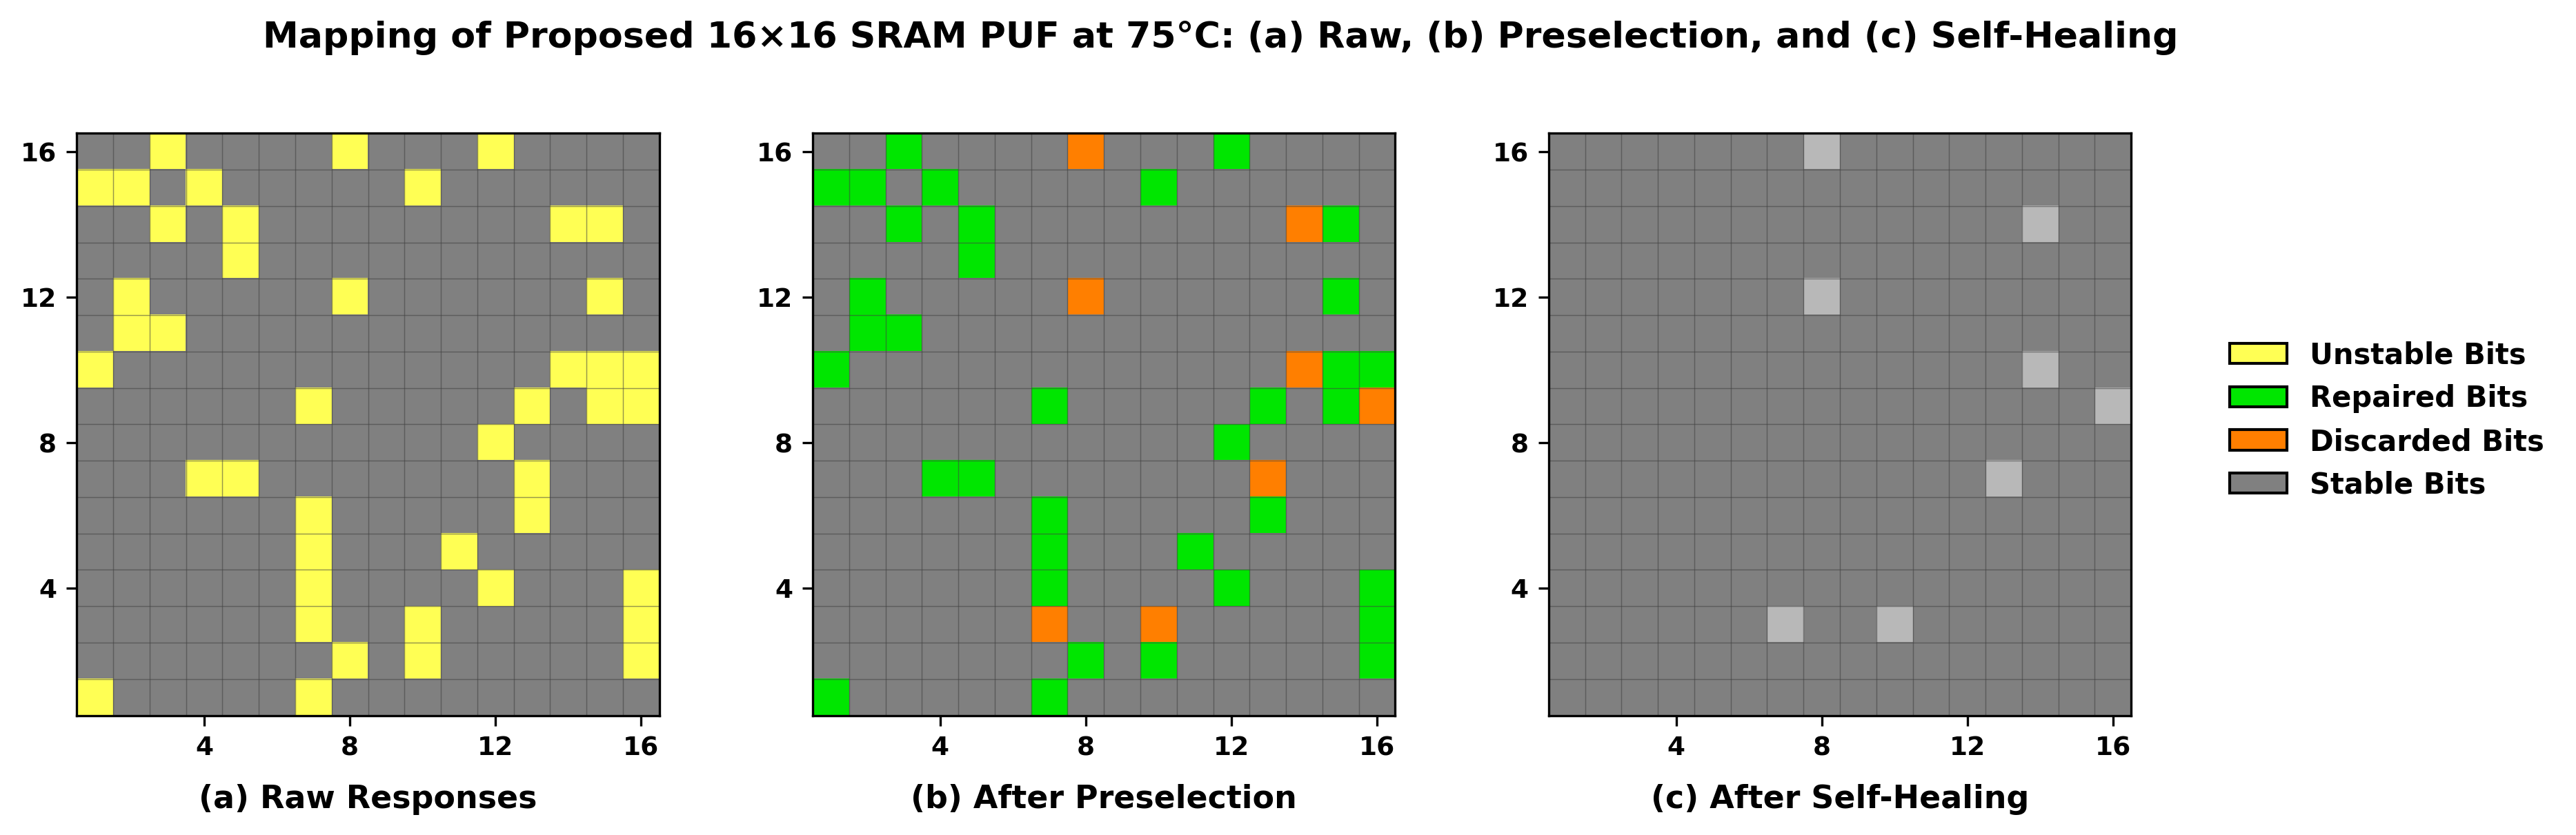


Saved cross-temperature bit distribution table -> 'puf_16x16_bit_distribution_all_temps.csv'
Saved cross-temperature distribution chart -> 'puf_16x16_bit_distribution_vs_temp.png'


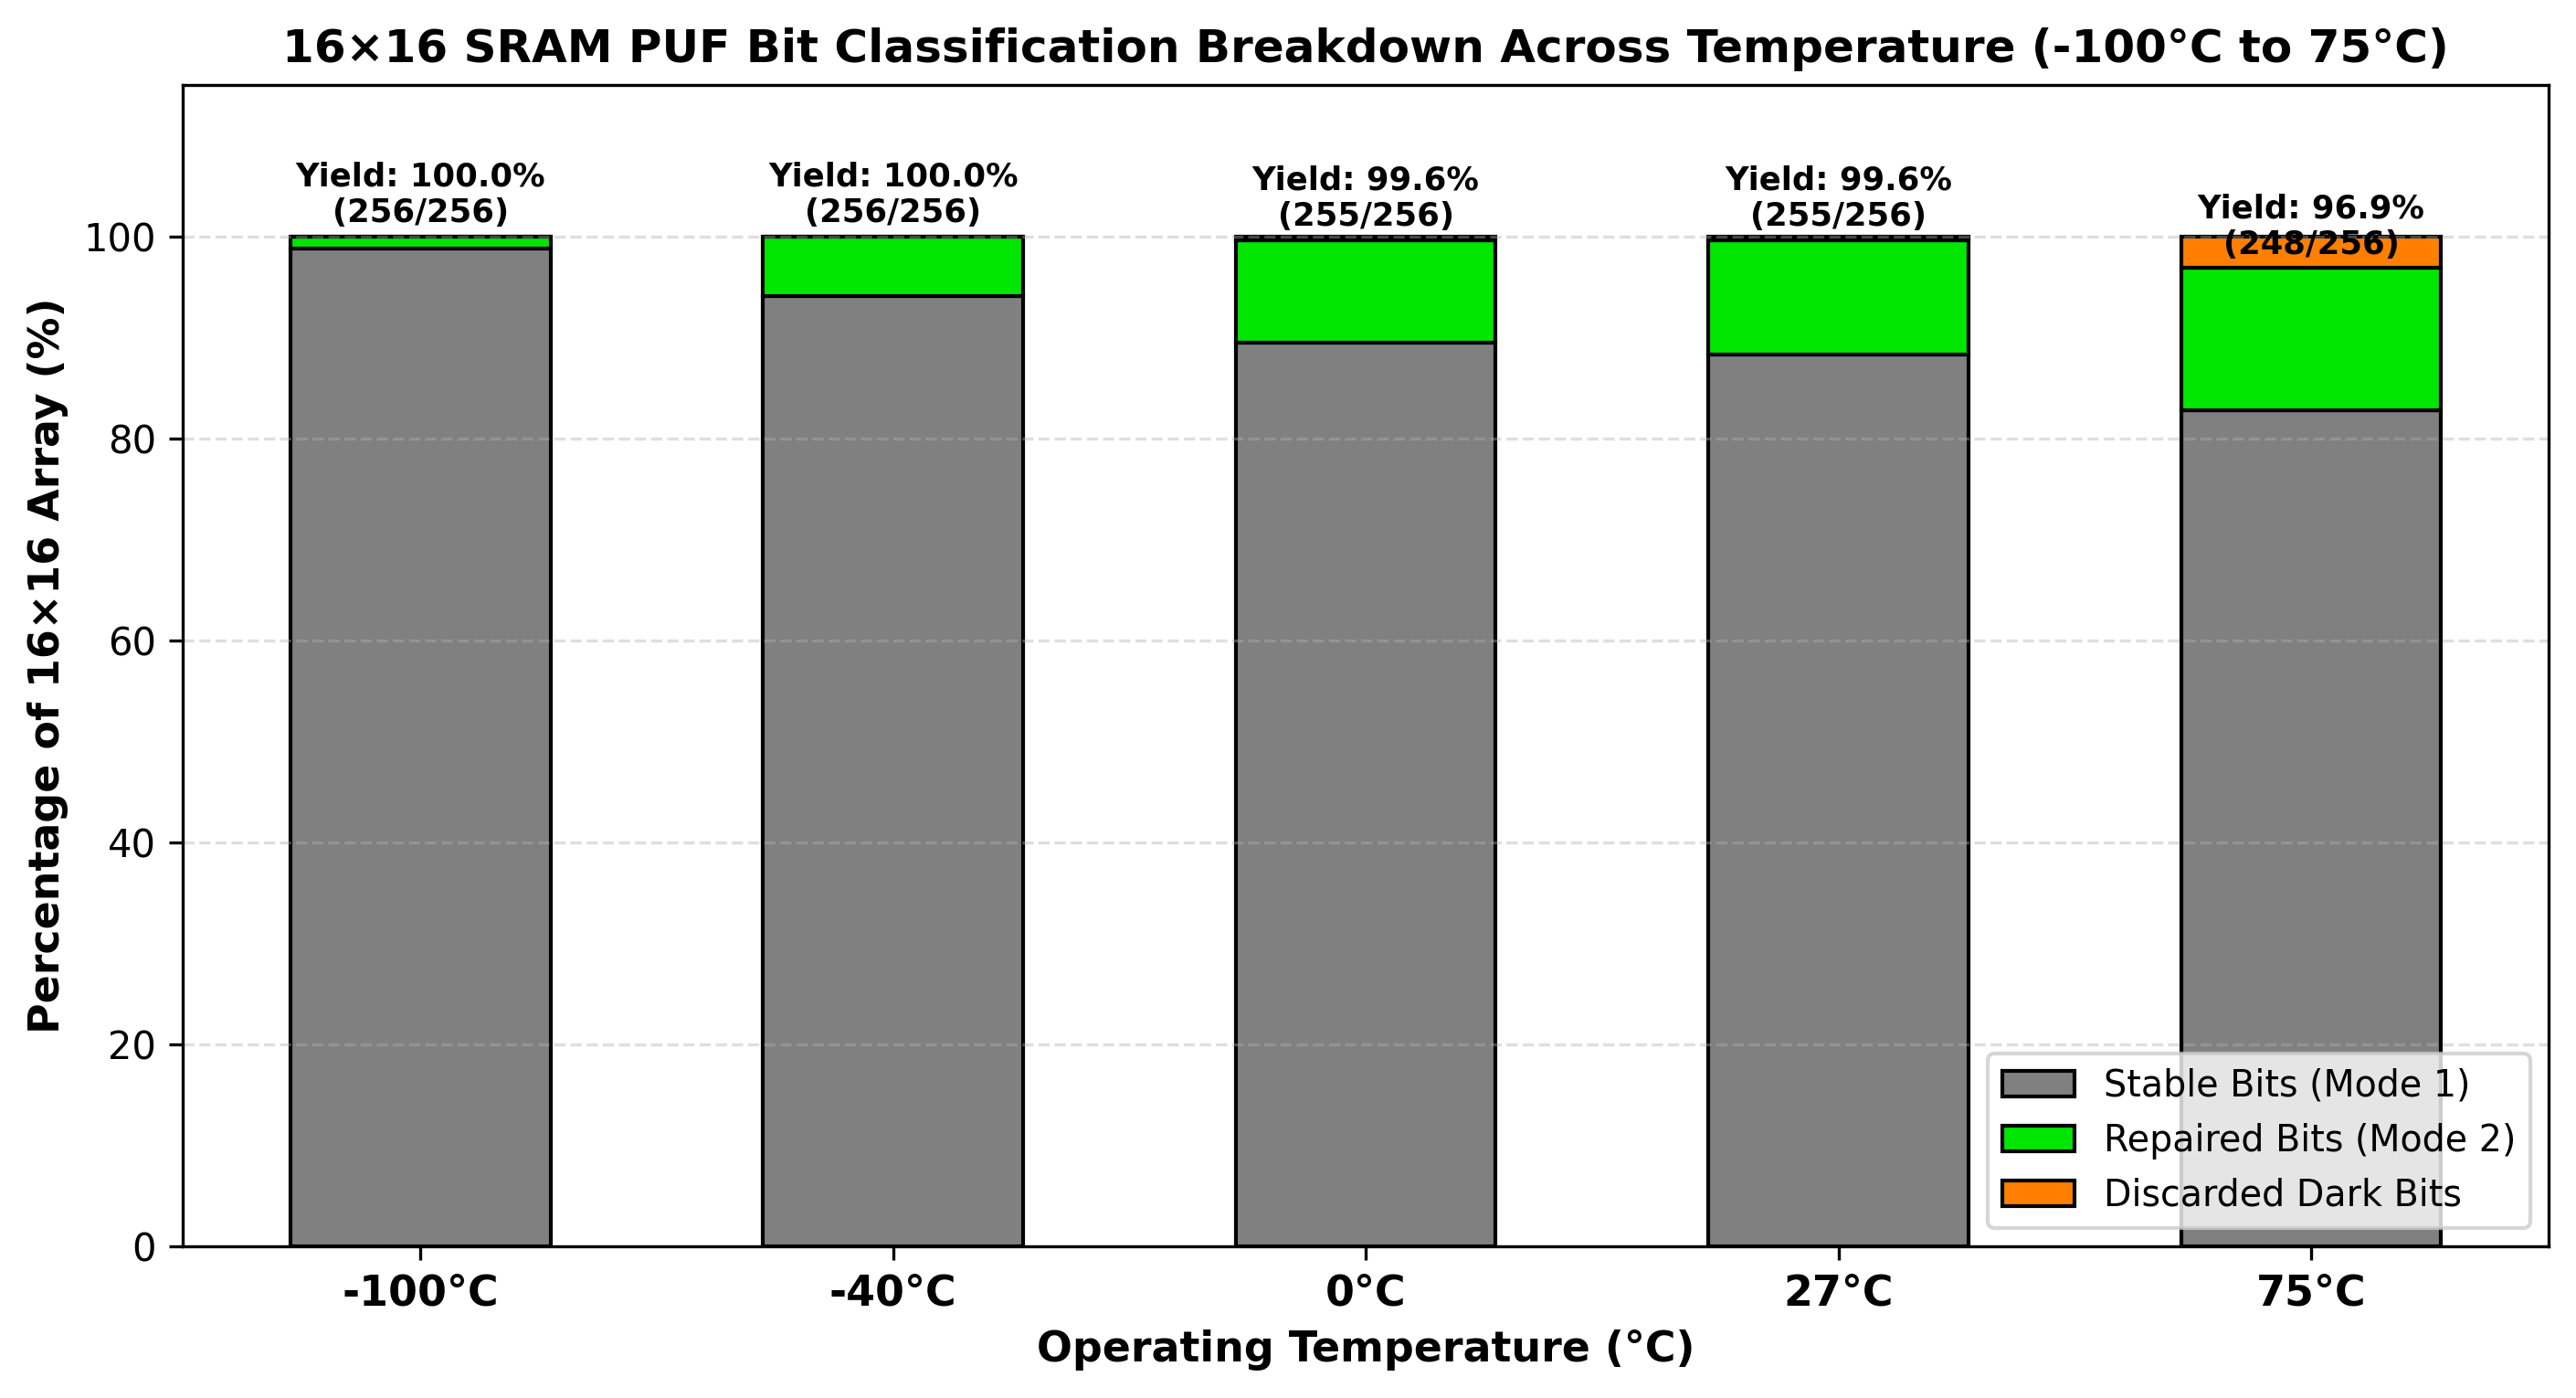

In [32]:
import os
import re
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: EXPLICIT CSV FILE NAMES (16 x 16 = 256 CELLS AT ALL TEMPS)
# ==============================================================================
VDD_NOMINAL = 0.9
ARRAY_ROWS = 16                 # 16 rows x 16 cols = 256 cells for all temperatures
ARRAY_COLS = 16

MODE2_WINDOW = (37e-9, 43e-9)   # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)  # Mode 1 active window: 97ns - 103ns

# Tilt corners used to define preselection stability & bit classification
EVAL_TILTS = ["+120mV", "-120mV"]

TEMPERATURE_FILES = {
    -100: {
        "Nominal": "mc_-100_256_0.9_vdd.csv",
        "+50mV":   "mc_-100_256_0.9_vdd+50.csv",
        "+80mV":   "mc_-100_256_0.9_vdd+80.csv",
        "+120mV":  "mc_-100_256_0.9_vdd+120.csv",
        "-50mV":   "mc_-100_256_0.9_vdd-50.csv",
        "-80mV":   "mc_-100_256_0.9_vdd-80.csv",
        "-120mV":  "mc_-100_256_0.9_vdd-120.csv",
    },
    -40: {
        "Nominal": "mc_-40_256_0.9_vdd.csv",
        "+50mV":   "mc_-40_256_0.9_vdd+50.csv",
        "+80mV":   "mc_-40_256_0.9_vdd+80.csv",
        "+120mV":  "mc_-40_256_0.9_vdd+120.csv",
        "-50mV":   "mc_-40_256_0.9_vdd-50.csv",
        "-80mV":   "mc_-40_256_0.9_vdd-80.csv",
        "-120mV":  "mc_-40_256_0.9_vdd-120.csv",
    },
    0: {
        "Nominal": "mc_0_256_0.9_vdd.csv",
        "+50mV":   "mc_0_256_0.9_vdd+50.csv",
        "+80mV":   "mc_0_256_0.9_vdd+80.csv",
        "+120mV":  "mc_0_256_0.9_vdd+120.csv",
        "-50mV":   "mc_0_256_0.9_vdd-50.csv",
        "-80mV":   "mc_0_256_0.9_vdd-80.csv",
        "-120mV":  "mc_0_256_0.9_vdd-120.csv",
    },
    27: {
        # Room temperature (27°C) 256-cell CSVs without temperature in filename
        "Nominal": "mc_256_0.9_vdd.csv",
        "+50mV":   "mc_256_0.9_vdd+50.csv",
        "+80mV":   "mc_256_0.9_vdd+80.csv",
        "+120mV":  "mc_256_0.9_vdd+120.csv",
        "-50mV":   "mc_256_0.9_vdd-50.csv",
        "-80mV":   "mc_256_0.9_vdd-80.csv",
        "-120mV":  "mc_256_0.9_vdd-120.csv",
    },
    75: {
        # 75°C uses uppercase 'VDD' in file naming
        "Nominal": "mc_75_256_0.9_VDD.csv",
        "+50mV":   "mc_75_256_0.9_VDD+50.csv",
        "+80mV":   "mc_75_256_0.9_VDD+80.csv",
        "+120mV":  "mc_75_256_0.9_VDD+120.csv",
        "-50mV":   "mc_75_256_0.9_VDD-50.csv",
        "-80mV":   "mc_75_256_0.9_VDD-80.csv",
        "-120mV":  "mc_75_256_0.9_VDD-120.csv",
    },
}


# ==============================================================================
# 2. HELPER FUNCTIONS
# ==============================================================================
def extract_bits_from_csv(csv_path, target_temp=None, vdd=0.9):
    """Reads /BL (or complementary /BLb if /BL was omitted in Cadence export)
    and filters by target_temp if multiple temperature sweeps exist in one CSV.
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find CSV file: {csv_path}")

    all_cols = pd.read_csv(csv_path, nrows=0).columns.tolist()
    threshold = vdd / 2.0

    bl_cols = [c for c in all_cols if re.search(r"(?:^|/)BL\s*\(", c.strip())]
    blb_cols = [c for c in all_cols if re.search(r"(?:^|/)BLb\s*\(", c.strip())]

    use_inverted_blb = False
    candidate_cols = bl_cols
    if not candidate_cols and blb_cols:
        candidate_cols = blb_cols
        use_inverted_blb = True

    if not candidate_cols:
        raise ValueError(f"No '/BL' or '/BLb' columns found in {csv_path}.")

    # Filter to target_temp if multiple temperature=... tags exist in the same file
    temps_in_cols = set(
        re.findall(r"temperature=([^,)]+)", " ".join(candidate_cols))
    )
    if len(temps_in_cols) > 1 and target_temp is not None:
        t_str = str(target_temp)
        filtered = [
            c
            for c in candidate_cols
            if f"temperature={t_str}," in c or f"temperature={t_str})" in c
        ]
        if filtered:
            candidate_cols = filtered

    df = pd.read_csv(csv_path, usecols=candidate_cols, low_memory=False)

    col_map = {}
    for c in df.columns:
        c_clean = c.strip()
        m_id = re.search(r"mcparamset=(\d+)", c_clean)
        if not m_id:
            continue
        mc_id = int(m_id.group(1))
        if c_clean.endswith(" X"):
            col_map.setdefault(mc_id, {})["X"] = c
        elif c_clean.endswith(" Y"):
            col_map.setdefault(mc_id, {})["Y"] = c

    paramset_ids = sorted(col_map.keys())
    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(df[col_map[mc_id]["X"]], errors="coerce").values
        v_bl = pd.to_numeric(df[col_map[mc_id]["Y"]], errors="coerce").values

        v1 = np.nanmean(v_bl[(t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])])
        v2 = np.nanmean(v_bl[(t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])])

        if use_inverted_blb:
            m1_bits[idx] = 1 if v1 < threshold else 0
            m2_bits[idx] = 1 if v2 < threshold else 0
        else:
            m1_bits[idx] = 1 if v1 >= threshold else 0
            m2_bits[idx] = 1 if v2 >= threshold else 0

    return {"m1_bits": m1_bits, "m2_bits": m2_bits}


def plot_3panel_16x16_map(grid_a, grid_b, grid_c, temp_c):
    """Generates the 3-panel 16x16 spatial bit mapping for a given temperature."""
    cmap = mcolors.ListedColormap(
        ["#808080", "#FFFF54", "#00E600", "#FF7F00", "#B8B8B8"]
    )
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.2), dpi=300)
    titles = [
        "(a) Raw Responses",
        "(b) After Preselection",
        "(c) After Self-Healing",
    ]
    grids = [grid_a, grid_b, grid_c]

    ticks = [3, 7, 11, 15]
    labels = ["4", "8", "12", "16"]

    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap=cmap, norm=norm, origin="lower", aspect="equal")

        ax.set_xticks(np.arange(-0.5, ARRAY_COLS, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, ARRAY_ROWS, 1), minor=True)
        ax.grid(
            which="minor",
            color="#404040",
            linestyle="-",
            linewidth=0.35,
            alpha=0.55,
        )
        ax.tick_params(which="minor", bottom=False, left=False)

        ax.set_xticks(ticks)
        ax.set_xticklabels(labels, fontsize=9, fontweight="bold")
        ax.set_yticks(ticks)
        ax.set_yticklabels(labels, fontsize=9, fontweight="bold")
        ax.set_xlabel(title, fontsize=11, fontweight="bold", labelpad=8)

    legend_patches = [
        mpatches.Patch(facecolor="#FFFF54", edgecolor="black", label="Unstable Bits"),
        mpatches.Patch(facecolor="#00E600", edgecolor="black", label="Repaired Bits"),
        mpatches.Patch(facecolor="#FF7F00", edgecolor="black", label="Discarded Bits"),
        mpatches.Patch(facecolor="#808080", edgecolor="black", label="Stable Bits"),
    ]
    fig.legend(
        handles=legend_patches,
        loc="center left",
        bbox_to_anchor=(0.88, 0.52),
        frameon=False,
        fontsize=10,
        prop={"weight": "bold"},
    )

    plt.suptitle(
        f"Mapping of Proposed 16×16 SRAM PUF at {temp_c}°C: (a) Raw, (b) Preselection, and (c) Self-Healing",
        fontsize=12.5,
        fontweight="bold",
        y=0.98,
    )
    plt.subplots_adjust(left=0.05, right=0.86, top=0.85, bottom=0.18, wspace=0.18)

    out_png = f"puf_16x16_mapping_{temp_c}C.png"
    plt.savefig(out_png, dpi=300, bbox_inches="tight")
    print(f"Saved spatial map -> '{out_png}'")
    plt.show()


# ==============================================================================
# 3. MAIN EXECUTION: ANALYZE 16x16 BIT DISTRIBUTIONS ACROSS ALL 5 TEMPERATURES
# ==============================================================================
def run_multitemp_bit_distribution():
    summary_rows = []
    expected_cells = ARRAY_ROWS * ARRAY_COLS

    for temp_c, file_dict in TEMPERATURE_FILES.items():
        print(f"\nProcessing Temperature = {temp_c}°C ...")
        data_nom = extract_bits_from_csv(
            file_dict["Nominal"], target_temp=temp_c, vdd=VDD_NOMINAL
        )
        num_cells = len(data_nom["m1_bits"])
        assert (
            num_cells == expected_cells
        ), f"Expected {expected_cells} cells at {temp_c}°C, got {num_cells}"

        m1_stable = np.ones(num_cells, dtype=bool)
        m2_stable = np.ones(num_cells, dtype=bool)
        used_tilts = []

        for tilt_label in EVAL_TILTS:
            tilt_path = file_dict[tilt_label]
            if not os.path.exists(tilt_path):
                print(f"  [Note] Tilt file not found (skipped): {tilt_path}")
                continue
            data_tilt = extract_bits_from_csv(
                tilt_path, target_temp=temp_c, vdd=VDD_NOMINAL
            )
            m1_stable &= data_nom["m1_bits"] == data_tilt["m1_bits"]
            m2_stable &= data_nom["m2_bits"] == data_tilt["m2_bits"]
            used_tilts.append(tilt_label)

        if not used_tilts:
            raise FileNotFoundError(f"No tilt CSV files found for {temp_c}°C.")

        m1_unstable = ~m1_stable
        repaired_mask = m1_unstable & m2_stable
        discarded_mask = m1_unstable & (~m2_stable)

        map_a = np.where(m1_stable, 0, 1)

        map_b = np.zeros(num_cells, dtype=int)
        map_b[m1_stable] = 0
        map_b[repaired_mask] = 2
        map_b[discarded_mask] = 3

        map_c = np.zeros(num_cells, dtype=int)
        map_c[m1_stable | repaired_mask] = 0
        map_c[discarded_mask] = 4

        grid_a = map_a.reshape(ARRAY_ROWS, ARRAY_COLS)
        grid_b = map_b.reshape(ARRAY_ROWS, ARRAY_COLS)
        grid_c = map_c.reshape(ARRAY_ROWS, ARRAY_COLS)

        n_m1_stable = int(np.sum(m1_stable))
        n_m1_unstable = int(np.sum(m1_unstable))
        n_repaired = int(np.sum(repaired_mask))
        n_discarded = int(np.sum(discarded_mask))
        n_final_valid = n_m1_stable + n_repaired

        raw_instab_pct = (n_m1_unstable / num_cells) * 100.0
        healing_rate_pct = (
            (n_repaired / n_m1_unstable * 100.0) if n_m1_unstable > 0 else 100.0
        )
        valid_yield_pct = (n_final_valid / num_cells) * 100.0

        golden_key_array = np.where(
            m1_stable,
            data_nom["m1_bits"],
            np.where(repaired_mask, data_nom["m2_bits"], -1),
        )
        valid_golden_bits = golden_key_array[golden_key_array != -1]
        golden_hw = int(np.sum(valid_golden_bits))

        print("=" * 74)
        print(f"  16x16 (256-CELL) SRAM PUF BIT DISTRIBUTION @ {temp_c}°C (Tilts: {', '.join(used_tilts)})")
        print("=" * 74)
        print(f"Mode 1 Stable Bits (Grey)         : {n_m1_stable:3d} / {num_cells} ({n_m1_stable/num_cells*100:.2f}%)")
        print(f"Mode 1 Unstable Bits (Yellow)     : {n_m1_unstable:3d} / {num_cells} ({raw_instab_pct:.2f}% Unstable before preselection)")
        print("-" * 74)
        print(f"Repaired via Mode 2 (Green)       : {n_repaired:3d} ({healing_rate_pct:.2f}% of unstable bits healed)")
        print(f"Discarded Dark Bits (Orange)      : {n_discarded:3d} ({n_discarded/num_cells*100:.2f}% masked out)")
        print("-" * 74)
        print(f"Final Active Valid Golden Key Bits: {n_final_valid:3d} / {num_cells} ({valid_yield_pct:.2f}% Valid Bit Yield)")
        print(f"Golden Key Hamming Weight         : {golden_hw:3d} / {n_final_valid} ({golden_hw/n_final_valid*100:.2f}% ones)")
        print("=" * 74)

        plot_3panel_16x16_map(grid_a, grid_b, grid_c, temp_c)

        summary_rows.append(
            {
                "Temp_C": temp_c,
                "Total_Cells": num_cells,
                "M1_Stable_Count": n_m1_stable,
                "M1_Unstable_Count": n_m1_unstable,
                "Repaired_Count": n_repaired,
                "Discarded_Count": n_discarded,
                "Valid_Bits_Count": n_final_valid,
                "M1_Stable_Pct": n_m1_stable / num_cells * 100.0,
                "M1_Unstable_Pct": raw_instab_pct,
                "Repaired_Pct_of_Total": n_repaired / num_cells * 100.0,
                "Healing_Efficiency_Pct": healing_rate_pct,
                "Discarded_Pct": n_discarded / num_cells * 100.0,
                "Valid_Yield_Pct": valid_yield_pct,
                "Golden_HW_Pct": golden_hw / n_final_valid * 100.0,
            }
        )

    dist_df = pd.DataFrame(summary_rows)
    dist_df.to_csv("puf_16x16_bit_distribution_all_temps.csv", index=False)
    print("\nSaved cross-temperature bit distribution table -> 'puf_16x16_bit_distribution_all_temps.csv'")

    fig, ax = plt.subplots(figsize=(9.5, 5.2), dpi=300)
    x = np.arange(len(dist_df))
    temp_labels = [f"{t}°C" for t in dist_df["Temp_C"]]

    ax.bar(x, dist_df["M1_Stable_Pct"], width=0.55, color="#808080", edgecolor="black", label="Stable Bits (Mode 1)")
    ax.bar(x, dist_df["Repaired_Pct_of_Total"], width=0.55, bottom=dist_df["M1_Stable_Pct"], color="#00E600", edgecolor="black", label="Repaired Bits (Mode 2)")
    ax.bar(x, dist_df["Discarded_Pct"], width=0.55, bottom=dist_df["M1_Stable_Pct"] + dist_df["Repaired_Pct_of_Total"], color="#FF7F00", edgecolor="black", label="Discarded Dark Bits")

    for i, row in dist_df.iterrows():
        ax.text(
            i,
            row["Valid_Yield_Pct"] + 0.8,
            f"Yield: {row['Valid_Yield_Pct']:.1f}%\n({int(row['Valid_Bits_Count'])}/256)",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
        )

    ax.set_xticks(x)
    ax.set_xticklabels(temp_labels, fontsize=11, fontweight="bold")
    ax.set_ylabel("Percentage of 16×16 Array (%)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Operating Temperature (°C)", fontsize=11, fontweight="bold")
    ax.set_ylim(0, 115)
    ax.set_title("16×16 SRAM PUF Bit Classification Breakdown Across Temperature (-100°C to 75°C)", fontsize=12, fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(loc="lower right", frameon=True, fontsize=9.5)

    plt.tight_layout()
    plt.savefig("puf_16x16_bit_distribution_vs_temp.png", dpi=300, bbox_inches="tight")
    print("Saved cross-temperature distribution chart -> 'puf_16x16_bit_distribution_vs_temp.png'")
    plt.show()


if __name__ == "__main__":
    run_multitemp_bit_distribution()


  TEMPERATURE = -100°C  (16×16 = 256 Cells | 256 Valid Bits | Nom Drift vs 27°C: 1.56%)
Tilt Corner  |  Raw M1 BER |  Raw M2 BER |  Healed BER |  Final BER
----------------------------------------------------------------------------------
+50mV        |       0.00% |       0.39% |       0.00% |      0.00%
-50mV        |       0.00% |       0.00% |       0.00% |      0.00%
+80mV        |       0.00% |       0.78% |       0.00% |      0.00%
-80mV        |       0.39% |       0.78% |       0.00% |      0.00%
+120mV       |       0.39% |       1.56% |       0.00% |      0.00%
-120mV       |       0.78% |       0.78% |       0.00% |      0.00%
----------------------------------------------------------------------------------
MEAN (Tilts) |       0.26% |       0.72% |       0.00% |      0.00%
128b BLER    |      28.38% |      60.15% |       0.00% |      0.00%
256b BLER    |      48.70% |      84.12% |       0.00% |      0.00%
  [Note] Optional tilt file not found (skipped): mc_-40_256_0.9_v

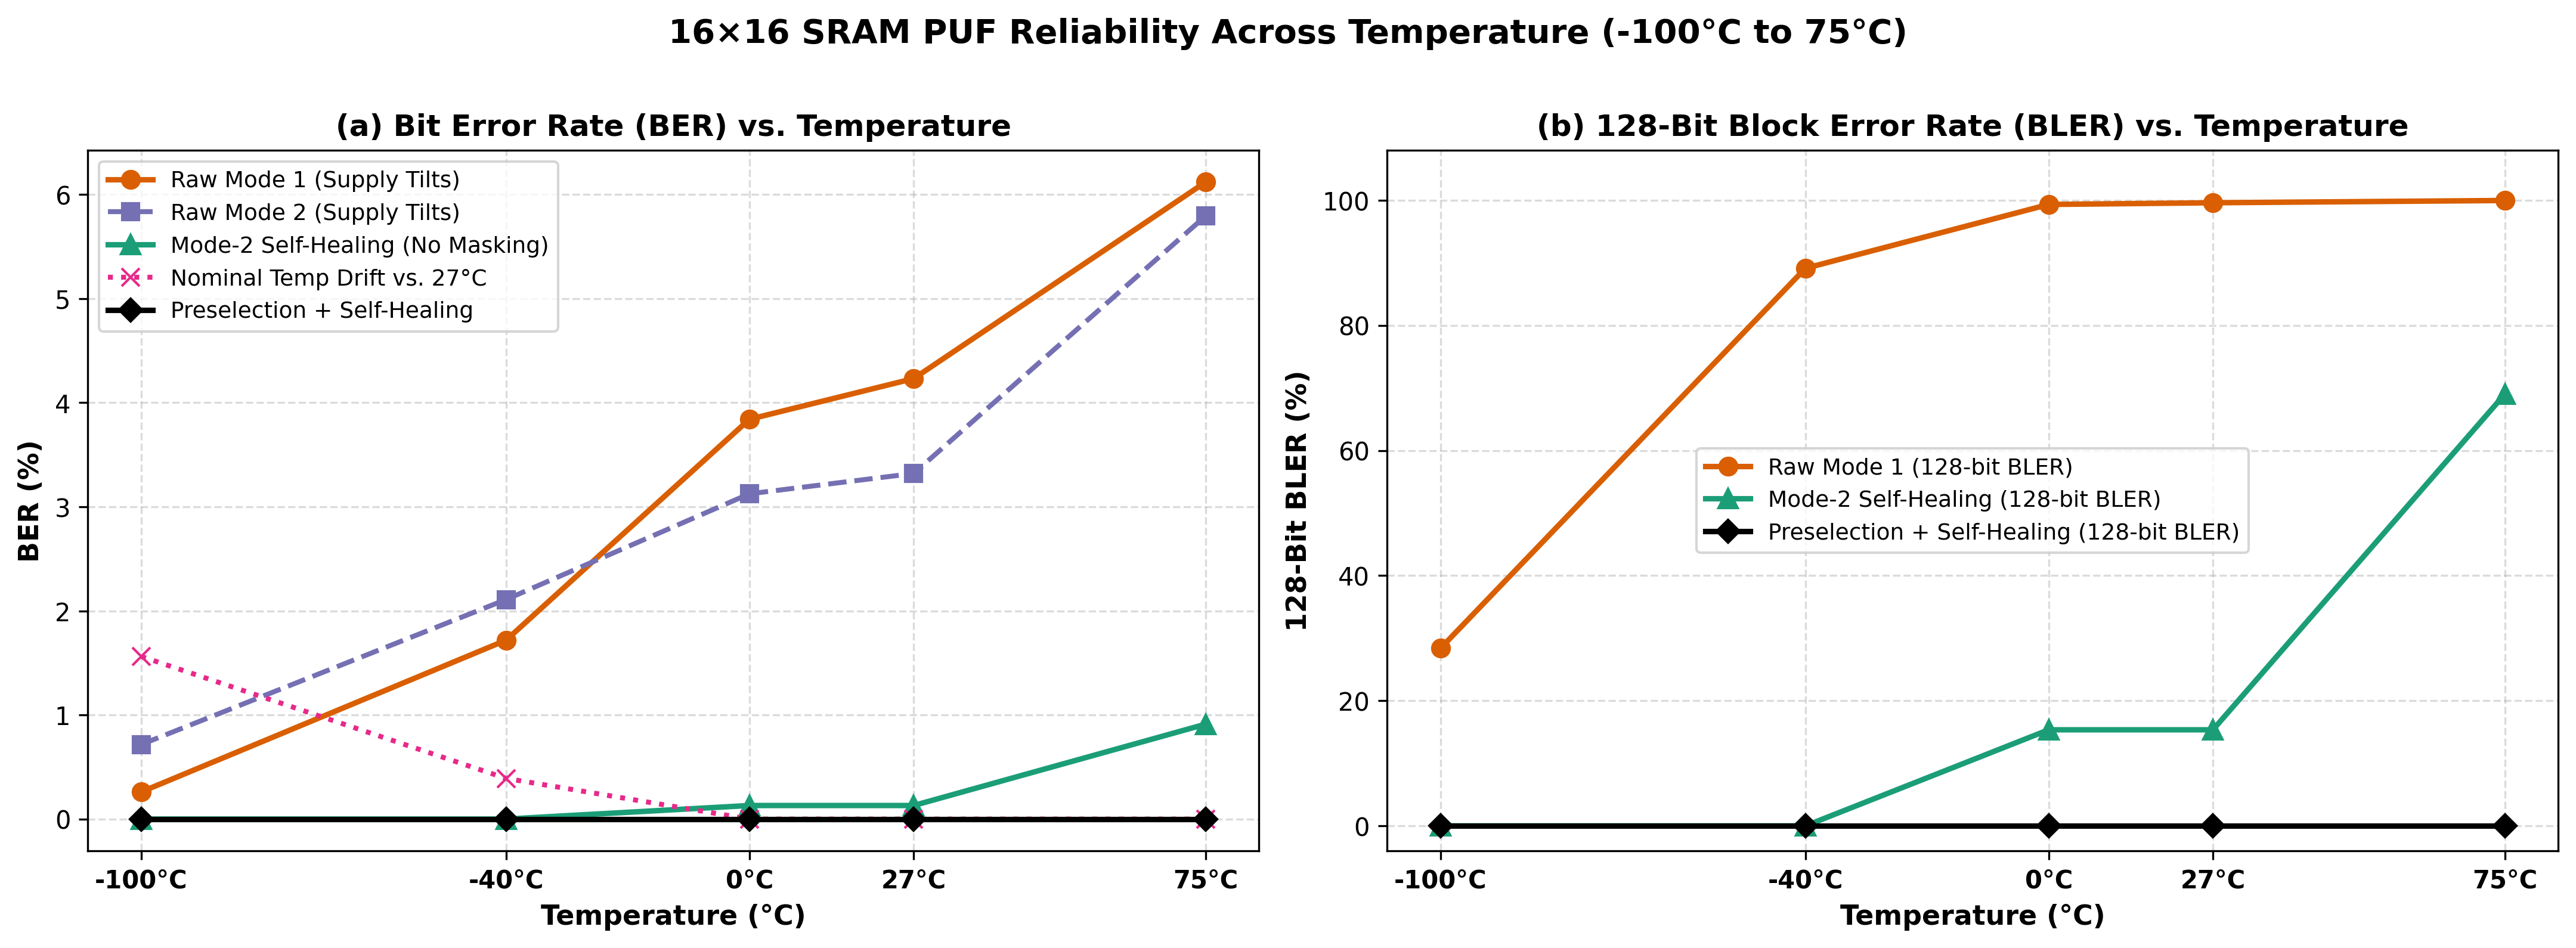

Saved per-tilt BER vs. Temperature plot -> 'puf_16x16_tilt_ber_vs_temperature.png'


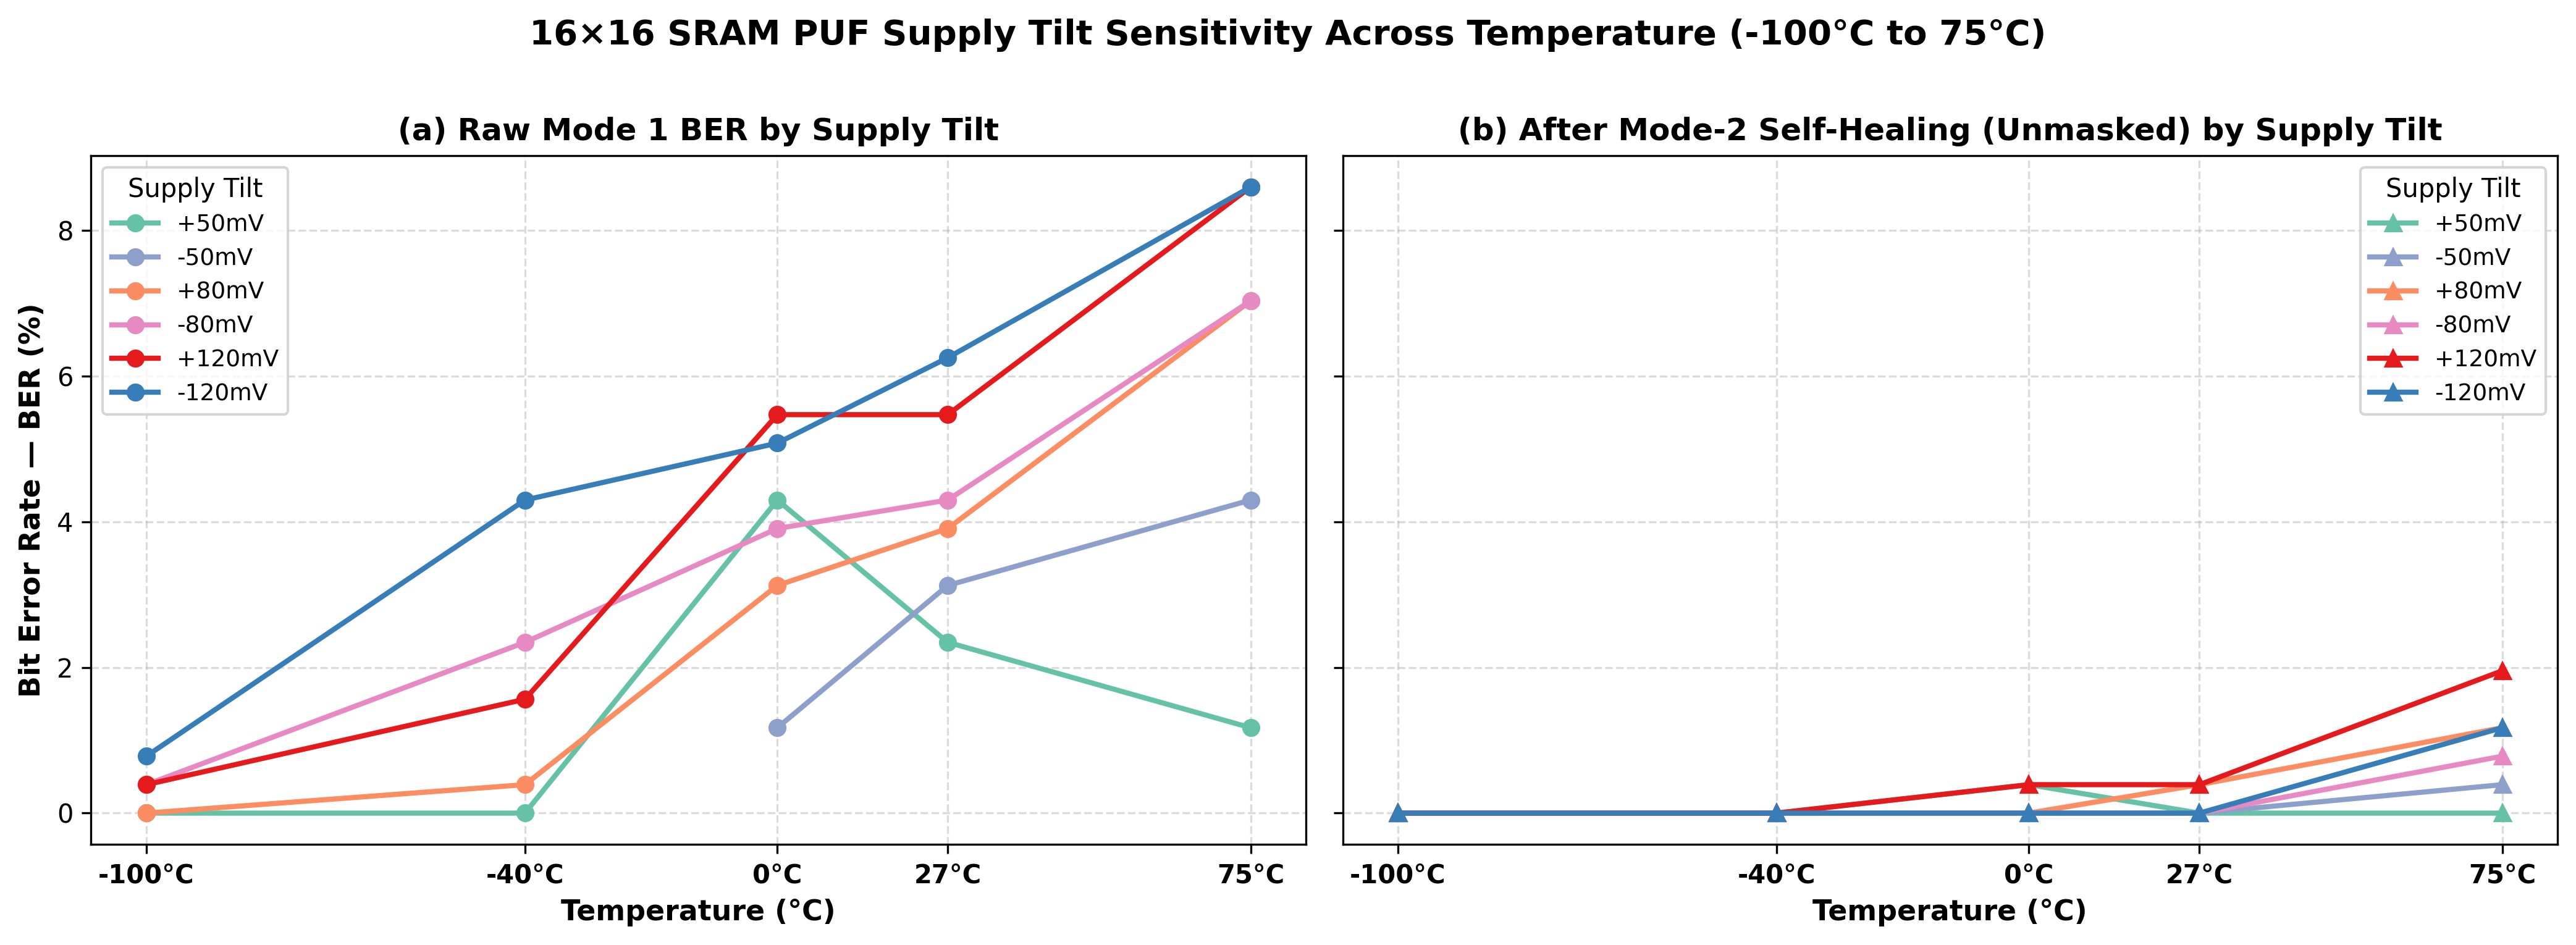

In [33]:
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CONFIGURATION: EXPLICIT CSV FILE NAMES (16 x 16 = 256 CELLS AT ALL TEMPS)
# ==============================================================================
VDD_NOMINAL = 0.9
MODE2_WINDOW = (37e-9, 43e-9)   # Mode 2 active window: 37ns - 43ns
MODE1_WINDOW = (97e-9, 103e-9)  # Mode 1 active window: 97ns - 103ns

TILT_ORDER = ["+50mV", "-50mV", "+80mV", "-80mV", "+120mV", "-120mV"]

TEMPERATURE_FILES = {
    -100: {
        "Nominal": "mc_-100_256_0.9_vdd.csv",
        "+50mV":   "mc_-100_256_0.9_vdd+50.csv",
        "+80mV":   "mc_-100_256_0.9_vdd+80.csv",
        "+120mV":  "mc_-100_256_0.9_vdd+120.csv",
        "-50mV":   "mc_-100_256_0.9_vdd-50.csv",
        "-80mV":   "mc_-100_256_0.9_vdd-80.csv",
        "-120mV":  "mc_-100_256_0.9_vdd-120.csv",
    },
    -40: {
        "Nominal": "mc_-40_256_0.9_vdd.csv",
        "+50mV":   "mc_-40_256_0.9_vdd+50.csv",
        "+80mV":   "mc_-40_256_0.9_vdd+80.csv",
        "+120mV":  "mc_-40_256_0.9_vdd+120.csv",
        "-50mV":   "mc_-40_256_0.9_vdd-50.csv",
        "-80mV":   "mc_-40_256_0.9_vdd-80.csv",
        "-120mV":  "mc_-40_256_0.9_vdd-120.csv",
    },
    0: {
        "Nominal": "mc_0_256_0.9_vdd.csv",
        "+50mV":   "mc_0_256_0.9_vdd+50.csv",
        "+80mV":   "mc_0_256_0.9_vdd+80.csv",
        "+120mV":  "mc_0_256_0.9_vdd+120.csv",
        "-50mV":   "mc_0_256_0.9_vdd-50.csv",
        "-80mV":   "mc_0_256_0.9_vdd-80.csv",
        "-120mV":  "mc_0_256_0.9_vdd-120.csv",
    },
    27: {
        # Room temperature (27°C) 256-cell CSVs without temperature in filename
        "Nominal": "mc_256_0.9_vdd.csv",
        "+50mV":   "mc_256_0.9_vdd+50.csv",
        "+80mV":   "mc_256_0.9_vdd+80.csv",
        "+120mV":  "mc_256_0.9_vdd+120.csv",
        "-50mV":   "mc_256_0.9_vdd-50.csv",
        "-80mV":   "mc_256_0.9_vdd-80.csv",
        "-120mV":  "mc_256_0.9_vdd-120.csv",
    },
    75: {
        # 75°C uses uppercase 'VDD' in file naming
        "Nominal": "mc_75_256_0.9_VDD.csv",
        "+50mV":   "mc_75_256_0.9_VDD+50.csv",
        "+80mV":   "mc_75_256_0.9_VDD+80.csv",
        "+120mV":  "mc_75_256_0.9_VDD+120.csv",
        "-50mV":   "mc_75_256_0.9_VDD-50.csv",
        "-80mV":   "mc_75_256_0.9_VDD-80.csv",
        "-120mV":  "mc_75_256_0.9_VDD-120.csv",
    },
}


# ==============================================================================
# 2. HELPER FUNCTIONS
# ==============================================================================
def extract_bits(csv_path, target_temp=None, vdd=0.9):
    """Reads /BL (or complementary /BLb if /BL was omitted in Cadence export)
    and filters by target_temp if multiple temperature sweeps exist in one CSV.
    """
    all_cols = pd.read_csv(csv_path, nrows=0).columns.tolist()
    threshold = vdd / 2.0

    bl_cols = [c for c in all_cols if re.search(r"(?:^|/)BL\s*\(", c.strip())]
    blb_cols = [c for c in all_cols if re.search(r"(?:^|/)BLb\s*\(", c.strip())]

    use_inverted_blb = False
    candidate_cols = bl_cols
    if not candidate_cols and blb_cols:
        candidate_cols = blb_cols
        use_inverted_blb = True

    if not candidate_cols:
        raise ValueError(f"No '/BL' or '/BLb' columns found in {csv_path}.")

    temps_in_cols = set(
        re.findall(r"temperature=([^,)]+)", " ".join(candidate_cols))
    )
    if len(temps_in_cols) > 1 and target_temp is not None:
        t_str = str(target_temp)
        filtered = [
            c
            for c in candidate_cols
            if f"temperature={t_str}," in c or f"temperature={t_str})" in c
        ]
        if filtered:
            candidate_cols = filtered

    df = pd.read_csv(csv_path, usecols=candidate_cols, low_memory=False)

    col_map = {}
    for c in df.columns:
        c_clean = c.strip()
        m_id = re.search(r"mcparamset=(\d+)", c_clean)
        if not m_id:
            continue
        mc_id = int(m_id.group(1))
        if c_clean.endswith(" X"):
            col_map.setdefault(mc_id, {})["X"] = c
        elif c_clean.endswith(" Y"):
            col_map.setdefault(mc_id, {})["Y"] = c

    paramset_ids = sorted(col_map.keys())
    m1_bits = np.zeros(len(paramset_ids), dtype=int)
    m2_bits = np.zeros(len(paramset_ids), dtype=int)

    for idx, mc_id in enumerate(paramset_ids):
        t_bl = pd.to_numeric(df[col_map[mc_id]["X"]], errors="coerce").values
        v_bl = pd.to_numeric(df[col_map[mc_id]["Y"]], errors="coerce").values

        v1 = np.nanmean(v_bl[(t_bl >= MODE1_WINDOW[0]) & (t_bl <= MODE1_WINDOW[1])])
        v2 = np.nanmean(v_bl[(t_bl >= MODE2_WINDOW[0]) & (t_bl <= MODE2_WINDOW[1])])

        if use_inverted_blb:
            m1_bits[idx] = 1 if v1 < threshold else 0
            m2_bits[idx] = 1 if v2 < threshold else 0
        else:
            m1_bits[idx] = 1 if v1 >= threshold else 0
            m2_bits[idx] = 1 if v2 >= threshold else 0

    return m1_bits, m2_bits


def ber_to_bler_pct(ber_pct, block_size):
    """Converts BER (%) to N-bit Block Error Rate BLER (%): 1 - (1 - BER)^N."""
    p_err = np.clip(ber_pct / 100.0, 0.0, 1.0)
    return (1.0 - (1.0 - p_err) ** block_size) * 100.0


# ==============================================================================
# 3. MAIN BER & BLER ANALYSIS + TEMPERATURE PLOTS
# ==============================================================================
def run_ber_bler_vs_temperature():
    overall_records = []
    per_tilt_records = []
    nom_responses = {}

    for temp_c, file_dict in TEMPERATURE_FILES.items():
        nom_path = file_dict["Nominal"]
        if not os.path.exists(nom_path):
            raise FileNotFoundError(f"Nominal file missing for {temp_c}°C: {nom_path}")
        nom_responses[temp_c] = extract_bits(
            nom_path, target_temp=temp_c, vdd=VDD_NOMINAL
        )

    m1_ref_27, m2_ref_27 = nom_responses[27]

    for temp_c, file_dict in TEMPERATURE_FILES.items():
        m1_nom, m2_nom = nom_responses[temp_c]
        n_cells = len(m1_nom)

        temp_drift_m1_ber = np.sum(m1_nom != m1_ref_27) / n_cells * 100.0
        temp_drift_m2_ber = np.sum(m2_nom != m2_ref_27) / n_cells * 100.0

        available_tilts = {}
        for tilt in TILT_ORDER:
            path = file_dict[tilt]
            if os.path.exists(path):
                available_tilts[tilt] = extract_bits(
                    path, target_temp=temp_c, vdd=VDD_NOMINAL
                )
            else:
                print(f"  [Note] Optional tilt file not found (skipped): {path}")

        m1_stable = np.ones(n_cells, dtype=bool)
        m2_stable = np.ones(n_cells, dtype=bool)
        for tilt, (m1_t, m2_t) in available_tilts.items():
            m1_stable &= m1_nom == m1_t
            m2_stable &= m2_nom == m2_t

        m1_unstable = ~m1_stable
        repaired_mask = m1_unstable & m2_stable
        valid_mask = m1_stable | repaired_mask
        n_valid = int(np.sum(valid_mask))

        healed_nom = np.where(m1_stable, m1_nom, m2_nom)

        m1_bers = []
        m2_bers = []
        healed_bers = []
        post_presel_bers = []

        print("\n" + "=" * 82)
        print(
            f"  TEMPERATURE = {temp_c}°C  (16×16 = {n_cells} Cells | {n_valid} Valid Bits | "
            f"Nom Drift vs 27°C: {temp_drift_m1_ber:.2f}%)"
        )
        print("=" * 82)
        print(f"{'Tilt Corner':<12} | {'Raw M1 BER':>11} | {'Raw M2 BER':>11} | {'Healed BER':>11} | {'Final BER':>10}")
        print("-" * 82)

        for tilt in TILT_ORDER:
            if tilt not in available_tilts:
                per_tilt_records.append(
                    {
                        "Temp_C": temp_c,
                        "Tilt": tilt,
                        "Raw_M1_BER_Pct": np.nan,
                        "Raw_M2_BER_Pct": np.nan,
                        "Healed_Unmasked_BER_Pct": np.nan,
                        "Final_Valid_BER_Pct": np.nan,
                    }
                )
                continue

            m1_t, m2_t = available_tilts[tilt]
            healed_t = np.where(m1_stable, m1_t, m2_t)

            ber_m1 = np.sum(m1_nom != m1_t) / n_cells * 100.0
            ber_m2 = np.sum(m2_nom != m2_t) / n_cells * 100.0
            ber_heal = np.sum(healed_nom != healed_t) / n_cells * 100.0
            ber_final = (
                np.sum(healed_nom[valid_mask] != healed_t[valid_mask]) / n_valid * 100.0
                if n_valid > 0
                else 0.0
            )

            m1_bers.append(ber_m1)
            m2_bers.append(ber_m2)
            healed_bers.append(ber_heal)
            post_presel_bers.append(ber_final)

            print(
                f"{tilt:<12} | {ber_m1:10.2f}% | {ber_m2:10.2f}% | {ber_heal:10.2f}% | {ber_final:9.2f}%"
            )

            per_tilt_records.append(
                {
                    "Temp_C": temp_c,
                    "Tilt": tilt,
                    "Raw_M1_BER_Pct": ber_m1,
                    "Raw_M2_BER_Pct": ber_m2,
                    "Healed_Unmasked_BER_Pct": ber_heal,
                    "Final_Valid_BER_Pct": ber_final,
                }
            )

        mean_m1_ber = float(np.mean(m1_bers))
        mean_m2_ber = float(np.mean(m2_bers))
        mean_heal_ber = float(np.mean(healed_bers))
        mean_final_ber = float(np.mean(post_presel_bers))

        print("-" * 82)
        print(
            f"{'MEAN (Tilts)':<12} | {mean_m1_ber:10.2f}% | {mean_m2_ber:10.2f}% | {mean_heal_ber:10.2f}% | {mean_final_ber:9.2f}%"
        )
        print(
            f"{'128b BLER':<12} | {ber_to_bler_pct(mean_m1_ber, 128):10.2f}% | "
            f"{ber_to_bler_pct(mean_m2_ber, 128):10.2f}% | "
            f"{ber_to_bler_pct(mean_heal_ber, 128):10.2f}% | "
            f"{ber_to_bler_pct(mean_final_ber, 128):9.2f}%"
        )
        print(
            f"{'256b BLER':<12} | {ber_to_bler_pct(mean_m1_ber, 256):10.2f}% | "
            f"{ber_to_bler_pct(mean_m2_ber, 256):10.2f}% | "
            f"{ber_to_bler_pct(mean_heal_ber, 256):10.2f}% | "
            f"{ber_to_bler_pct(mean_final_ber, 256):9.2f}%"
        )
        print("=" * 82)

        overall_records.append(
            {
                "Temp_C": temp_c,
                "Total_Cells": n_cells,
                "Valid_Cells": n_valid,
                "Temp_Drift_vs_27C_M1_BER_Pct": temp_drift_m1_ber,
                "Temp_Drift_vs_27C_M2_BER_Pct": temp_drift_m2_ber,
                "Mean_Raw_M1_BER_Pct": mean_m1_ber,
                "Mean_Raw_M2_BER_Pct": mean_m2_ber,
                "Mean_Healed_Unmasked_BER_Pct": mean_heal_ber,
                "Mean_Final_Valid_BER_Pct": mean_final_ber,
                "Raw_M1_BLER_128b_Pct": ber_to_bler_pct(mean_m1_ber, 128),
                "Healed_BLER_128b_Pct": ber_to_bler_pct(mean_heal_ber, 128),
                "Final_BLER_128b_Pct": ber_to_bler_pct(mean_final_ber, 128),
                "Raw_M1_BLER_256b_Pct": ber_to_bler_pct(mean_m1_ber, 256),
                "Healed_BLER_256b_Pct": ber_to_bler_pct(mean_heal_ber, 256),
                "Final_BLER_256b_Pct": ber_to_bler_pct(mean_final_ber, 256),
            }
        )

    df_overall = pd.DataFrame(overall_records)
    df_tilts = pd.DataFrame(per_tilt_records)

    df_overall.to_csv("puf_16x16_ber_bler_vs_temperature.csv", index=False)
    df_tilts.to_csv("puf_16x16_ber_per_tilt_vs_temperature.csv", index=False)
    print("\nSaved summary CSVs -> 'puf_16x16_ber_bler_vs_temperature.csv' & 'puf_16x16_ber_per_tilt_vs_temperature.csv'")

    # ==========================================================================
    # 4. PLOT 1: MEAN BER & 128-BIT BLER VARIATION WITH TEMPERATURE
    # ==========================================================================
    temps = df_overall["Temp_C"].values

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.2), dpi=300)

    ax1.plot(temps, df_overall["Mean_Raw_M1_BER_Pct"], "o-", lw=2.2, ms=7, color="#D95F02", label="Raw Mode 1 (Supply Tilts)")
    ax1.plot(temps, df_overall["Mean_Raw_M2_BER_Pct"], "s--", lw=2.0, ms=6.5, color="#7570B3", label="Raw Mode 2 (Supply Tilts)")
    ax1.plot(temps, df_overall["Mean_Healed_Unmasked_BER_Pct"], "^-", lw=2.2, ms=7.5, color="#1B9E77", label="Mode-2 Self-Healing (No Masking)")
    ax1.plot(temps, df_overall["Temp_Drift_vs_27C_M1_BER_Pct"], "x:", lw=2.0, ms=7, color="#E7298A", label="Nominal Temp Drift vs. 27°C")
    ax1.plot(temps, df_overall["Mean_Final_Valid_BER_Pct"], "D-", lw=2.2, ms=6.5, color="#000000", label="Preselection + Self-Healing")

    ax1.set_title("(a) Bit Error Rate (BER) vs. Temperature", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Temperature (°C)", fontsize=11, fontweight="bold")
    ax1.set_ylabel("BER (%)", fontsize=11, fontweight="bold")
    ax1.set_xticks(temps)
    ax1.set_xticklabels([f"{t}°C" for t in temps], fontweight="bold")
    ax1.grid(True, linestyle="--", alpha=0.45)
    ax1.legend(loc="best", fontsize=9, frameon=True)

    ax2.plot(temps, df_overall["Raw_M1_BLER_128b_Pct"], "o-", lw=2.2, ms=7, color="#D95F02", label="Raw Mode 1 (128-bit BLER)")
    ax2.plot(temps, df_overall["Healed_BLER_128b_Pct"], "^-", lw=2.2, ms=7.5, color="#1B9E77", label="Mode-2 Self-Healing (128-bit BLER)")
    ax2.plot(temps, df_overall["Final_BLER_128b_Pct"], "D-", lw=2.2, ms=6.5, color="#000000", label="Preselection + Self-Healing (128-bit BLER)")

    ax2.set_title("(b) 128-Bit Block Error Rate (BLER) vs. Temperature", fontsize=12, fontweight="bold")
    ax2.set_xlabel("Temperature (°C)", fontsize=11, fontweight="bold")
    ax2.set_ylabel("128-Bit BLER (%)", fontsize=11, fontweight="bold")
    ax2.set_xticks(temps)
    ax2.set_xticklabels([f"{t}°C" for t in temps], fontweight="bold")
    ax2.set_ylim(-4, 108)
    ax2.grid(True, linestyle="--", alpha=0.45)
    ax2.legend(loc="best", fontsize=9, frameon=True)

    plt.suptitle("16×16 SRAM PUF Reliability Across Temperature (-100°C to 75°C)", fontsize=13.5, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig("puf_16x16_ber_bler_vs_temperature.png", dpi=300, bbox_inches="tight")
    print("Saved BER & BLER vs. Temperature plot -> 'puf_16x16_ber_bler_vs_temperature.png'")
    plt.show()

    # ==========================================================================
    # 5. PLOT 2: PER-TILT CORNER BER (±50mV, ±80mV, ±120mV) VS. TEMPERATURE
    # ==========================================================================
    fig, (ax_raw, ax_heal) = plt.subplots(1, 2, figsize=(14, 5), dpi=300, sharey=True)
    tilt_colors = {
        "+50mV": "#66C2A5",
        "-50mV": "#8DA0CB",
        "+80mV": "#FC8D62",
        "-80mV": "#E78AC3",
        "+120mV": "#E41A1C",
        "-120mV": "#377EB8",
    }

    for tilt in TILT_ORDER:
        sub = df_tilts[df_tilts["Tilt"] == tilt].sort_values("Temp_C")
        ax_raw.plot(
            sub["Temp_C"],
            sub["Raw_M1_BER_Pct"],
            marker="o",
            lw=2,
            color=tilt_colors[tilt],
            label=tilt,
        )
        ax_heal.plot(
            sub["Temp_C"],
            sub["Healed_Unmasked_BER_Pct"],
            marker="^",
            lw=2,
            color=tilt_colors[tilt],
            label=tilt,
        )

    ax_raw.set_title("(a) Raw Mode 1 BER by Supply Tilt", fontsize=12, fontweight="bold")
    ax_raw.set_xlabel("Temperature (°C)", fontsize=11, fontweight="bold")
    ax_raw.set_ylabel("Bit Error Rate — BER (%)", fontsize=11, fontweight="bold")
    ax_raw.set_xticks(temps)
    ax_raw.set_xticklabels([f"{t}°C" for t in temps], fontweight="bold")
    ax_raw.grid(True, linestyle="--", alpha=0.45)
    ax_raw.legend(title="Supply Tilt", fontsize=9, frameon=True)

    ax_heal.set_title("(b) After Mode-2 Self-Healing (Unmasked) by Supply Tilt", fontsize=12, fontweight="bold")
    ax_heal.set_xlabel("Temperature (°C)", fontsize=11, fontweight="bold")
    ax_heal.set_xticks(temps)
    ax_heal.set_xticklabels([f"{t}°C" for t in temps], fontweight="bold")
    ax_heal.grid(True, linestyle="--", alpha=0.45)
    ax_heal.legend(title="Supply Tilt", fontsize=9, frameon=True)

    plt.suptitle("16×16 SRAM PUF Supply Tilt Sensitivity Across Temperature (-100°C to 75°C)", fontsize=13.5, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig("puf_16x16_tilt_ber_vs_temperature.png", dpi=300, bbox_inches="tight")
    print("Saved per-tilt BER vs. Temperature plot -> 'puf_16x16_tilt_ber_vs_temperature.png'")
    plt.show()


if __name__ == "__main__":
    run_ber_bler_vs_temperature()